In [ ]:
# 1. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
   from google.colab import drive
   drive.mount('/content/drive', force_remount=True)

MessageError: Error: credential propagation was unsuccessful

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True, timeout_ms=120000)

Mounted at /content/drive


In [ ]:
# 2. Set up a folder in Drive for the dataset
import os
dataset_dir = '/content/drive/MyDrive/mlkem_dataset'
os.makedirs(dataset_dir, exist_ok=True)

In [ ]:
# 3. Download the dataset directly into Drive
!wget -O "{dataset_dir}/d0nj0n_mlkem_dataset.zip" \
  "https://pub-3483b4c265914de3a2a27c0a3b2076ee.r2.dev/d0nj0n_mlkem_dataset.zip"

--2026-09-22 19:21:50--  https://pub-3483b4c265914de3a2a27c0a3b2076ee.r2.dev/d0nj0n_mlkem_dataset.zip
Resolving pub-3483b4c265914de3a2a27c0a3b2076ee.r2.dev (pub-3483b4c265914de3a2a27c0a3b2076ee.r2.dev)... 104.18.50.34, 104.18.54.45, 2606:4700:311b::6812:362d, ...
Connecting to pub-3483b4c265914de3a2a27c0a3b2076ee.r2.dev (pub-3483b4c265914de3a2a27c0a3b2076ee.r2.dev)|104.18.50.34|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 13494522554 (13G) [application/zip]
Saving to: ‘/content/drive/MyDrive/mlkem_dataset/d0nj0n_mlkem_dataset.zip’

/content/drive/MyDr 100%[===================>]  12.57G  46.3MB/s    in 6m 7s   

2026-09-22 19:27:57 (35.1 MB/s) - ‘/content/drive/MyDrive/mlkem_dataset/d0nj0n_mlkem_dataset.zip’ saved [13494522554/13494522554]



In [ ]:
# 4. Check the download completed and its size
!ls -lh "{dataset_dir}/d0nj0n_mlkem_dataset.zip"

-rw------- 1 root root 13G Jun 18 11:59 /content/drive/MyDrive/mlkem_dataset/d0nj0n_mlkem_dataset.zip


In [ ]:
# 5. Extract it (also into Drive, so it persists)
!unzip -q "{dataset_dir}/d0nj0n_mlkem_dataset.zip" -d "{dataset_dir}/extracted"

In [ ]:
# 6. Inspect the folder structure
!find "{dataset_dir}/extracted" -maxdepth 3 -type d

/content/drive/MyDrive/mlkem_dataset/extracted
/content/drive/MyDrive/mlkem_dataset/extracted/d0nj0n_mlkem_dataset
/content/drive/MyDrive/mlkem_dataset/extracted/d0nj0n_mlkem_dataset/masked
/content/drive/MyDrive/mlkem_dataset/extracted/d0nj0n_mlkem_dataset/pqm4-ref
/content/drive/MyDrive/mlkem_dataset/extracted/d0nj0n_mlkem_dataset/pqm4-ref/pqm4
/content/drive/MyDrive/mlkem_dataset/extracted/d0nj0n_mlkem_dataset/pqm4-ref/ref


In [ ]:
# 7. Check for README files and print them
import glob
for readme in glob.glob(f"{dataset_dir}/extracted/**/README*", recursive=True):
    print(f"\n{'='*60}\n{readme}\n{'='*60}")
    print(open(readme).read())


/content/drive/MyDrive/mlkem_dataset/extracted/d0nj0n_mlkem_dataset/masked/README.md
# Masked Kyber capture format

- **`100k_capture_fixedkey_all/`** — fixed-key: one secret key reused for all 100 000 traces.
- **`100k_capture_all_2/`** - variable-key: a fresh key per trace.

Both are **identical in structure**. The *only* difference is the key: the fixed-key
capture adds a single `metadata/fixed_unmasked_key.npy`; the variable-key capture has no
such file because every trace carries its own (masked) key in `masked_keys_{i}.npy`.

The target is the masked Kyber768 (ML-KEM-768, `q = 3329`) basemul `a · b`, captured for one
polynomial. **In this implementation, `a` contains public data (the ciphertext) and `b` contains secret key data**. `b` is arithmetically masked into two shares (`b = b_s0 + b_s1 mod q`), and each
share's basemul is recorded under its own trigger.

## Directory tree

```
100k_capture_fixedkey_all/          100k_capture_all_2/
├── traces/                         ├── 

In [ ]:
# 8. Confirm shapes of the key arrays for one implementation (e.g. reference/fixed)
import numpy as np
sample_dir = f"{dataset_dir}/extracted/reference/fixed"  # adjust if folder names differ
if os.path.exists(sample_dir):
    for f in sorted(os.listdir(sample_dir)):
        if f.endswith('.npy'):
            arr = np.load(os.path.join(sample_dir, f), mmap_mode='r')
            print(f"{f}: shape={arr.shape}, dtype={arr.dtype}")

In [ ]:
# Check one level deeper into each implementation
!find "{dataset_dir}/extracted/d0nj0n_mlkem_dataset" -maxdepth 4 -type d

# Print any README files found anywhere in the tree
import glob
for readme in glob.glob(f"{dataset_dir}/extracted/**/README*", recursive=True):
    print(f"\n{'='*60}\n{readme}\n{'='*60}")
    print(open(readme).read())

# Check array shapes for the masked implementation, fixed scenario
import numpy as np, os
sample_dir = f"{dataset_dir}/extracted/d0nj0n_mlkem_dataset/masked/fixed"
if os.path.exists(sample_dir):
    for f in sorted(os.listdir(sample_dir)):
        full = os.path.join(sample_dir, f)
        if f.endswith('.npy'):
            arr = np.load(full, mmap_mode='r')
            print(f"{f}: shape={arr.shape}, dtype={arr.dtype}")
        elif os.path.isdir(full):
            print(f"[dir] {f}/")

/content/drive/MyDrive/mlkem_dataset/extracted/d0nj0n_mlkem_dataset
/content/drive/MyDrive/mlkem_dataset/extracted/d0nj0n_mlkem_dataset/masked
/content/drive/MyDrive/mlkem_dataset/extracted/d0nj0n_mlkem_dataset/pqm4-ref
/content/drive/MyDrive/mlkem_dataset/extracted/d0nj0n_mlkem_dataset/pqm4-ref/pqm4
/content/drive/MyDrive/mlkem_dataset/extracted/d0nj0n_mlkem_dataset/pqm4-ref/pqm4/fixed_key
/content/drive/MyDrive/mlkem_dataset/extracted/d0nj0n_mlkem_dataset/pqm4-ref/pqm4/fixed_key/leakages
/content/drive/MyDrive/mlkem_dataset/extracted/d0nj0n_mlkem_dataset/pqm4-ref/pqm4/fixed_key/metadata
/content/drive/MyDrive/mlkem_dataset/extracted/d0nj0n_mlkem_dataset/pqm4-ref/pqm4/variable_key
/content/drive/MyDrive/mlkem_dataset/extracted/d0nj0n_mlkem_dataset/pqm4-ref/pqm4/variable_key/leakages
/content/drive/MyDrive/mlkem_dataset/extracted/d0nj0n_mlkem_dataset/pqm4-ref/pqm4/variable_key/metadata
/content/drive/MyDrive/mlkem_dataset/extracted/d0nj0n_mlkem_dataset/pqm4-ref/pqm4/selective_b
/conten

In [ ]:
import numpy as np, os

def inspect(path):
    if not os.path.exists(path):
        print(f"[missing] {path}")
        return
    print(f"\n--- {path} ---")
    for f in sorted(os.listdir(path)):
        full = os.path.join(path, f)
        if f.endswith('.npy'):
            arr = np.load(full, mmap_mode='r')
            print(f"  {f}: shape={arr.shape}, dtype={arr.dtype}")
        elif os.path.isdir(full):
            print(f"  [dir] {f}/")

base = f"{dataset_dir}/extracted/d0nj0n_mlkem_dataset/pqm4-ref"

inspect(f"{base}/pqm4/fixed_key/leakages")
inspect(f"{base}/pqm4/fixed_key/metadata")
inspect(f"{base}/ref/fixed_key/leakages")
inspect(f"{base}/ref/fixed_key/metadata")
inspect(f"{base}/pqm4/selective_b/leakages")
inspect(f"{base}/pqm4/selective_b/metadata")


--- /content/drive/MyDrive/mlkem_dataset/extracted/d0nj0n_mlkem_dataset/pqm4-ref/pqm4/fixed_key/leakages ---
  traces_0.npy: shape=(10000, 20000), dtype=int16
  traces_1.npy: shape=(10000, 20000), dtype=int16
  traces_10.npy: shape=(10000, 20000), dtype=int16
  traces_11.npy: shape=(10000, 20000), dtype=int16
  traces_12.npy: shape=(10000, 20000), dtype=int16
  traces_13.npy: shape=(10000, 20000), dtype=int16
  traces_14.npy: shape=(10000, 20000), dtype=int16
  traces_15.npy: shape=(10000, 20000), dtype=int16
  traces_16.npy: shape=(10000, 20000), dtype=int16
  traces_17.npy: shape=(10000, 20000), dtype=int16
  traces_18.npy: shape=(10000, 20000), dtype=int16
  traces_19.npy: shape=(10000, 20000), dtype=int16
  traces_2.npy: shape=(10000, 20000), dtype=int16
  traces_3.npy: shape=(10000, 20000), dtype=int16
  traces_4.npy: shape=(10000, 20000), dtype=int16
  traces_5.npy: shape=(10000, 20000), dtype=int16
  traces_6.npy: shape=(10000, 20000), dtype=int16
  traces_7.npy: shape=(10000, 

In [ ]:
import numpy as np

base = f"{dataset_dir}/extracted/d0nj0n_mlkem_dataset"

# ---------------------------------------------------------
# 1. Verify ref's mult_a/mult_b byte-reinterpretation hypothesis
# ---------------------------------------------------------
print("=== ref: byte-reinterpretation check ===")
ref_mult_a_raw = np.load(f"{base}/pqm4-ref/ref/fixed_key/metadata/mult_a_0.npy")
print("raw shape/dtype:", ref_mult_a_raw.shape, ref_mult_a_raw.dtype)

# View as int16 (little-endian, numpy default on most platforms)
ref_mult_a_as_int16 = ref_mult_a_raw.view(np.int16)
print("reinterpreted shape/dtype:", ref_mult_a_as_int16.shape, ref_mult_a_as_int16.dtype)
print("min/max:", ref_mult_a_as_int16.min(), ref_mult_a_as_int16.max())
print("first row, first 10 values:", ref_mult_a_as_int16[0, :10])

=== ref: byte-reinterpretation check ===
raw shape/dtype: (10000, 512) uint8
reinterpreted shape/dtype: (10000, 256) int16
min/max: 0 3299
first row, first 10 values: [1026  493  831 2479 2652  924 1914  616 3158 2360]


In [ ]:
import numpy as np

base = f"{dataset_dir}/extracted/d0nj0n_mlkem_dataset"

# ---------------------------------------------------------
# 1. Verify ref's mult_a/mult_b byte-reinterpretation hypothesis
# ---------------------------------------------------------
print("=== ref: byte-reinterpretation check ===")
ref_mult_a_raw = np.load(f"{base}/pqm4-ref/ref/fixed_key/metadata/mult_a_0.npy")
print("raw shape/dtype:", ref_mult_a_raw.shape, ref_mult_a_raw.dtype)

# View as int16 (little-endian, numpy default on most platforms)
ref_mult_a_as_int16 = ref_mult_a_raw.view(np.int16)
print("reinterpreted shape/dtype:", ref_mult_a_as_int16.shape, ref_mult_a_as_int16.dtype)
print("min/max:", ref_mult_a_as_int16.min(), ref_mult_a_as_int16.max())
print("first row, first 10 values:", ref_mult_a_as_int16[0, :10])

# q = 3329 for Kyber/ML-KEM — coefficients should fall in [0, q-1] or a centered range
q = 3329
in_range = ((ref_mult_a_as_int16 >= 0) & (ref_mult_a_as_int16 < q)).mean()
print(f"fraction of values in [0, {q}): {in_range:.4f}")

# Try big-endian too, in case native view doesn't line up
ref_mult_a_be = ref_mult_a_raw.view('>i2')  # big-endian int16
in_range_be = ((ref_mult_a_be >= 0) & (ref_mult_a_be < q)).mean()
print(f"[big-endian attempt] fraction in [0, {q}): {in_range_be:.4f}")

=== ref: byte-reinterpretation check ===
raw shape/dtype: (10000, 512) uint8
reinterpreted shape/dtype: (10000, 256) int16
min/max: 0 3299
first row, first 10 values: [1026  493  831 2479 2652  924 1914  616 3158 2360]
fraction of values in [0, 3329): 1.0000
[big-endian attempt] fraction in [0, 3329): 0.0547


In [ ]:
# ---------------------------------------------------------
# 2. Compare against pqm4's directly-decoded mult_a for a sanity check on scale
# ---------------------------------------------------------
print("\n=== pqm4: directly decoded mult_a for comparison ===")
pqm4_mult_a = np.load(f"{base}/pqm4-ref/pqm4/fixed_key/metadata/mult_a_0.npy")
print("shape/dtype:", pqm4_mult_a.shape, pqm4_mult_a.dtype)
print("min/max:", pqm4_mult_a.min(), pqm4_mult_a.max())
print("first row, first 10 values:", pqm4_mult_a[0, :10])


=== pqm4: directly decoded mult_a for comparison ===
shape/dtype: (10000, 256) int16
min/max: 6 3325
first row, first 10 values: [ 679 1286 2560  378 2306  192  276 3251 2325  532]


In [ ]:
# ---------------------------------------------------------
# 3. Confirm "fixed key" assumption: is mult_b constant across rows?
# ---------------------------------------------------------
print("=== Checking mult_b constancy across rows (fixed_key scenario) ===")

def check_constant(path, label, n_check=200, reinterpret_int16=False):
    arr = np.load(path, mmap_mode='r')
    sample = np.array(arr[:n_check])
    if reinterpret_int16:
        sample = sample.view(np.int16)
    n_unique_rows = len(np.unique(sample, axis=0))
    print(f"{label}: shape={arr.shape}, unique rows among first {n_check} = {n_unique_rows}")
    if n_unique_rows == 1:
        print(f"  -> CONFIRMED constant (fixed key holds)")
    else:
        print(f"  -> NOT constant — investigate further")

check_constant(f"{base}/pqm4-ref/pqm4/fixed_key/metadata/mult_b_0.npy", "pqm4 mult_b")
check_constant(f"{base}/pqm4-ref/ref/fixed_key/metadata/mult_b_0.npy", "ref mult_b (raw bytes)", reinterpret_int16=True)
check_constant(f"{base}/masked/100k_capture_fixedkey_all/metadata/bp_s0_0.npy", "masked bp_s0")
check_constant(f"{base}/masked/100k_capture_fixedkey_all/metadata/bp_s1_0.npy", "masked bp_s1")

# ---------------------------------------------------------
# 4. For masked: confirm bp_s0 + bp_s1 mod q reconstructs a value consistent
#    with the documented fixed_unmasked_key.npy
# ---------------------------------------------------------
print("\n=== Masked: verify share reconstruction ===")
q = 3329
bp_s0 = np.load(f"{base}/masked/100k_capture_fixedkey_all/metadata/bp_s0_0.npy")
bp_s1 = np.load(f"{base}/masked/100k_capture_fixedkey_all/metadata/bp_s1_0.npy")
reconstructed = (bp_s0[0].astype(np.int32) + bp_s1[0].astype(np.int32)) % q
print("reconstructed b (first 10 coeffs):", reconstructed[:10])

fixed_key = np.load(f"{base}/masked/100k_capture_fixedkey_all/metadata/fixed_unmasked_key.npy")
print("fixed_unmasked_key shape:", fixed_key.shape, fixed_key.dtype)
print("first 20 raw bytes:", fixed_key[:20])

=== Checking mult_b constancy across rows (fixed_key scenario) ===
pqm4 mult_b: shape=(10000, 256), unique rows among first 200 = 200
  -> NOT constant — investigate further
ref mult_b (raw bytes): shape=(10000, 512), unique rows among first 200 = 200
  -> NOT constant — investigate further


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/mlkem_dataset/extracted/d0nj0n_mlkem_dataset/masked/100k_capture_fixedkey_all/metadata/bp_s0_0.npy'

In [ ]:
# Check mult_a constancy for pqm4/ref (testing the flipped-convention hypothesis)
print("=== Checking mult_a constancy ===")
check_constant(f"{base}/pqm4-ref/pqm4/fixed_key/metadata/mult_a_0.npy", "pqm4 mult_a")
check_constant(f"{base}/pqm4-ref/ref/fixed_key/metadata/mult_a_0.npy", "ref mult_a (raw bytes)", reinterpret_int16=True)

# List the actual masked folder structure to fix the path
import os
masked_dir = f"{base}/masked"
print("\n=== Actual masked/ contents ===")
for root, dirs, files in os.walk(masked_dir):
    depth = root.replace(masked_dir, '').count(os.sep)
    if depth <= 2:
        print(root)
        for f in files[:5]:
            print("   ", f)

=== Checking mult_a constancy ===
pqm4 mult_a: shape=(10000, 256), unique rows among first 200 = 1
  -> CONFIRMED constant (fixed key holds)
ref mult_a (raw bytes): shape=(10000, 512), unique rows among first 200 = 1
  -> CONFIRMED constant (fixed key holds)

=== Actual masked/ contents ===
/content/drive/MyDrive/mlkem_dataset/extracted/d0nj0n_mlkem_dataset/masked
    100k_capture_all_2.tar.gz
    ._100k_capture_all_2.tar.gz
    100k_capture_fixedkey_all.tar.gz
    ._100k_capture_fixedkey_all.tar.gz
    README.md


In [ ]:
import subprocess

masked_dir = f"{base}/masked"

for archive in ["100k_capture_fixedkey_all.tar.gz", "100k_capture_all_2.tar.gz"]:
    src = f"{masked_dir}/{archive}"
    print(f"Extracting {archive} ...")
    subprocess.run(["tar", "-xzf", src, "-C", masked_dir], check=True)

print("\nDone. Contents now:")
import os
for f in sorted(os.listdir(masked_dir)):
    print(" ", f)

NameError: name 'base' is not defined

In [ ]:
# 1. Re-mount Drive (this is the only "real work" step you must redo)
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Cell 2: Redefine the path variables (needed since the old runtime's memory is gone)
import os
dataset_dir = '/content/drive/MyDrive/mlkem_dataset'
base = f"{dataset_dir}/extracted/d0nj0n_mlkem_dataset"

# quick check before extracting — confirms the .tar.gz files are still there from yesterday
print(os.listdir(f"{base}/masked"))

['._100k_capture_all_2.tar.gz', '100k_capture_all_2.tar.gz', '100k_capture_fixedkey_all.tar.gz', '._100k_capture_fixedkey_all.tar.gz', 'README.md', '._README.md', '100k_capture_fixedkey_all', '100k_capture_all_2']


In [ ]:
# Cell 3: Your extraction code
import subprocess

masked_dir = f"{base}/masked"

for archive in ["100k_capture_fixedkey_all.tar.gz", "100k_capture_all_2.tar.gz"]:
    src = f"{masked_dir}/{archive}"
    print(f"Extracting {archive} ...")
    subprocess.run(["tar", "-xzf", src, "-C", masked_dir], check=True)

print("\nDone. Contents now:")
for f in sorted(os.listdir(masked_dir)):
    print(" ", f)

Extracting 100k_capture_fixedkey_all.tar.gz ...
Extracting 100k_capture_all_2.tar.gz ...

Done. Contents now:
  ._100k_capture_all_2.tar.gz
  ._100k_capture_fixedkey_all.tar.gz
  ._README.md
  100k_capture_all_2
  100k_capture_all_2.tar.gz
  100k_capture_fixedkey_all
  100k_capture_fixedkey_all.tar.gz
  README.md


In [ ]:
import numpy as np

def check_constant(path, label, n_check=200, reinterpret_int16=False):
    arr = np.load(path, mmap_mode='r')
    sample = np.array(arr[:n_check])
    if reinterpret_int16:
        sample = sample.view(np.int16)
    n_unique_rows = len(np.unique(sample, axis=0))
    print(f"{label}: shape={arr.shape}, unique rows among first {n_check} = {n_unique_rows}")
    print("  -> CONFIRMED constant" if n_unique_rows == 1 else "  -> NOT constant")

fixed_meta = f"{base}/masked/100k_capture_fixedkey_all/metadata"

print("=== Checking bp_s0 / bp_s1 constancy (fixed-key scenario) ===")
check_constant(f"{fixed_meta}/bp_s0_0.npy", "masked bp_s0")
check_constant(f"{fixed_meta}/bp_s1_0.npy", "masked bp_s1")

print("\n=== Verifying share reconstruction ===")
q = 3329
bp_s0 = np.load(f"{fixed_meta}/bp_s0_0.npy")
bp_s1 = np.load(f"{fixed_meta}/bp_s1_0.npy")
reconstructed = (bp_s0[0].astype(np.int32) + bp_s1[0].astype(np.int32)) % q
print("reconstructed b (first 10 coeffs):", reconstructed[:10])

fixed_key = np.load(f"{fixed_meta}/fixed_unmasked_key.npy")
print("fixed_unmasked_key shape:", fixed_key.shape, fixed_key.dtype)
print("first 20 raw bytes:", fixed_key[:20])

=== Checking bp_s0 / bp_s1 constancy (fixed-key scenario) ===
masked bp_s0: shape=(10000, 256), unique rows among first 200 = 200
  -> NOT constant
masked bp_s1: shape=(10000, 256), unique rows among first 200 = 200
  -> NOT constant

=== Verifying share reconstruction ===
reconstructed b (first 10 coeffs): [1681 1422 1038 1248 1486 2180 1628  225  863  632]
fixed_unmasked_key shape: (2400,) uint8
first 20 raw bytes: [145 230  88  14   4  78 206  69 136  92  22  14  95 131  39  86 104  73
 100 130]


In [ ]:
# Check whether the RECONSTRUCTED (unmasked) b is constant across traces,
# even though the individual shares vary
n_check = 200
bp_s0_sample = np.array(bp_s0[:n_check]).astype(np.int32)
bp_s1_sample = np.array(bp_s1[:n_check]).astype(np.int32)
reconstructed_sample = (bp_s0_sample + bp_s1_sample) % q

n_unique = len(np.unique(reconstructed_sample, axis=0))
print(f"Reconstructed b: unique rows among first {n_check} = {n_unique}")
print("  -> CONFIRMED constant (fixed key holds under masking)" if n_unique == 1 else "  -> NOT constant — investigate")

print("\nReconstructed b, row 0, first 10 coeffs:", reconstructed_sample[0][:10])
print("Reconstructed b, row 50, first 10 coeffs:", reconstructed_sample[50][:10])
print("Reconstructed b, row 150, first 10 coeffs:", reconstructed_sample[150][:10])

Reconstructed b: unique rows among first 200 = 1
  -> CONFIRMED constant (fixed key holds under masking)

Reconstructed b, row 0, first 10 coeffs: [1681 1422 1038 1248 1486 2180 1628  225  863  632]
Reconstructed b, row 50, first 10 coeffs: [1681 1422 1038 1248 1486 2180 1628  225  863  632]
Reconstructed b, row 150, first 10 coeffs: [1681 1422 1038 1248 1486 2180 1628  225  863  632]


In [ ]:
import numpy as np

def check_row_alignment(traces_path, metadata_path, label):
    traces = np.load(traces_path, mmap_mode='r')
    metadata = np.load(metadata_path, mmap_mode='r')
    match = traces.shape[0] == metadata.shape[0]
    print(f"{label}: traces rows={traces.shape[0]}, metadata rows={metadata.shape[0]} -> {'MATCH' if match else 'MISMATCH'}")

# masked
check_row_alignment(
    f"{base}/masked/100k_capture_fixedkey_all/traces/traces_s0_0.npy",
    f"{base}/masked/100k_capture_fixedkey_all/metadata/bp_s0_0.npy",
    "masked"
)
# pqm4
check_row_alignment(
    f"{base}/pqm4-ref/pqm4/fixed_key/leakages/traces_0.npy",
    f"{base}/pqm4-ref/pqm4/fixed_key/metadata/mult_a_0.npy",
    "pqm4"
)
# ref
check_row_alignment(
    f"{base}/pqm4-ref/ref/fixed_key/leakages/traces_0.npy",
    f"{base}/pqm4-ref/ref/fixed_key/metadata/mult_a_0.npy",
    "ref"
)

masked: traces rows=10000, metadata rows=10000 -> MATCH
pqm4: traces rows=10000, metadata rows=10000 -> MATCH
ref: traces rows=10000, metadata rows=10000 -> MATCH


In [ ]:
# Load a modest slice of masked traces and their reconstructed secret coefficient 0
n = 2000
traces_s0 = np.load(f"{base}/masked/100k_capture_fixedkey_all/traces/traces_s0_0.npy", mmap_mode='r')[:n]
bp_s0_n = np.load(f"{base}/masked/100k_capture_fixedkey_all/metadata/bp_s0_0.npy", mmap_mode='r')[:n].astype(np.int32)

# Since the share itself is randomized, split traces by Hamming weight of the share
# (a simple, common leakage model check — no CNN needed yet)
def hamming_weight(x):
    return bin(x & 0xFFFF).count('1')

hw = np.array([hamming_weight(int(v)) for v in bp_s0_n[:, 0]])  # coeff 0 of each trace
low_hw = traces_s0[hw <= np.percentile(hw, 25)]
high_hw = traces_s0[hw >= np.percentile(hw, 75)]

mean_diff = low_hw.mean(axis=0) - high_hw.mean(axis=0)
print("Max abs mean difference across trace samples:", np.abs(mean_diff).max())
print("Sample index of max difference:", np.argmax(np.abs(mean_diff)))
print("Overall trace amplitude scale (std across all samples):", traces_s0.std())

Max abs mean difference across trace samples: 4.285010245020564
Sample index of max difference: 510
Overall trace amplitude scale (std across all samples): 11.21735354021709


In [ ]:
import os
checkpoint_dir = f"{dataset_dir}/checkpoints"
os.makedirs(checkpoint_dir, exist_ok=True)

# In Keras, for example:
from tensorflow.keras.callbacks import ModelCheckpoint
checkpoint_cb = ModelCheckpoint(
    filepath=f"{checkpoint_dir}/model_epoch{{epoch:02d}}.keras",
    save_freq='epoch',
    save_best_only=False
)
# pass checkpoint_cb into model.fit(..., callbacks=[checkpoint_cb])

In [ ]:
#date 28th september 2026

# 1. Re-mount Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# 2. Redefine the path variables
import os
dataset_dir = '/content/drive/MyDrive/mlkem_dataset'
base = f"{dataset_dir}/extracted/d0nj0n_mlkem_dataset"

# quick check everything's still there
print(os.path.exists(base))
for f in sorted(os.listdir(f"{base}/masked")):
    print(f)

True
._100k_capture_all_2.tar.gz
._100k_capture_fixedkey_all.tar.gz
._README.md
100k_capture_all_2
100k_capture_all_2.tar.gz
100k_capture_fixedkey_all
100k_capture_fixedkey_all.tar.gz
README.md


In [ ]:
import numpy as np

q = 3329

# ---------------------------------------------------------
# Config: per-implementation paths and how to get the secret value
# ---------------------------------------------------------
IMPL_CONFIG = {
    "masked_s0": {
        "traces": f"{base}/masked/100k_capture_all_2/traces/traces_s0_0.npy",
        "secret_fn": lambda meta_dir: (
            np.load(f"{meta_dir}/bp_s0_0.npy", mmap_mode='r').astype(np.int32),
            np.load(f"{meta_dir}/bp_s1_0.npy", mmap_mode='r').astype(np.int32)
        ),
        "meta_dir": f"{base}/masked/100k_capture_all_2/metadata",
        "reconstruct_masked": True,
    },
    "pqm4": {
        "traces": f"{base}/pqm4-ref/pqm4/variable_key/leakages/traces_0.npy",
        "meta_dir": f"{base}/pqm4-ref/pqm4/variable_key/metadata",
        "secret_file": "mult_a_0.npy",
        "raw_bytes": False,
    },
    "ref": {
        "traces": f"{base}/pqm4-ref/ref/variable_key/leakages/traces_0.npy",
        "meta_dir": f"{base}/pqm4-ref/ref/variable_key/metadata",
        "secret_file": "mult_a_0.npy",
        "raw_bytes": True,  # needs .view(np.int16) reinterpretation
    },
}

def load_secret_coeffs(impl_name, coeff_idx=0, n=20000):
    """Return the secret coefficient (at coeff_idx) for the first n traces."""
    cfg = IMPL_CONFIG[impl_name]
    if cfg.get("reconstruct_masked"):
        s0, s1 = cfg["secret_fn"](cfg["meta_dir"])
        vals = (np.array(s0[:n, coeff_idx]) + np.array(s1[:n, coeff_idx])) % q
    else:
        raw = np.load(f"{cfg['meta_dir']}/{cfg['secret_file']}", mmap_mode='r')[:n]
        if cfg["raw_bytes"]:
            raw = np.array(raw).view(np.int16)
        vals = np.array(raw)[:, coeff_idx].astype(np.int32)
    return vals

def load_traces(impl_name, n=20000):
    cfg = IMPL_CONFIG[impl_name]
    return np.array(np.load(cfg["traces"], mmap_mode='r')[:n])

def hamming_weight_arr(vals, bits=16):
    return np.array([bin(int(v) & ((1 << bits) - 1)).count('1') for v in vals])

# ---------------------------------------------------------
# SNR: signal variance (between HW classes) / noise variance (within classes)
# ---------------------------------------------------------
def compute_snr(traces, hw_labels):
    classes = np.unique(hw_labels)
    class_means = np.array([traces[hw_labels == c].mean(axis=0) for c in classes])
    class_vars = np.array([traces[hw_labels == c].var(axis=0) for c in classes])
    signal_var = class_means.var(axis=0)
    noise_var = class_vars.mean(axis=0)
    return signal_var / (noise_var + 1e-12)

# ---------------------------------------------------------
# TVLA-style Welch's t-test: median-split low-HW vs high-HW groups
# ---------------------------------------------------------
from scipy import stats

def compute_tvla(traces, hw_labels):
    median = np.median(hw_labels)
    low = traces[hw_labels <= median]
    high = traces[hw_labels > median]
    t_stat, _ = stats.ttest_ind(low, high, axis=0, equal_var=False)
    return t_stat

# ---------------------------------------------------------
# Run baseline scoring for one implementation
# ---------------------------------------------------------
def run_baseline(impl_name, coeff_idx=0, n=20000):
    print(f"--- Baseline scoring: {impl_name} ---")
    traces = load_traces(impl_name, n)
    secret = load_secret_coeffs(impl_name, coeff_idx, n)
    hw = hamming_weight_arr(secret)

    snr = compute_snr(traces, hw)
    tvla = compute_tvla(traces, hw)

    top_snr_idx = np.argsort(snr)[::-1][:10]
    top_tvla_idx = np.argsort(np.abs(tvla))[::-1][:10]

    print("Top 10 SNR points of interest:", top_snr_idx, "-> values:", snr[top_snr_idx])
    print("Top 10 |TVLA t-stat| points of interest:", top_tvla_idx, "-> values:", tvla[top_tvla_idx])
    return snr, tvla

snr_masked, tvla_masked = run_baseline("masked_s0", n=20000)

--- Baseline scoring: masked_s0 ---
Top 10 SNR points of interest: [1776 6331 6330 1105 2055 6332 2056 1104 6321 6320] -> values: [0.915352   0.78505343 0.73653364 0.69817064 0.68788806 0.67907194
 0.66395223 0.63542275 0.63358188 0.62037765]
Top 10 |TVLA t-stat| points of interest: [1610 1611 2660 4202 2659  552  813  553 4203 1612] -> values: [-4.07754305 -4.03336746 -3.44035325  3.40162858 -3.31317126  3.30269846
 -3.24277485  3.24197217  3.19432736 -3.19322168]


In [ ]:
import numpy as np
from scipy import stats

q = 3329

def load_chunks(path_template, n, n_per_chunk=10000, n_chunks=10):
    """Load and concatenate .npy chunk files until n rows are collected."""
    parts = []
    total = 0
    for i in range(n_chunks):
        if total >= n:
            break
        arr = np.load(path_template.format(i=i), mmap_mode='r')
        take = min(n_per_chunk, n - total)
        parts.append(np.array(arr[:take]))
        total += take
    return np.concatenate(parts, axis=0)

def hamming_weight_arr(vals, bits=16):
    return np.array([bin(int(v) & ((1 << bits) - 1)).count('1') for v in vals])

def compute_snr(traces, hw_labels):
    classes = np.unique(hw_labels)
    class_means = np.array([traces[hw_labels == c].mean(axis=0) for c in classes])
    class_vars = np.array([traces[hw_labels == c].var(axis=0) for c in classes])
    return class_means.var(axis=0) / (class_vars.mean(axis=0) + 1e-12)

def compute_tvla(traces, hw_labels):
    median = np.median(hw_labels)
    low = traces[hw_labels <= median]
    high = traces[hw_labels > median]
    t_stat, _ = stats.ttest_ind(low, high, axis=0, equal_var=False)
    return t_stat

def report(label, traces, hw):
    snr = compute_snr(traces, hw)
    tvla = compute_tvla(traces, hw)
    top_snr = np.argsort(snr)[::-1][:10]
    top_tvla = np.argsort(np.abs(tvla))[::-1][:10]
    print(f"--- {label} (n={len(traces)}) ---")
    print("Max SNR:", snr.max(), "at sample", np.argmax(snr))
    print("Max |t|:", np.abs(tvla).max(), "at sample", np.argmax(np.abs(tvla)))
    print("Top 10 SNR idx:", top_snr)
    print("Top 10 |t| idx:", top_tvla)
    print()
    return snr, tvla

traces_dir = f"{base}/masked/100k_capture_all_2"
n_full = 100000  # set lower (e.g. 40000) first if this feels slow

traces_full = load_chunks(f"{traces_dir}/traces/traces_s0_{{i}}.npy", n_full)
bp_s0_full = load_chunks(f"{traces_dir}/metadata/bp_s0_{{i}}.npy", n_full).astype(np.int32)
bp_s1_full = load_chunks(f"{traces_dir}/metadata/bp_s1_{{i}}.npy", n_full).astype(np.int32)

# --- Test 1: against the TRUE reconstructed secret (the real security question) ---
reconstructed = (bp_s0_full[:, 0] + bp_s1_full[:, 0]) % q
hw_true = hamming_weight_arr(reconstructed)
report("Full 100k — labeled by TRUE secret (masking-strength test)", traces_full, hw_true)

# --- Test 2: sanity check against the share itself (should leak strongly) ---
hw_share = hamming_weight_arr(bp_s0_full[:, 0])
report("Full 100k — labeled by SHARE bp_s0 (sanity check)", traces_full, hw_share)

--- Full 100k — labeled by TRUE secret (masking-strength test) (n=100000) ---
Max SNR: 0.04281240020299039 at sample 7616
Max |t|: 3.2047203119947603 at sample 1647
Top 10 SNR idx: [7616  536 6332 6333 6335 7617  308  535  309 7615]
Top 10 |t| idx: [1647 1646 1645  113 1815 2095 3148  112 1648  202]

--- Full 100k — labeled by SHARE bp_s0 (sanity check) (n=100000) ---
Max SNR: 1.083273148578155 at sample 516
Max |t|: 262.83193438124897 at sample 516
Top 10 SNR idx: [516 509 510 517 515 518 520 521 511 519]
Top 10 |t| idx: [516 509 510 517 515 520 521 518 511 519]



(array([0.00191085, 0.00266378, 0.00353807, ..., 0.0014926 , 0.00135408,
        0.00137724]),
 array([1.29649117, 0.52755726, 0.34146007, ..., 0.36437756, 0.44379107,
        0.48496983]))

In [ ]:
#29th september 2026

# 1. Re-mount Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# 2. Redefine the path variables
import os
dataset_dir = '/content/drive/MyDrive/mlkem_dataset'
base = f"{dataset_dir}/extracted/d0nj0n_mlkem_dataset"

# quick check everything's still there
print(os.path.exists(base))
for f in sorted(os.listdir(f"{base}/masked")):
    print(f)

True
._100k_capture_all_2.tar.gz
._100k_capture_fixedkey_all.tar.gz
._README.md
100k_capture_all_2
100k_capture_all_2.tar.gz
100k_capture_fixedkey_all
100k_capture_fixedkey_all.tar.gz
README.md


In [ ]:
import numpy as np
import glob, re
from scipy import stats

q = 3329

def hamming_weight_arr(vals, bits=16):
    return np.array([bin(int(v) & ((1 << bits) - 1)).count('1') for v in vals])

def compute_snr(traces, hw_labels):
    classes = np.unique(hw_labels)
    class_means = np.array([traces[hw_labels == c].mean(axis=0) for c in classes])
    class_vars = np.array([traces[hw_labels == c].var(axis=0) for c in classes])
    return class_means.var(axis=0) / (class_vars.mean(axis=0) + 1e-12)

def compute_tvla(traces, hw_labels):
    median = np.median(hw_labels)
    low = traces[hw_labels <= median]
    high = traces[hw_labels > median]
    t_stat, _ = stats.ttest_ind(low, high, axis=0, equal_var=False)
    return t_stat

def report(label, traces, hw):
    snr = compute_snr(traces, hw)
    tvla = compute_tvla(traces, hw)
    print(f"--- {label} (n={len(traces)}) ---")
    print("Max SNR:", snr.max(), "at sample", np.argmax(snr))
    print("Max |t|:", np.abs(tvla).max(), "at sample", np.argmax(np.abs(tvla)))
    print()
    return snr, tvla

def discover_chunks(dir_path, prefix):
    """Auto-detect chunk files like traces_0.npy, traces_1.npy... and sort by index."""
    files = glob.glob(f"{dir_path}/{prefix}_*.npy")
    def idx(f):
        m = re.search(rf"{prefix}_(\d+)\.npy$", f)
        return int(m.group(1))
    return sorted(files, key=idx)

def load_chunks_auto(dir_path, prefix, n, n_per_chunk=10000):
    files = discover_chunks(dir_path, prefix)
    parts, total = [], 0
    for f in files:
        if total >= n:
            break
        arr = np.load(f, mmap_mode='r')
        take = min(n_per_chunk, n - total)
        parts.append(np.array(arr[:take]))
        total += take
    return np.concatenate(parts, axis=0)

# ---------------------------------------------------------
# pqm4 (unprotected) — mult_a is the secret (per earlier constancy check)
# ---------------------------------------------------------
n_test = 20000  # keep modest first — pqm4 traces are 20000 samples long, more memory per trace

pqm4_leak_dir = f"{base}/pqm4-ref/pqm4/variable_key/leakages"
pqm4_meta_dir = f"{base}/pqm4-ref/pqm4/variable_key/metadata"

pqm4_traces = load_chunks_auto(pqm4_leak_dir, "traces", n_test)
pqm4_mult_a = load_chunks_auto(pqm4_meta_dir, "mult_a", n_test)
pqm4_hw = hamming_weight_arr(pqm4_mult_a[:, 0].astype(np.int32))

report("pqm4 (unprotected) — labeled by secret mult_a[0]", pqm4_traces, pqm4_hw)

# ---------------------------------------------------------
# ref (unprotected) — mult_a raw bytes need .view(np.int16)
# ---------------------------------------------------------
ref_leak_dir = f"{base}/pqm4-ref/ref/variable_key/leakages"
ref_meta_dir = f"{base}/pqm4-ref/ref/variable_key/metadata"

ref_traces = load_chunks_auto(ref_leak_dir, "traces", n_test)
ref_mult_a_raw = load_chunks_auto(ref_meta_dir, "mult_a", n_test)
ref_mult_a = ref_mult_a_raw.view(np.int16)
ref_hw = hamming_weight_arr(ref_mult_a[:, 0].astype(np.int32))

report("ref (unprotected) — labeled by secret mult_a[0]", ref_traces, ref_hw)

--- pqm4 (unprotected) — labeled by secret mult_a[0] (n=20000) ---
Max SNR: 1.2687941946580314 at sample 186
Max |t|: 52.847835201569076 at sample 183

--- ref (unprotected) — labeled by secret mult_a[0] (n=20000) ---
Max SNR: 1.0142618227033382 at sample 10065
Max |t|: 25.292794609678335 at sample 7919



(array([0.0618603 , 0.19432398, 0.34607993, ..., 0.04062031, 0.11907122,
        0.06027676]),
 array([-1.48930057, -1.58414937, -0.87227513, ..., -1.0669131 ,
        -0.92085955, -0.26314041]))

In [ ]:
#stage 4

def select_poi(score_array, k=50, min_distance=20, use_abs=True):
    """
    Select top-k points of interest from a leakage score array,
    enforcing a minimum distance between selected points so we don't
    just grab a cluster around one peak.
    """
    scores = np.abs(score_array) if use_abs else score_array.copy()
    scores = scores.copy()
    selected = []
    for _ in range(k):
        idx = np.argmax(scores)
        if scores[idx] <= -np.inf:  # exhausted
            break
        selected.append(idx)
        lo = max(0, idx - min_distance)
        hi = min(len(scores), idx + min_distance + 1)
        scores[lo:hi] = -np.inf  # exclude this window from future picks
    return np.array(selected)

# ---------------------------------------------------------
# Compute full SNR/TVLA arrays for pqm4 and ref (traces already loaded this session)
# ---------------------------------------------------------
pqm4_snr = compute_snr(pqm4_traces, pqm4_hw)
pqm4_tvla = compute_tvla(pqm4_traces, pqm4_hw)

ref_snr = compute_snr(ref_traces, ref_hw)
ref_tvla = compute_tvla(ref_traces, ref_hw)

# ---------------------------------------------------------
# Select POIs (top-50, min 20 samples apart) — separately for SNR and TVLA
# ---------------------------------------------------------
K = 50
MIN_DIST = 20

pqm4_poi_snr = select_poi(pqm4_snr, k=K, min_distance=MIN_DIST)
pqm4_poi_tvla = select_poi(pqm4_tvla, k=K, min_distance=MIN_DIST)

ref_poi_snr = select_poi(ref_snr, k=K, min_distance=MIN_DIST)
ref_poi_tvla = select_poi(ref_tvla, k=K, min_distance=MIN_DIST)

print("pqm4 SNR-based POIs:", pqm4_poi_snr[:10], "... (", len(pqm4_poi_snr), "total )")
print("pqm4 TVLA-based POIs:", pqm4_poi_tvla[:10], "... (", len(pqm4_poi_tvla), "total )")
print("ref SNR-based POIs:", ref_poi_snr[:10], "... (", len(ref_poi_snr), "total )")
print("ref TVLA-based POIs:", ref_poi_tvla[:10], "... (", len(ref_poi_tvla), "total )")

# Save these for later use in CNN training (Stage 7-8)
np.savez(f"{dataset_dir}/baseline_pois.npz",
         pqm4_poi_snr=pqm4_poi_snr, pqm4_poi_tvla=pqm4_poi_tvla,
         ref_poi_snr=ref_poi_snr, ref_poi_tvla=ref_poi_tvla)
print("\nSaved POI sets to", f"{dataset_dir}/baseline_pois.npz")

pqm4 SNR-based POIs: [ 186  731 1126  694  241  207  768 1022  149  410] ... ( 50 total )
pqm4 TVLA-based POIs: [ 183  731 1126  695  241  768  207 1630   36 3560] ... ( 50 total )
ref SNR-based POIs: [10065  8653  1226 11562  8281    11  4274  5716  5636  1945] ... ( 50 total )
ref TVLA-based POIs: [7919 5683 7955 5721 7997 8689 5780 6039 7976 8273] ... ( 50 total )

Saved POI sets to /content/drive/MyDrive/mlkem_dataset/baseline_pois.npz


In [ ]:
# ---------------------------------------------------------
# Stage 4 (cont.) — Masked implementation POIs
# Reload full-100k masked data fresh (this runtime doesn't have it yet)
# ---------------------------------------------------------
masked_dir = f"{base}/masked/100k_capture_all_2"

traces_s0 = load_chunks_auto(masked_dir, "traces_s0", n=100000)
bp_s0 = load_chunks_auto(masked_dir, "bp_s0", n=100000)
bp_s1 = load_chunks_auto(masked_dir, "bp_s1", n=100000)

# True secret = reconstructed sum of the two shares
secret_masked = (bp_s0.astype(np.int64) + bp_s1.astype(np.int64)) % q
masked_hw = hamming_weight_arr(secret_masked.flatten()[:len(traces_s0)])

# Score
masked_snr = compute_snr(traces_s0, masked_hw)
masked_tvla = compute_tvla(traces_s0, masked_hw)

print("Masked — Max SNR:", masked_snr.max(), "at sample", np.argmax(masked_snr))
print("Masked — Max |t|:", np.abs(masked_tvla).max(), "at sample", np.argmax(np.abs(masked_tvla)))

# POI selection (same K, MIN_DIST as before)
masked_poi_snr = select_poi(masked_snr, k=K, min_distance=MIN_DIST)
masked_poi_tvla = select_poi(masked_tvla, k=K, min_distance=MIN_DIST)

print("masked SNR-based POIs:", masked_poi_snr[:10], "... (", len(masked_poi_snr), "total )")
print("masked TVLA-based POIs:", masked_poi_tvla[:10], "... (", len(masked_poi_tvla), "total )")

# Merge into existing baseline_pois.npz (pqm4/ref already saved there)
prior = dict(np.load(f"{dataset_dir}/baseline_pois.npz"))
prior.update({
    "masked_poi_snr": masked_poi_snr,
    "masked_poi_tvla": masked_poi_tvla,
})
np.savez(f"{dataset_dir}/baseline_pois.npz", **prior)

print("\nSaved POI sets for pqm4, ref, and masked to", f"{dataset_dir}/baseline_pois.npz")

ValueError: need at least one array to concatenate

In [ ]:
import os

masked_dir = f"{base}/masked/100k_capture_all_2"
print("Exists:", os.path.exists(masked_dir))
print()
if os.path.exists(masked_dir):
    for f in sorted(os.listdir(masked_dir)):
        print(f)
else:
    # folder might be named/nested differently — check its parent
    print("Contents of masked/:")
    for f in sorted(os.listdir(f"{base}/masked")):
        print(f)

Exists: True

metadata
traces


In [ ]:
print("=== traces/ ===")
for f in sorted(os.listdir(f"{masked_dir}/traces")):
    print(f)

print("\n=== metadata/ ===")
for f in sorted(os.listdir(f"{masked_dir}/metadata")):
    print(f)

=== traces/ ===
traces_s0_0.npy
traces_s0_1.npy
traces_s0_2.npy
traces_s0_3.npy
traces_s0_4.npy
traces_s0_5.npy
traces_s0_6.npy
traces_s0_7.npy
traces_s0_8.npy
traces_s0_9.npy
traces_s1_0.npy
traces_s1_1.npy
traces_s1_2.npy
traces_s1_3.npy
traces_s1_4.npy
traces_s1_5.npy
traces_s1_6.npy
traces_s1_7.npy
traces_s1_8.npy
traces_s1_9.npy
trigs_s0_0.npy
trigs_s0_1.npy
trigs_s0_2.npy
trigs_s0_3.npy
trigs_s0_4.npy
trigs_s0_5.npy
trigs_s0_6.npy
trigs_s0_7.npy
trigs_s0_8.npy
trigs_s0_9.npy
trigs_s1_0.npy
trigs_s1_1.npy
trigs_s1_2.npy
trigs_s1_3.npy
trigs_s1_4.npy
trigs_s1_5.npy
trigs_s1_6.npy
trigs_s1_7.npy
trigs_s1_8.npy
trigs_s1_9.npy

=== metadata/ ===
ap_0.npy
ap_1.npy
ap_2.npy
ap_3.npy
ap_4.npy
ap_5.npy
ap_6.npy
ap_7.npy
ap_8.npy
ap_9.npy
bp_s0_0.npy
bp_s0_1.npy
bp_s0_2.npy
bp_s0_3.npy
bp_s0_4.npy
bp_s0_5.npy
bp_s0_6.npy
bp_s0_7.npy
bp_s0_8.npy
bp_s0_9.npy
bp_s1_0.npy
bp_s1_1.npy
bp_s1_2.npy
bp_s1_3.npy
bp_s1_4.npy
bp_s1_5.npy
bp_s1_6.npy
bp_s1_7.npy
bp_s1_8.npy
bp_s1_9.npy
ct_0.npy
ct_1.n

In [ ]:
# ---------------------------------------------------------
# Stage 4 (cont.) — Masked implementation POIs (corrected paths)
# ---------------------------------------------------------
traces_s0 = load_chunks_auto(f"{masked_dir}/traces", "traces_s0", n=100000)
bp_s0 = load_chunks_auto(f"{masked_dir}/metadata", "bp_s0", n=100000)
bp_s1 = load_chunks_auto(f"{masked_dir}/metadata", "bp_s1", n=100000)

# True secret = reconstructed sum of the two shares
secret_masked = (bp_s0.astype(np.int64) + bp_s1.astype(np.int64)) % q
masked_hw = hamming_weight_arr(secret_masked.flatten()[:len(traces_s0)])

# Score
masked_snr = compute_snr(traces_s0, masked_hw)
masked_tvla = compute_tvla(traces_s0, masked_hw)

print("Masked — Max SNR:", masked_snr.max(), "at sample", np.argmax(masked_snr))
print("Masked — Max |t|:", np.abs(masked_tvla).max(), "at sample", np.argmax(np.abs(masked_tvla)))

# POI selection (same K, MIN_DIST as before)
masked_poi_snr = select_poi(masked_snr, k=K, min_distance=MIN_DIST)
masked_poi_tvla = select_poi(masked_tvla, k=K, min_distance=MIN_DIST)

print("masked SNR-based POIs:", masked_poi_snr[:10], "... (", len(masked_poi_snr), "total )")
print("masked TVLA-based POIs:", masked_poi_tvla[:10], "... (", len(masked_poi_tvla), "total )")

# Merge into existing baseline_pois.npz (pqm4/ref already saved there)
prior = dict(np.load(f"{dataset_dir}/baseline_pois.npz"))
prior.update({
    "masked_poi_snr": masked_poi_snr,
    "masked_poi_tvla": masked_poi_tvla,
})
np.savez(f"{dataset_dir}/baseline_pois.npz", **prior)

print("\nSaved POI sets for pqm4, ref, and masked to", f"{dataset_dir}/baseline_pois.npz")

Masked — Max SNR: 0.02977236855750888 at sample 1603
Masked — Max |t|: 3.8643805950675003 at sample 5097
masked SNR-based POIs: [1603  346  382 8572 8474 6153  288 7346 6221  489] ... ( 50 total )
masked TVLA-based POIs: [5097 1162  102 1891 1572  487 1598 1864  197  680] ... ( 50 total )

Saved POI sets for pqm4, ref, and masked to /content/drive/MyDrive/mlkem_dataset/baseline_pois.npz


In [ ]:
from scipy.stats import genpareto

def evt_tail_score(stat_array, tail_fraction=0.10):
    """
    Peaks-over-threshold EVT scoring for a per-sample leakage statistic
    (e.g. |t| values across all samples in one trace-set).

    tail_fraction: fraction of samples treated as "tail" data used to
    fit the GPD (e.g. 0.10 = top 10% by |stat| value become excesses).

    Returns:
        scores      : array, same length as stat_array. 0 for non-tail
                      samples; -log10(survival function) for tail samples
                      (higher = more extreme relative to the fitted tail).
        u           : the threshold used to select excesses.
        gpd_params  : (shape, loc, scale) from the GPD fit.
    """
    abs_stat = np.abs(stat_array)
    u = np.quantile(abs_stat, 1 - tail_fraction)
    excesses = abs_stat[abs_stat > u] - u

    # Fit GPD via MLE, loc fixed at 0 (standard for POT excesses)
    shape, loc, scale = genpareto.fit(excesses, floc=0)

    scores = np.zeros_like(abs_stat, dtype=np.float64)
    mask = abs_stat > u
    sf = genpareto.sf(abs_stat[mask] - u, shape, loc=0, scale=scale)
    sf = np.clip(sf, 1e-300, 1.0)          # guard against log(0)
    scores[mask] = -np.log10(sf)

    return scores, u, (shape, loc, scale)


# ---------------------------------------------------------
# Apply to all three implementations' TVLA statistics
# (reuses pqm4_tvla, ref_tvla, masked_tvla already computed in Stage 3/4)
# ---------------------------------------------------------
pqm4_evt_scores, pqm4_u, pqm4_gpd = evt_tail_score(pqm4_tvla)
ref_evt_scores, ref_u, ref_gpd = evt_tail_score(ref_tvla)
masked_evt_scores, masked_u, masked_gpd = evt_tail_score(masked_tvla)

for name, u, gpd, scores in [
    ("pqm4", pqm4_u, pqm4_gpd, pqm4_evt_scores),
    ("ref", ref_u, ref_gpd, ref_evt_scores),
    ("masked", masked_u, masked_gpd, masked_evt_scores),
]:
    print(f"--- {name} ---")
    print(f"  threshold u = {u:.4f}")
    print(f"  GPD (shape={gpd[0]:.4f}, loc={gpd[1]:.4f}, scale={gpd[2]:.4f})")
    print(f"  max EVT score = {scores.max():.4f} at sample {np.argmax(scores)}")
    print()

# Save for use alongside baseline_pois.npz
np.savez(f"{dataset_dir}/evt_scores.npz",
         pqm4_evt_scores=pqm4_evt_scores, pqm4_u=pqm4_u, pqm4_gpd=np.array(pqm4_gpd),
         ref_evt_scores=ref_evt_scores, ref_u=ref_u, ref_gpd=np.array(ref_gpd),
         masked_evt_scores=masked_evt_scores, masked_u=masked_u, masked_gpd=np.array(masked_gpd))
print("Saved EVT scores to", f"{dataset_dir}/evt_scores.npz")

--- pqm4 ---
  threshold u = 1.4430
  GPD (shape=1.1632, loc=0.0000, scale=0.3754)
  max EVT score = 1.8956 at sample 183

--- ref ---
  threshold u = 1.8295
  GPD (shape=0.7262, loc=0.0000, scale=0.7477)
  max EVT score = 1.8954 at sample 7919

--- masked ---
  threshold u = 1.2779
  GPD (shape=-0.0311, loc=0.0000, scale=0.3704)
  max EVT score = 3.4193 at sample 5097

Saved EVT scores to /content/drive/MyDrive/mlkem_dataset/evt_scores.npz


In [ ]:
def evt_sensitivity_check(stat_array, tail_fractions=[0.02, 0.05, 0.10, 0.15, 0.20]):
    abs_stat = np.abs(stat_array)
    results = []
    for tf in tail_fractions:
        u = np.quantile(abs_stat, 1 - tf)
        excesses = abs_stat[abs_stat > u] - u
        shape, loc, scale = genpareto.fit(excesses, floc=0)
        results.append((tf, u, shape, scale, len(excesses)))
    return results

print("=== pqm4 ===")
for tf, u, shape, scale, n in evt_sensitivity_check(pqm4_tvla):
    print(f"  tail_fraction={tf:.2f}  u={u:.3f}  shape={shape:+.4f}  scale={scale:.4f}  n_excesses={n}")

print("\n=== ref ===")
for tf, u, shape, scale, n in evt_sensitivity_check(ref_tvla):
    print(f"  tail_fraction={tf:.2f}  u={u:.3f}  shape={shape:+.4f}  scale={scale:.4f}  n_excesses={n}")

print("\n=== masked ===")
for tf, u, shape, scale, n in evt_sensitivity_check(masked_tvla):
    print(f"  tail_fraction={tf:.2f}  u={u:.3f}  shape={shape:+.4f}  scale={scale:.4f}  n_excesses={n}")

=== pqm4 ===
  tail_fraction=0.02  u=3.375  shape=+0.5943  scale=3.9772  n_excesses=400
  tail_fraction=0.05  u=1.817  shape=+1.0511  scale=0.9732  n_excesses=1000
  tail_fraction=0.10  u=1.443  shape=+1.1632  scale=0.3754  n_excesses=2000
  tail_fraction=0.15  u=1.289  shape=+1.0318  scale=0.2925  n_excesses=3000
  tail_fraction=0.20  u=1.171  shape=+0.8574  scale=0.2973  n_excesses=4000

=== ref ===
  tail_fraction=0.02  u=4.386  shape=+0.0780  scale=3.9574  n_excesses=260
  tail_fraction=0.05  u=2.462  shape=+0.5197  scale=1.5869  n_excesses=650
  tail_fraction=0.10  u=1.829  shape=+0.7262  scale=0.7477  n_excesses=1300
  tail_fraction=0.15  u=1.513  shape=+0.6203  scale=0.6676  n_excesses=1950
  tail_fraction=0.20  u=1.325  shape=+0.5985  scale=0.5806  n_excesses=2600

=== masked ===
  tail_fraction=0.02  u=1.849  shape=+0.0494  scale=0.3206  n_excesses=200
  tail_fraction=0.05  u=1.533  shape=-0.0124  scale=0.3517  n_excesses=500
  tail_fraction=0.10  u=1.278  shape=-0.0311  scale

In [ ]:
# ---------------------------------------------------------
# Finalize Stage 5 — EVT scores at tail_fraction=0.02
# ---------------------------------------------------------
TAIL_FRACTION = 0.02

pqm4_evt_scores, pqm4_u, pqm4_gpd = evt_tail_score(pqm4_tvla, tail_fraction=TAIL_FRACTION)
ref_evt_scores, ref_u, ref_gpd = evt_tail_score(ref_tvla, tail_fraction=TAIL_FRACTION)
masked_evt_scores, masked_u, masked_gpd = evt_tail_score(masked_tvla, tail_fraction=TAIL_FRACTION)

for name, u, gpd, scores in [
    ("pqm4", pqm4_u, pqm4_gpd, pqm4_evt_scores),
    ("ref", ref_u, ref_gpd, ref_evt_scores),
    ("masked", masked_u, masked_gpd, masked_evt_scores),
]:
    print(f"--- {name} (tail_fraction={TAIL_FRACTION}) ---")
    print(f"  threshold u = {u:.4f}")
    print(f"  GPD (shape={gpd[0]:.4f}, loc={gpd[1]:.4f}, scale={gpd[2]:.4f})")
    print(f"  max EVT score = {scores.max():.4f} at sample {np.argmax(scores)}")
    print()

np.savez(f"{dataset_dir}/evt_scores.npz",
         pqm4_evt_scores=pqm4_evt_scores, pqm4_u=pqm4_u, pqm4_gpd=np.array(pqm4_gpd),
         ref_evt_scores=ref_evt_scores, ref_u=ref_u, ref_gpd=np.array(ref_gpd),
         masked_evt_scores=masked_evt_scores, masked_u=masked_u, masked_gpd=np.array(masked_gpd),
         tail_fraction=TAIL_FRACTION)
print(f"Saved finalized EVT scores (tail_fraction={TAIL_FRACTION}) to", f"{dataset_dir}/evt_scores.npz")

--- pqm4 (tail_fraction=0.02) ---
  threshold u = 3.3748
  GPD (shape=0.5943, loc=0.0000, scale=3.9772)
  max EVT score = 1.5546 at sample 183

--- ref (tail_fraction=0.02) ---
  threshold u = 4.3856
  GPD (shape=0.0780, loc=0.0000, scale=3.9574)
  max EVT score = 1.9213 at sample 7919

--- masked (tail_fraction=0.02) ---
  threshold u = 1.8490
  GPD (shape=0.0494, loc=0.0000, scale=0.3206)
  max EVT score = 2.3777 at sample 5097

Saved finalized EVT scores (tail_fraction=0.02) to /content/drive/MyDrive/mlkem_dataset/evt_scores.npz


In [ ]:
# ---------------------------------------------------------
# Stage 6 — EVT-based POI selection
# (same select_poi() from Stage 4, applied to evt_scores instead of raw SNR/TVLA)
# ---------------------------------------------------------
pqm4_poi_evt = select_poi(pqm4_evt_scores, k=K, min_distance=MIN_DIST, use_abs=False)
ref_poi_evt = select_poi(ref_evt_scores, k=K, min_distance=MIN_DIST, use_abs=False)
masked_poi_evt = select_poi(masked_evt_scores, k=K, min_distance=MIN_DIST, use_abs=False)

print("pqm4 EVT-based POIs:", pqm4_poi_evt[:10], "... (", len(pqm4_poi_evt), "total )")
print("ref EVT-based POIs:", ref_poi_evt[:10], "... (", len(ref_poi_evt), "total )")
print("masked EVT-based POIs:", masked_poi_evt[:10], "... (", len(masked_poi_evt), "total )")

# ---------------------------------------------------------
# Quick overlap check against baseline (Stage 4) POIs —
# how much does EVT-based selection agree with SNR/TVLA-based selection?
# ---------------------------------------------------------
baseline = dict(np.load(f"{dataset_dir}/baseline_pois.npz"))

def overlap(a, b, tol=5):
    # count how many points in 'a' have a match in 'b' within `tol` samples
    matches = 0
    for x in a:
        if np.any(np.abs(b - x) <= tol):
            matches += 1
    return matches

print("\n--- Overlap with baseline TVLA POIs (tolerance=5 samples) ---")
print("pqm4:  ", overlap(pqm4_poi_evt, baseline["pqm4_poi_tvla"]), "/", len(pqm4_poi_evt))
print("ref:   ", overlap(ref_poi_evt, baseline["ref_poi_tvla"]), "/", len(ref_poi_evt))
print("masked:", overlap(masked_poi_evt, baseline["masked_poi_tvla"]), "/", len(masked_poi_evt))

# Save alongside the other POI sets
prior = dict(np.load(f"{dataset_dir}/baseline_pois.npz"))
prior.update({
    "pqm4_poi_evt": pqm4_poi_evt,
    "ref_poi_evt": ref_poi_evt,
    "masked_poi_evt": masked_poi_evt,
})
np.savez(f"{dataset_dir}/baseline_pois.npz", **prior)
print("\nSaved EVT-based POIs into", f"{dataset_dir}/baseline_pois.npz")

pqm4 EVT-based POIs: [ 183  731 1126  695  241  768  207 1630   36 3560] ... ( 50 total )
ref EVT-based POIs: [7919 5683 7955 5721 7997 8689 5780 6039 7976 8273] ... ( 50 total )
masked EVT-based POIs: [5097 1162  102 1891 1572  487 1598 1864  197  680] ... ( 50 total )

--- Overlap with baseline TVLA POIs (tolerance=5 samples) ---
pqm4:   33 / 50
ref:    19 / 50
masked: 50 / 50

Saved EVT-based POIs into /content/drive/MyDrive/mlkem_dataset/baseline_pois.npz


In [ ]:
def select_poi(score_array, k=50, min_distance=20, use_abs=True, stop_at_zero=False):
    scores = np.abs(score_array) if use_abs else score_array.copy()
    scores = scores.copy()
    selected = []
    for _ in range(k):
        idx = np.argmax(scores)
        if scores[idx] <= -np.inf:
            break
        if stop_at_zero and scores[idx] <= 0:
            break
        selected.append(idx)
        lo = max(0, idx - min_distance)
        hi = min(len(scores), idx + min_distance + 1)
        scores[lo:hi] = -np.inf
    return np.array(selected)

# Rerun EVT-based POI selection with stop_at_zero=True
# (baseline SNR/TVLA selections from Stage 4 don't need this — their
#  scores are continuous with no meaningful "below threshold" floor at 0)
pqm4_poi_evt = select_poi(pqm4_evt_scores, k=K, min_distance=MIN_DIST, use_abs=False, stop_at_zero=True)
ref_poi_evt = select_poi(ref_evt_scores, k=K, min_distance=MIN_DIST, use_abs=False, stop_at_zero=True)
masked_poi_evt = select_poi(masked_evt_scores, k=K, min_distance=MIN_DIST, use_abs=False, stop_at_zero=True)

print("pqm4 EVT POIs:  ", len(pqm4_poi_evt), "genuine points:", pqm4_poi_evt)
print("ref EVT POIs:   ", len(ref_poi_evt), "genuine points:", ref_poi_evt)
print("masked EVT POIs:", len(masked_poi_evt), "genuine points:", masked_poi_evt)

# Re-save (overwrite the padded versions from before)
prior = dict(np.load(f"{dataset_dir}/baseline_pois.npz"))
prior.update({
    "pqm4_poi_evt": pqm4_poi_evt,
    "ref_poi_evt": ref_poi_evt,
    "masked_poi_evt": masked_poi_evt,
})
np.savez(f"{dataset_dir}/baseline_pois.npz", **prior)
print("\nRe-saved genuine (non-padded) EVT POIs.")

pqm4 EVT POIs:   30 genuine points: [ 183  731 1126  695  241  768  207 1630   36 3560  262 1105  817 1556
 1159  110 3522  796 1187  840 1595 1368  431  376  903  133 1222 1535
   59  466]
ref EVT POIs:    19 genuine points: [7919 5683 7955 5721 7997 8689 5780 6039 7976 8273 5742 6459 1331 8018
 6004 6060 5945 8181 8635]
masked EVT POIs: 50 genuine points: [5097 1162  102 1891 1572  487 1598 1864  197  680 1407 3531  127  307
 1326 1137 4385 2807 6658  594 5665 1083 1239 2492 1186 2021 7534  375
  221 6791 3804 3058  569 3557 2720 6822 1269 3580 3620 5644  979 6221
  253 2131   31 8392 2968 6375 2679 3694]

Re-saved genuine (non-padded) EVT POIs.


In [ ]:
# ===========================================================
# STAGE 7 — Shared CNN profiled-attack architecture (definition only, no training)
# ===========================================================
import tensorflow as tf
from tensorflow.keras import layers, models

def build_cnn_model(input_length, num_classes):
    """
    Shared CNN architecture for the profiled attack, applied uniformly
    across implementations (pqm4 / ref / masked) and POI-selection arms
    (baseline SNR/TVLA vs. EVT). Only input_length and num_classes vary
    per (implementation, arm) combination — the architecture itself is
    identical, which is what makes the baseline-vs-EVT comparison fair.
    """
    inputs = layers.Input(shape=(input_length, 1))

    x = layers.Conv1D(16, kernel_size=3, padding="same", activation="relu")(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling1D(pool_size=2, padding="same")(x)

    x = layers.Conv1D(32, kernel_size=3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.GlobalAveragePooling1D()(x)

    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = models.Model(inputs, outputs)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


def extract_poi_features(traces, poi_indices):
    """
    Reduce full traces down to just the amplitude values at the
    selected POI sample indices. Output shape: (n_traces, len(poi_indices), 1)
    — ready for the CNN's Conv1D input.
    """
    features = traces[:, poi_indices]
    return features[..., np.newaxis].astype(np.float32)


# ---------------------------------------------------------
# Quick smoke test — build one model per (implementation, arm)
# combination to confirm shapes/classes resolve correctly
# ---------------------------------------------------------
combos = [
    ("pqm4_baseline", pqm4_poi_tvla, pqm4_hw),
    ("pqm4_evt",      pqm4_poi_evt,  pqm4_hw),
    ("ref_baseline",  ref_poi_tvla,  ref_hw),
    ("ref_evt",       ref_poi_evt,   ref_hw),
    ("masked_baseline", baseline["masked_poi_tvla"], masked_hw),
    ("masked_evt",      masked_poi_evt,              masked_hw),
]

for name, poi, hw in combos:
    n_classes = int(hw.max()) + 1
    model = build_cnn_model(input_length=len(poi), num_classes=n_classes)
    print(f"{name}: input_length={len(poi)}, num_classes={n_classes}, "
          f"params={model.count_params()}")

pqm4_baseline: input_length=50, num_classes=12, params=4716
pqm4_evt: input_length=30, num_classes=12, params=4716
ref_baseline: input_length=50, num_classes=12, params=4716
ref_evt: input_length=19, num_classes=12, params=4716
masked_baseline: input_length=50, num_classes=12, params=4716
masked_evt: input_length=50, num_classes=12, params=4716


In [ ]:
# ===========================================================
# STAGE 8 (pre-check) — Confirm actual available sample counts for pqm4/ref
# ===========================================================
for impl in ["pqm4", "ref"]:
    print(f"=== {impl} ===")
    impl_root = f"{base}/{impl}"
    if os.path.exists(impl_root):
        for sub in sorted(os.listdir(impl_root)):
            print(" ", sub)
    else:
        print(f"  (path not found: {impl_root})")
    print()

=== pqm4 ===
  (path not found: /content/drive/MyDrive/mlkem_dataset/extracted/d0nj0n_mlkem_dataset/pqm4)

=== ref ===
  (path not found: /content/drive/MyDrive/mlkem_dataset/extracted/d0nj0n_mlkem_dataset/ref)



In [ ]:
# ===========================================================
# STAGE 8 (pre-check) — Locate pqm4/ref folders (not directly under base)
# ===========================================================
print("Top-level contents of base:")
for f in sorted(os.listdir(base)):
    print(" ", f)

print("\nSearching for 'pqm4', 'ref', 'variable_key' anywhere under dataset_dir...")
import subprocess
result = subprocess.run(
    ["find", dataset_dir, "-iname", "*pqm4*", "-o", "-iname", "*variable_key*"],
    capture_output=True, text=True
)
print(result.stdout)

Top-level contents of base:
  masked
  pqm4-ref

Searching for 'pqm4', 'ref', 'variable_key' anywhere under dataset_dir...
/content/drive/MyDrive/mlkem_dataset/extracted/d0nj0n_mlkem_dataset/pqm4-ref
/content/drive/MyDrive/mlkem_dataset/extracted/d0nj0n_mlkem_dataset/pqm4-ref/pqm4
/content/drive/MyDrive/mlkem_dataset/extracted/d0nj0n_mlkem_dataset/pqm4-ref/pqm4/variable_key
/content/drive/MyDrive/mlkem_dataset/extracted/d0nj0n_mlkem_dataset/pqm4-ref/ref/variable_key



In [ ]:
# ===========================================================
# STAGE 8 (pre-check) — Inspect pqm4/ref folder structure to find true sample count
# ===========================================================
pqm4_root = f"{base}/pqm4-ref/pqm4/variable_key"
ref_root = f"{base}/pqm4-ref/ref/variable_key"

for name, root in [("pqm4", pqm4_root), ("ref", ref_root)]:
    print(f"=== {name}: {root} ===")
    for f in sorted(os.listdir(root)):
        print(" ", f)
    print()

=== pqm4: /content/drive/MyDrive/mlkem_dataset/extracted/d0nj0n_mlkem_dataset/pqm4-ref/pqm4/variable_key ===
  leakages
  metadata

=== ref: /content/drive/MyDrive/mlkem_dataset/extracted/d0nj0n_mlkem_dataset/pqm4-ref/ref/variable_key ===
  leakages
  metadata



In [ ]:
# ===========================================================
# STAGE 8 (pre-check) — List leakages/ and metadata/ contents for pqm4/ref
# ===========================================================
for name, root in [("pqm4", pqm4_root), ("ref", ref_root)]:
    print(f"=== {name}/leakages ===")
    for f in sorted(os.listdir(f"{root}/leakages")):
        print(" ", f)
    print(f"\n=== {name}/metadata ===")
    for f in sorted(os.listdir(f"{root}/metadata")):
        print(" ", f)
    print()

=== pqm4/leakages ===
  traces_0.npy
  traces_1.npy
  traces_10.npy
  traces_11.npy
  traces_12.npy
  traces_13.npy
  traces_14.npy
  traces_15.npy
  traces_16.npy
  traces_17.npy
  traces_18.npy
  traces_19.npy
  traces_2.npy
  traces_3.npy
  traces_4.npy
  traces_5.npy
  traces_6.npy
  traces_7.npy
  traces_8.npy
  traces_9.npy
  zeta_a1b1_0.npy
  zeta_a1b1_1.npy
  zeta_a1b1_10.npy
  zeta_a1b1_11.npy
  zeta_a1b1_12.npy
  zeta_a1b1_13.npy
  zeta_a1b1_14.npy
  zeta_a1b1_15.npy
  zeta_a1b1_16.npy
  zeta_a1b1_17.npy
  zeta_a1b1_18.npy
  zeta_a1b1_19.npy
  zeta_a1b1_2.npy
  zeta_a1b1_3.npy
  zeta_a1b1_4.npy
  zeta_a1b1_5.npy
  zeta_a1b1_6.npy
  zeta_a1b1_7.npy
  zeta_a1b1_8.npy
  zeta_a1b1_9.npy

=== pqm4/metadata ===
  ciphertext_0.npy
  ciphertext_1.npy
  ciphertext_10.npy
  ciphertext_11.npy
  ciphertext_12.npy
  ciphertext_13.npy
  ciphertext_14.npy
  ciphertext_15.npy
  ciphertext_16.npy
  ciphertext_17.npy
  ciphertext_18.npy
  ciphertext_19.npy
  ciphertext_2.npy
  ciphertext_3.npy

In [ ]:
# ===========================================================
# STAGE 8 (pre-check) — Count true total trace count for pqm4/ref
# ===========================================================
def total_rows(dir_path, prefix, n_chunks):
    total = 0
    per_chunk = []
    for i in range(n_chunks):
        f = f"{dir_path}/{prefix}_{i}.npy"
        arr = np.load(f, mmap_mode='r')
        per_chunk.append(arr.shape[0])
        total += arr.shape[0]
    return total, per_chunk

pqm4_total, pqm4_per_chunk = total_rows(f"{pqm4_root}/leakages", "traces", 20)
ref_total, ref_per_chunk = total_rows(f"{ref_root}/leakages", "traces", 10)

print("pqm4: total traces =", pqm4_total, " per-chunk sizes:", pqm4_per_chunk)
print("ref:  total traces =", ref_total, " per-chunk sizes:", ref_per_chunk)

pqm4: total traces = 200000  per-chunk sizes: [10000, 10000, 10000, 10000, 10000, 10000, 10000, 10000, 10000, 10000, 10000, 10000, 10000, 10000, 10000, 10000, 10000, 10000, 10000, 10000]
ref:  total traces = 100000  per-chunk sizes: [10000, 10000, 10000, 10000, 10000, 10000, 10000, 10000, 10000, 10000]


In [ ]:
# ===========================================================
# STAGE 8 (pre-check) — Check trace shape/dtype before full reload,
# and free the old 20k-sample copies from memory
# ===========================================================
import gc

# Check trace shape + dtype for one chunk of each (no full load, just header info)
pqm4_sample = np.load(f"{pqm4_root}/leakages/traces_0.npy", mmap_mode='r')
ref_sample = np.load(f"{ref_root}/leakages/traces_0.npy", mmap_mode='r')

print("pqm4 trace chunk shape:", pqm4_sample.shape, "dtype:", pqm4_sample.dtype)
print("ref  trace chunk shape:", ref_sample.shape, "dtype:", ref_sample.dtype)

pqm4_bytes_per_trace = pqm4_sample.shape[1] * pqm4_sample.dtype.itemsize
ref_bytes_per_trace = ref_sample.shape[1] * ref_sample.dtype.itemsize

print(f"\nEstimated full pqm4 traces memory: {200000 * pqm4_bytes_per_trace / 1e9:.2f} GB")
print(f"Estimated full ref  traces memory: {100000 * ref_bytes_per_trace / 1e9:.2f} GB")

# Free the old 20k-sample variables now that we're about to replace them
for name in ["pqm4_traces", "ref_traces", "pqm4_hw", "ref_hw", "pqm4_snr", "pqm4_tvla",
             "ref_snr", "ref_tvla", "pqm4_evt_scores", "ref_evt_scores"]:
    if name in globals():
        del globals()[name]
gc.collect()
print("\nCleared old 20k-sample pqm4/ref variables from memory.")

pqm4 trace chunk shape: (10000, 20000) dtype: int16
ref  trace chunk shape: (10000, 13000) dtype: int16

Estimated full pqm4 traces memory: 8.00 GB
Estimated full ref  traces memory: 2.60 GB

Cleared old 20k-sample pqm4/ref variables from memory.


In [ ]:
# ===========================================================
# STAGE 3 (redo, full dataset) — Verify mult_a structure before labeling
# ===========================================================
pqm4_mult_a_sample = np.load(f"{pqm4_root}/metadata/mult_a_0.npy")
ref_mult_a_sample = np.load(f"{ref_root}/metadata/mult_a_0.npy")

print("pqm4 mult_a chunk shape:", pqm4_mult_a_sample.shape, "dtype:", pqm4_mult_a_sample.dtype)
print("ref  mult_a chunk shape:", ref_mult_a_sample.shape, "dtype:", ref_mult_a_sample.dtype)

# Check: do all 256 columns vary independently, or are they identical/redundant
# across the column axis for a given trace? (tells us whether "pick one column"
# is a safe simplification, or whether the traces correspond to a per-coefficient loop)
print("\npqm4 mult_a — are all 256 columns identical within each row?",
      np.all(pqm4_mult_a_sample == pqm4_mult_a_sample[:, [0]]))
print("pqm4 mult_a — first row, first 10 values:", pqm4_mult_a_sample[0, :10])
print("pqm4 mult_a — value range: min", pqm4_mult_a_sample.min(), "max", pqm4_mult_a_sample.max())

pqm4 mult_a chunk shape: (10000, 256) dtype: int16
ref  mult_a chunk shape: (10000, 512) dtype: uint8

pqm4 mult_a — are all 256 columns identical within each row? False
pqm4 mult_a — first row, first 10 values: [2009 1879 3056 3064 1690  748 1968  816 1416  791]
pqm4 mult_a — value range: min 0 max 3328


In [ ]:
# ===========================================================
# STAGE 3 (redo, full dataset) — Investigate zeta_a1b1 as the likely intended label
# ===========================================================
zeta_sample = np.load(f"{pqm4_root}/leakages/zeta_a1b1_0.npy")
print("zeta_a1b1 shape:", zeta_sample.shape, "dtype:", zeta_sample.dtype)
print("first 10 values:", zeta_sample[:10] if zeta_sample.ndim == 1 else zeta_sample[:3])
print("value range: min", zeta_sample.min(), "max", zeta_sample.max())

# Quick empirical check: does HW(zeta_a1b1) actually explain the leakage we
# already found at the known POI locations from the original 20k run?
pqm4_traces_chunk0 = np.load(f"{pqm4_root}/leakages/traces_0.npy")  # 10000 traces, ~400MB, safe
known_pois = [183, 731, 1126, 695, 241, 768, 207, 1630, 36, 3560]

zeta_hw = hamming_weight_arr(zeta_sample.flatten() if zeta_sample.ndim > 1 else zeta_sample)
print("\nzeta_a1b1 HW range:", zeta_hw.min(), "-", zeta_hw.max())

snr_at_poi = compute_snr(pqm4_traces_chunk0, zeta_hw[:len(pqm4_traces_chunk0)])[known_pois]
tvla_at_poi = compute_tvla(pqm4_traces_chunk0, zeta_hw[:len(pqm4_traces_chunk0)])[known_pois]
print("\nSNR at known POI locations:", snr_at_poi)
print("|t| at known POI locations:", np.abs(tvla_at_poi))

zeta_a1b1 shape: (10000, 64) dtype: int32
first 10 values: [[ 2887968   253344  6629178 -3500349    64616   762608  4617280 -1206205
   2148531  -547992 -2979795 -2750432   776195   145810   -67716  -897552
   2717416  1286406  -797184  2524454   265844  5570460 -4596606    79131
  -3956673  1889640  1383358  -201960  -322653   446520  3573180   799274
   1032171 -4325464  1537228  5888247  3342366  -121410 -1502481  -992775
   -191915  -121900   156252  1134900   205355  1965228 -1857592  5232891
   -794976 -1263636   132600   161798   -35673  6261336  -226728 -2325672
  -1437748 -3672877  5871736  2681364  -457620  -188079 -1546848 -1829192]
 [  851200  2426523  -262236  -885692  -244488 -1093802 -1063960 -2333874
     88629 -2226798   254560 -1034550  5427390 -5295368  -347870  -227331
    126630   299096   150516    79515  1548425  4272265  -777308  2159460
   1147420   -23534  -167610   110547   216790 -1049802  -839944  -396537
   -282051   310968 -1925590   964960  3523852  7605

In [ ]:
# ===========================================================
# STAGE 3 (redo, full dataset) — Sweep all 256 mult_a columns to find
# which one actually explains the known leakage (fixes the earlier slicing bug)
# ===========================================================
pqm4_mult_a_chunk0 = np.load(f"{pqm4_root}/metadata/mult_a_0.npy")  # (10000, 256)
pqm4_mult_b_chunk0 = np.load(f"{pqm4_root}/metadata/mult_b_0.npy")  # (10000, 256), public candidate

known_pois = [183, 731, 1126, 695, 241, 768, 207, 1630, 36, 3560]
traces_at_poi = pqm4_traces_chunk0[:, known_pois]   # (10000, 10) — tiny, fast to work with

def best_matching_column(metadata_chunk, traces_at_poi, label_name):
    n_cols = metadata_chunk.shape[1]
    best_col, best_score = -1, -1.0
    scores = np.zeros(n_cols)
    for c in range(n_cols):
        hw_c = hamming_weight_arr(metadata_chunk[:, c])
        snr_c = compute_snr(traces_at_poi, hw_c).max()
        scores[c] = snr_c
        if snr_c > best_score:
            best_score, best_col = snr_c, c
    print(f"{label_name}: best column = {best_col}, SNR = {best_score:.4f}")
    print(f"  top 5 columns by SNR: {np.argsort(scores)[::-1][:5]} "
          f"with scores {np.sort(scores)[::-1][:5]}")
    return scores

print("=== Testing mult_a (candidate: secret) ===")
mult_a_scores = best_matching_column(pqm4_mult_a_chunk0, traces_at_poi, "mult_a")

print("\n=== Testing mult_b (candidate: public, should show weak/no match) ===")
mult_b_scores = best_matching_column(pqm4_mult_b_chunk0, traces_at_poi, "mult_b")

=== Testing mult_a (candidate: secret) ===
mult_a: best column = 9, SNR = 1.9537
  top 5 columns by SNR: [  9   7  84 159  52] with scores [1.95374117 1.90965426 1.81569899 1.55383343 1.4811756 ]

=== Testing mult_b (candidate: public, should show weak/no match) ===
mult_b: best column = 1, SNR = 1.9497
  top 5 columns by SNR: [  1 173  72  52   2] with scores [1.94974316 1.42590628 1.38911982 1.03765136 0.94285089]


In [ ]:
# ===========================================================
# STAGE 3 (redo, full dataset) — Test 'mult' (the product) and
# properly re-test zeta_a1b1 (fixing the earlier flatten bug)
# ===========================================================
pqm4_mult_chunk0 = np.load(f"{pqm4_root}/metadata/mult_0.npy")
print("mult shape:", pqm4_mult_chunk0.shape, "dtype:", pqm4_mult_chunk0.dtype)
print("value range:", pqm4_mult_chunk0.min(), pqm4_mult_chunk0.max())

def best_matching_column(metadata_chunk, traces_at_poi, label_name, bits=16):
    n_cols = metadata_chunk.shape[1]
    scores = np.zeros(n_cols)
    for c in range(n_cols):
        hw_c = hamming_weight_arr(metadata_chunk[:, c], bits=bits)
        scores[c] = compute_snr(traces_at_poi, hw_c).max()
    best_col = np.argmax(scores)
    print(f"{label_name}: best column = {best_col}, SNR = {scores[best_col]:.4f}")
    print(f"  top 5 columns: {np.argsort(scores)[::-1][:5]} "
          f"scores {np.sort(scores)[::-1][:5]}")
    return scores

print("\n=== Testing mult (candidate: product a*b mod q) ===")
if pqm4_mult_chunk0.ndim == 2 and pqm4_mult_chunk0.shape[1] > 1:
    mult_scores = best_matching_column(pqm4_mult_chunk0, traces_at_poi, "mult")
else:
    hw = hamming_weight_arr(pqm4_mult_chunk0.flatten()[:len(traces_at_poi)])
    print("mult (scalar) SNR at POIs:", compute_snr(traces_at_poi, hw))

print("\n=== Testing zeta_a1b1 (correctly indexed this time, bits=32 given int32 range) ===")
zeta_scores = best_matching_column(zeta_sample, traces_at_poi, "zeta_a1b1", bits=32)

mult shape: (10000, 512) dtype: uint8
value range: 0 255

=== Testing mult (candidate: product a*b mod q) ===
mult: best column = 378, SNR = 0.0453
  top 5 columns: [378 510 158 380 196] scores [0.04532684 0.04280357 0.04215277 0.03917582 0.03907869]

=== Testing zeta_a1b1 (correctly indexed this time, bits=32 given int32 range) ===
zeta_a1b1: best column = 60, SNR = 1.1423
  top 5 columns: [60 26  0 12 19] scores [1.14234223 0.61206274 0.45353673 0.41694198 0.38674232]


In [ ]:
# ===========================================================
# STAGE 3 (redo, full dataset) — Retest 'mult' with correct byte decoding
# ===========================================================
pqm4_mult_fixed = pqm4_mult_chunk0.view(np.int16)   # (10000, 512) uint8 -> (10000, 256) int16
print("mult (decoded) shape:", pqm4_mult_fixed.shape, "dtype:", pqm4_mult_fixed.dtype)
print("value range:", pqm4_mult_fixed.min(), pqm4_mult_fixed.max())

print("\n=== Testing mult, correctly decoded (candidate: product a*b mod q) ===")
mult_scores_fixed = best_matching_column(pqm4_mult_fixed, traces_at_poi, "mult (decoded)")

mult (decoded) shape: (10000, 256) dtype: int16
value range: -1664 1664

=== Testing mult, correctly decoded (candidate: product a*b mod q) ===
mult (decoded): best column = 89, SNR = 3.0624
  top 5 columns: [ 89  45 100  46   0] scores [3.06237647 1.23742916 1.20686873 1.2022668  1.18975945]


In [ ]:
# ===========================================================
# STAGE 3 (redo, full dataset) — Check for documentation specific to pqm4-ref
# ===========================================================
import glob

readme_candidates = glob.glob(f"{base}/pqm4-ref/**/README*", recursive=True) + \
                     glob.glob(f"{base}/pqm4-ref/**/readme*", recursive=True) + \
                     glob.glob(f"{base}/pqm4-ref/**/*.md", recursive=True) + \
                     glob.glob(f"{base}/pqm4-ref/**/*.txt", recursive=True)

print("Found documentation files:", readme_candidates)

for f in set(readme_candidates):
    print(f"\n=== {f} ===")
    with open(f, "r", errors="replace") as fh:
        print(fh.read())

Found documentation files: ['/content/drive/MyDrive/mlkem_dataset/extracted/d0nj0n_mlkem_dataset/pqm4-ref/pqm4/readme.md.backup', '/content/drive/MyDrive/mlkem_dataset/extracted/d0nj0n_mlkem_dataset/pqm4-ref/pqm4/readme.md', '/content/drive/MyDrive/mlkem_dataset/extracted/d0nj0n_mlkem_dataset/pqm4-ref/ref/readme.md', '/content/drive/MyDrive/mlkem_dataset/extracted/d0nj0n_mlkem_dataset/pqm4-ref/pqm4/readme.md', '/content/drive/MyDrive/mlkem_dataset/extracted/d0nj0n_mlkem_dataset/pqm4-ref/ref/readme.md']

=== /content/drive/MyDrive/mlkem_dataset/extracted/d0nj0n_mlkem_dataset/pqm4-ref/pqm4/readme.md.backup ===
# REF implementation 


https://github.com/mupq/pqm4

r = a * b 

a > a array 

b > b array

mult > r array 

mult (r) is shown in bytes in little indian format
a and b are int16 (signed)




=== /content/drive/MyDrive/mlkem_dataset/extracted/d0nj0n_mlkem_dataset/pqm4-ref/pqm4/readme.md ===
# REF implementation 


https://github.com/mupq/pqm4
r = a * b 

a > a array 

b > b array



In [ ]:
# ===========================================================
# STAGE 3 (redo, full dataset) — Compare candidates directly on |t| (TVLA),
# the same metric as our known benchmark (~53 from the original 20k run)
# ===========================================================
candidates = {
    "mult_a col 9":  hamming_weight_arr(pqm4_mult_a_chunk0[:, 9], bits=16),
    "mult_b col 1":  hamming_weight_arr(pqm4_mult_b_chunk0[:, 1], bits=16),
    "mult col 89":   hamming_weight_arr(pqm4_mult_fixed[:, 89], bits=16),
    "zeta col 60":   hamming_weight_arr(zeta_sample[:, 60], bits=32),
}

for name, hw in candidates.items():
    tvla_at_poi = compute_tvla(traces_at_poi, hw)
    print(f"{name}: max |t| at known POIs = {np.abs(tvla_at_poi).max():.4f}  "
          f"(per-POI: {np.round(np.abs(tvla_at_poi), 2)})")

mult_a col 9: max |t| at known POIs = 1.3765  (per-POI: [0.68 0.18 0.48 1.13 1.38 0.51 0.22 0.73 1.22 0.94])
mult_b col 1: max |t| at known POIs = 60.2312  (per-POI: [ 1.38  1.61  0.53  1.1   0.47  0.25  0.7  60.23  1.3   0.91])
mult col 89: max |t| at known POIs = 0.7593  (per-POI: [0.04 0.07 0.76 0.01 0.41 0.27 0.02 0.2  0.05 0.29])
zeta col 60: max |t| at known POIs = 1.3366  (per-POI: [0.65 0.26 1.23 0.83 0.09 0.46 1.18 1.34 0.62 1.12])


In [ ]:
# ===========================================================
# STAGE 3 (redo, full dataset) — Map each known POI to its best-matching
# coefficient (across both mult_a and mult_b, all 256 columns each)
# ===========================================================
def sweep_all_pois(metadata_chunk, traces_at_poi, poi_names, label_name, bits=16):
    n_cols = metadata_chunk.shape[1]
    n_poi = traces_at_poi.shape[1]
    all_t = np.zeros((n_cols, n_poi))
    for c in range(n_cols):
        hw_c = hamming_weight_arr(metadata_chunk[:, c], bits=bits)
        all_t[c] = np.abs(compute_tvla(traces_at_poi, hw_c))
    for p in range(n_poi):
        best_c = np.argmax(all_t[:, p])
        print(f"  POI sample {poi_names[p]}: best {label_name} column = {best_c}, |t| = {all_t[best_c, p]:.2f}")
    return all_t

print("=== mult_a: best-matching column per known POI ===")
mult_a_full = sweep_all_pois(pqm4_mult_a_chunk0, traces_at_poi, known_pois, "mult_a")

print("\n=== mult_b: best-matching column per known POI ===")
mult_b_full = sweep_all_pois(pqm4_mult_b_chunk0, traces_at_poi, known_pois, "mult_b")

=== mult_a: best-matching column per known POI ===
  POI sample 183: best mult_a column = 0, |t| = 38.65
  POI sample 731: best mult_a column = 1, |t| = 32.02
  POI sample 1126: best mult_a column = 0, |t| = 25.31
  POI sample 695: best mult_a column = 0, |t| = 22.48
  POI sample 241: best mult_a column = 0, |t| = 19.18
  POI sample 768: best mult_a column = 1, |t| = 17.71
  POI sample 207: best mult_a column = 0, |t| = 13.65
  POI sample 1630: best mult_a column = 0, |t| = 10.55
  POI sample 36: best mult_a column = 0, |t| = 6.27
  POI sample 3560: best mult_a column = 7, |t| = 22.16

=== mult_b: best-matching column per known POI ===
  POI sample 183: best mult_b column = 127, |t| = 3.07
  POI sample 731: best mult_b column = 210, |t| = 3.01
  POI sample 1126: best mult_b column = 23, |t| = 3.43
  POI sample 695: best mult_b column = 139, |t| = 2.91
  POI sample 241: best mult_b column = 0, |t| = 3.07
  POI sample 768: best mult_b column = 196, |t| = 2.42
  POI sample 207: best mult_

In [ ]:
# ===========================================================
# STAGE 3 (redo, full dataset) — Verify the correct label column for ref
# ===========================================================
ref_mult_a_chunk0 = np.load(f"{ref_root}/metadata/mult_a_0.npy")
ref_mult_b_chunk0 = np.load(f"{ref_root}/metadata/mult_b_0.npy")
print("ref mult_a raw shape:", ref_mult_a_chunk0.shape, "dtype:", ref_mult_a_chunk0.dtype)

# Apply the established byte-decoding fix (ref stores int16 as double-width uint8)
if ref_mult_a_chunk0.dtype == np.uint8:
    ref_mult_a_chunk0 = ref_mult_a_chunk0.view(np.int16)
if ref_mult_b_chunk0.dtype == np.uint8:
    ref_mult_b_chunk0 = ref_mult_b_chunk0.view(np.int16)
print("ref mult_a decoded shape:", ref_mult_a_chunk0.shape, "value range:",
      ref_mult_a_chunk0.min(), ref_mult_a_chunk0.max())

ref_traces_chunk0 = np.load(f"{ref_root}/leakages/traces_0.npy")   # 10000 x 13000, ~260MB, safe
ref_known_pois = [7919, 5683, 7955, 5721, 7997, 8689, 5780, 6039, 7976, 8273]  # from ref's original TVLA POIs
ref_traces_at_poi = ref_traces_chunk0[:, ref_known_pois]

print("\n=== ref mult_a: best-matching column per known POI ===")
ref_mult_a_full = sweep_all_pois(ref_mult_a_chunk0, ref_traces_at_poi, ref_known_pois, "ref mult_a")

print("\n=== ref mult_b: best-matching column per known POI ===")
ref_mult_b_full = sweep_all_pois(ref_mult_b_chunk0, ref_traces_at_poi, ref_known_pois, "ref mult_b")

ref mult_a raw shape: (10000, 512) dtype: uint8
ref mult_a decoded shape: (10000, 256) value range: 0 3328

=== ref mult_a: best-matching column per known POI ===
  POI sample 7919: best ref mult_a column = 0, |t| = 18.14
  POI sample 5683: best ref mult_a column = 0, |t| = 16.25
  POI sample 7955: best ref mult_a column = 0, |t| = 10.42
  POI sample 5721: best ref mult_a column = 0, |t| = 8.25
  POI sample 7997: best ref mult_a column = 0, |t| = 7.38
  POI sample 8689: best ref mult_a column = 0, |t| = 5.81
  POI sample 5780: best ref mult_a column = 0, |t| = 5.37
  POI sample 6039: best ref mult_a column = 0, |t| = 6.05
  POI sample 7976: best ref mult_a column = 0, |t| = 4.14
  POI sample 8273: best ref mult_a column = 0, |t| = 5.26

=== ref mult_b: best-matching column per known POI ===
  POI sample 7919: best ref mult_b column = 84, |t| = 3.12
  POI sample 5683: best ref mult_b column = 77, |t| = 2.56
  POI sample 7955: best ref mult_b column = 1, |t| = 15.02
  POI sample 5721: be

In [ ]:
# ===========================================================
# STAGE 3 (redo, full dataset) — Memory-safe streaming SNR/TVLA computation
# using mult_a[:, 0] as the label, for full pqm4 (200k) and ref (100k)
# ===========================================================
import gc

def compute_baseline_streaming(leak_dir, trace_prefix, meta_dir, meta_prefix,
                                n_chunks, meta_col=0, apply_view_int16=False, bits=16):
    # --- Pass 1: metadata is small, load it all and compute HW labels ---
    hw_parts = []
    for i in range(n_chunks):
        arr = np.load(f"{meta_dir}/{meta_prefix}_{i}.npy")
        if apply_view_int16 and arr.dtype == np.uint8:
            arr = arr.view(np.int16)
        hw_parts.append(hamming_weight_arr(arr[:, meta_col], bits=bits))
    hw_labels = np.concatenate(hw_parts)
    n_total = len(hw_labels)
    median_hw = np.median(hw_labels)
    n_classes = int(hw_labels.max()) + 1
    print(f"  n_total={n_total}, median_hw={median_hw}, n_classes={n_classes}")

    # --- Pass 2: stream through trace chunks, accumulate sufficient statistics ---
    trace_length = None
    class_sum = class_sumsq = None
    class_count = np.zeros(n_classes)
    low_sum = low_sumsq = high_sum = high_sumsq = None
    low_count = high_count = 0
    offset = 0

    for i in range(n_chunks):
        chunk = np.load(f"{leak_dir}/{trace_prefix}_{i}.npy")   # stays int16
        n_rows = chunk.shape[0]
        if trace_length is None:
            trace_length = chunk.shape[1]
            class_sum = np.zeros((n_classes, trace_length))
            class_sumsq = np.zeros((n_classes, trace_length))
            low_sum = np.zeros(trace_length); low_sumsq = np.zeros(trace_length)
            high_sum = np.zeros(trace_length); high_sumsq = np.zeros(trace_length)

        hw_chunk = hw_labels[offset:offset + n_rows]

        for c in range(n_classes):
            mask = hw_chunk == c
            if mask.any():
                sub = chunk[mask].astype(np.float64)
                class_sum[c] += sub.sum(axis=0)
                class_sumsq[c] += (sub ** 2).sum(axis=0)
                class_count[c] += mask.sum()

        low_mask = hw_chunk <= median_hw
        high_mask = ~low_mask
        if low_mask.any():
            sub = chunk[low_mask].astype(np.float64)
            low_sum += sub.sum(axis=0); low_sumsq += (sub ** 2).sum(axis=0)
            low_count += low_mask.sum()
        if high_mask.any():
            sub = chunk[high_mask].astype(np.float64)
            high_sum += sub.sum(axis=0); high_sumsq += (sub ** 2).sum(axis=0)
            high_count += high_mask.sum()

        offset += n_rows
        del chunk
        gc.collect()
        print(f"  chunk {i+1}/{n_chunks} done")

    class_means = class_sum / class_count[:, None]
    class_vars = class_sumsq / class_count[:, None] - class_means ** 2
    snr = class_means.var(axis=0) / (class_vars.mean(axis=0) + 1e-12)

    low_mean = low_sum / low_count
    low_var = low_sumsq / low_count - low_mean ** 2
    high_mean = high_sum / high_count
    high_var = high_sumsq / high_count - high_mean ** 2
    se = np.sqrt(low_var / low_count + high_var / high_count + 1e-24)
    tvla = (high_mean - low_mean) / se

    return snr, tvla, hw_labels


print("=== ref (full 100,000 traces) ===")
ref_snr_full, ref_tvla_full, ref_hw_full = compute_baseline_streaming(
    f"{ref_root}/leakages", "traces", f"{ref_root}/metadata", "mult_a",
    n_chunks=10, meta_col=0, apply_view_int16=True
)
print(f"ref: max SNR={ref_snr_full.max():.4f} at {np.argmax(ref_snr_full)}, "
      f"max |t|={np.abs(ref_tvla_full).max():.4f} at {np.argmax(np.abs(ref_tvla_full))}")

print("\n=== pqm4 (full 200,000 traces) ===")
pqm4_snr_full, pqm4_tvla_full, pqm4_hw_full = compute_baseline_streaming(
    f"{pqm4_root}/leakages", "traces", f"{pqm4_root}/metadata", "mult_a",
    n_chunks=20, meta_col=0, apply_view_int16=False
)
print(f"pqm4: max SNR={pqm4_snr_full.max():.4f} at {np.argmax(pqm4_snr_full)}, "
      f"max |t|={np.abs(pqm4_tvla_full).max():.4f} at {np.argmax(np.abs(pqm4_tvla_full))}")

# Save immediately so this expensive computation is never lost to a disconnect
np.savez(f"{dataset_dir}/baseline_full_pqm4_ref.npz",
         ref_snr=ref_snr_full, ref_tvla=ref_tvla_full,
         pqm4_snr=pqm4_snr_full, pqm4_tvla=pqm4_tvla_full)
print("\nSaved full-dataset baseline results.")

=== ref (full 100,000 traces) ===
  n_total=100000, median_hw=6.0, n_classes=12
  chunk 1/10 done
  chunk 2/10 done
  chunk 3/10 done
  chunk 4/10 done
  chunk 5/10 done
  chunk 6/10 done
  chunk 7/10 done
  chunk 8/10 done
  chunk 9/10 done
  chunk 10/10 done
ref: max SNR=0.2739 at 7917, max |t|=55.1947 at 7917

=== pqm4 (full 200,000 traces) ===
  n_total=200000, median_hw=6.0, n_classes=12
  chunk 1/20 done
  chunk 2/20 done
  chunk 3/20 done
  chunk 4/20 done
  chunk 5/20 done
  chunk 6/20 done
  chunk 7/20 done
  chunk 8/20 done
  chunk 9/20 done
  chunk 10/20 done
  chunk 11/20 done
  chunk 12/20 done
  chunk 13/20 done
  chunk 14/20 done
  chunk 15/20 done
  chunk 16/20 done
  chunk 17/20 done
  chunk 18/20 done
  chunk 19/20 done
  chunk 20/20 done
pqm4: max SNR=1.1352 at 183, max |t|=168.3860 at 183

Saved full-dataset baseline results.


In [ ]:
# ===========================================================
# STAGE 4 (redo, full dataset) — POI selection on full pqm4/ref baseline
# ===========================================================
pqm4_poi_snr_full = select_poi(pqm4_snr_full, k=K, min_distance=MIN_DIST)
pqm4_poi_tvla_full = select_poi(pqm4_tvla_full, k=K, min_distance=MIN_DIST)

ref_poi_snr_full = select_poi(ref_snr_full, k=K, min_distance=MIN_DIST)
ref_poi_tvla_full = select_poi(ref_tvla_full, k=K, min_distance=MIN_DIST)

print("pqm4 (full) SNR-based POIs:", pqm4_poi_snr_full[:10], "... (", len(pqm4_poi_snr_full), "total )")
print("pqm4 (full) TVLA-based POIs:", pqm4_poi_tvla_full[:10], "... (", len(pqm4_poi_tvla_full), "total )")
print("ref (full) SNR-based POIs:", ref_poi_snr_full[:10], "... (", len(ref_poi_snr_full), "total )")
print("ref (full) TVLA-based POIs:", ref_poi_tvla_full[:10], "... (", len(ref_poi_tvla_full), "total )")

# Save into the same baseline_pois.npz, alongside masked's (already full-dataset) POIs
prior = dict(np.load(f"{dataset_dir}/baseline_pois.npz"))
prior.update({
    "pqm4_poi_snr": pqm4_poi_snr_full, "pqm4_poi_tvla": pqm4_poi_tvla_full,
    "ref_poi_snr": ref_poi_snr_full, "ref_poi_tvla": ref_poi_tvla_full,
})
np.savez(f"{dataset_dir}/baseline_pois.npz", **prior)
print("\nUpdated baseline_pois.npz with full-dataset pqm4/ref POIs "
      "(overwrites the old 20k-based ones).")

pqm4 (full) SNR-based POIs: [ 183  731 1126  708  241  768  207 1105 1629 3558] ... ( 50 total )
pqm4 (full) TVLA-based POIs: [ 183  731 1126  695  241  768  207 1630   34 1105] ... ( 50 total )
ref (full) SNR-based POIs: [7917 6038 5684 5984 6681 8909 8685 8272 6622 7953] ... ( 50 total )
ref (full) TVLA-based POIs: [7917 5683 7956 5722 7997 6039 5775 8689 1330 5743] ... ( 50 total )

Updated baseline_pois.npz with full-dataset pqm4/ref POIs (overwrites the old 20k-based ones).


In [ ]:
# ===========================================================
# STAGE 5 (redo, full dataset) — EVT/GPD scoring for pqm4/ref
# using tail_fraction=0.02, the value we settled on earlier
# ===========================================================
TAIL_FRACTION = 0.02

pqm4_evt_scores_full, pqm4_u_full, pqm4_gpd_full = evt_tail_score(pqm4_tvla_full, tail_fraction=TAIL_FRACTION)
ref_evt_scores_full, ref_u_full, ref_gpd_full = evt_tail_score(ref_tvla_full, tail_fraction=TAIL_FRACTION)

for name, u, gpd, scores in [
    ("pqm4 (full)", pqm4_u_full, pqm4_gpd_full, pqm4_evt_scores_full),
    ("ref (full)", ref_u_full, ref_gpd_full, ref_evt_scores_full),
]:
    print(f"--- {name} (tail_fraction={TAIL_FRACTION}) ---")
    print(f"  threshold u = {u:.4f}")
    print(f"  GPD (shape={gpd[0]:.4f}, loc={gpd[1]:.4f}, scale={gpd[2]:.4f})")
    print(f"  max EVT score = {scores.max():.4f} at sample {np.argmax(scores)}")
    print()

# Save alongside masked's existing (already full-dataset) EVT scores
prior_evt = dict(np.load(f"{dataset_dir}/evt_scores.npz"))
prior_evt.update({
    "pqm4_evt_scores": pqm4_evt_scores_full, "pqm4_u": pqm4_u_full, "pqm4_gpd": np.array(pqm4_gpd_full),
    "ref_evt_scores": ref_evt_scores_full, "ref_u": ref_u_full, "ref_gpd": np.array(ref_gpd_full),
})
np.savez(f"{dataset_dir}/evt_scores.npz", **prior_evt)
print("Updated evt_scores.npz with full-dataset pqm4/ref EVT scores.")

--- pqm4 (full) (tail_fraction=0.02) ---
  threshold u = 9.6759
  GPD (shape=0.5639, loc=0.0000, scale=13.0513)
  max EVT score = 1.5876 at sample 183

--- ref (full) (tail_fraction=0.02) ---
  threshold u = 9.9637
  GPD (shape=0.0810, loc=0.0000, scale=8.7640)
  max EVT score = 1.8726 at sample 7917

Updated evt_scores.npz with full-dataset pqm4/ref EVT scores.


In [ ]:
# ===========================================================
# STAGE 6 (redo, full dataset) — EVT-based POI selection for pqm4/ref
# ===========================================================
pqm4_poi_evt_full = select_poi(pqm4_evt_scores_full, k=K, min_distance=MIN_DIST, use_abs=False, stop_at_zero=True)
ref_poi_evt_full = select_poi(ref_evt_scores_full, k=K, min_distance=MIN_DIST, use_abs=False, stop_at_zero=True)

print("pqm4 (full) EVT POIs:", len(pqm4_poi_evt_full), "genuine points:", pqm4_poi_evt_full)
print("ref (full) EVT POIs:", len(ref_poi_evt_full), "genuine points:", ref_poi_evt_full)

# Overlap check against the (also-redone) baseline TVLA POIs
def overlap(a, b, tol=5):
    return sum(1 for x in a if np.any(np.abs(b - x) <= tol))

baseline = dict(np.load(f"{dataset_dir}/baseline_pois.npz"))
print("\n--- Overlap with full-dataset baseline TVLA POIs (tolerance=5 samples) ---")
print("pqm4:", overlap(pqm4_poi_evt_full, baseline["pqm4_poi_tvla"]), "/", len(pqm4_poi_evt_full))
print("ref: ", overlap(ref_poi_evt_full, baseline["ref_poi_tvla"]), "/", len(ref_poi_evt_full))

# Save
prior = dict(np.load(f"{dataset_dir}/baseline_pois.npz"))
prior.update({
    "pqm4_poi_evt": pqm4_poi_evt_full,
    "ref_poi_evt": ref_poi_evt_full,
})
np.savez(f"{dataset_dir}/baseline_pois.npz", **prior)
print("\nSaved full-dataset EVT POIs (pqm4, ref) into baseline_pois.npz.")

pqm4 (full) EVT POIs: 27 genuine points: [ 183  731 1126  695  241  768  207 1630   34 1105 3558  262  798 1162
 1555  819  122 1190 3520  150 1594  375  840 1367 1223  430 1667]
ref (full) EVT POIs: 15 genuine points: [7917 5683 7956 5722 7997 6039 5775 8689 1330 5743 8281 6448 6060 8647
 6001]

--- Overlap with full-dataset baseline TVLA POIs (tolerance=5 samples) ---
pqm4: 27 / 27
ref:  15 / 15

Saved full-dataset EVT POIs (pqm4, ref) into baseline_pois.npz.


In [ ]:
# ===========================================================
# STAGE 8 (prep, full dataset) — Extract POI-indexed features chunk-by-chunk
# (never loads the full 8GB/2.6GB trace array at once)
# ===========================================================
def extract_poi_features_streaming(leak_dir, trace_prefix, n_chunks, poi_indices):
    parts = []
    for i in range(n_chunks):
        chunk = np.load(f"{leak_dir}/{trace_prefix}_{i}.npy")   # one chunk, stays int16
        parts.append(chunk[:, poi_indices].astype(np.float32))   # tiny slice only
        del chunk
        gc.collect()
    features = np.concatenate(parts, axis=0)
    return features[..., np.newaxis]   # add channel dim for Conv1D

print("Extracting pqm4 features (baseline + EVT arms)...")
pqm4_X_baseline = extract_poi_features_streaming(f"{pqm4_root}/leakages", "traces", 20, pqm4_poi_tvla_full)
pqm4_X_evt = extract_poi_features_streaming(f"{pqm4_root}/leakages", "traces", 20, pqm4_poi_evt_full)
print("  pqm4_X_baseline:", pqm4_X_baseline.shape, " pqm4_X_evt:", pqm4_X_evt.shape)

print("Extracting ref features (baseline + EVT arms)...")
ref_X_baseline = extract_poi_features_streaming(f"{ref_root}/leakages", "traces", 10, ref_poi_tvla_full)
ref_X_evt = extract_poi_features_streaming(f"{ref_root}/leakages", "traces", 10, ref_poi_evt_full)
print("  ref_X_baseline:", ref_X_baseline.shape, " ref_X_evt:", ref_X_evt.shape)

# Save these small, POI-reduced feature arrays to Drive so we never need
# to re-read the full 8GB/2.6GB trace files again for training
np.savez(f"{dataset_dir}/cnn_features_full.npz",
          pqm4_X_baseline=pqm4_X_baseline, pqm4_X_evt=pqm4_X_evt,
          ref_X_baseline=ref_X_baseline, ref_X_evt=ref_X_evt,
          pqm4_hw_full=pqm4_hw_full, ref_hw_full=ref_hw_full)
print("\nSaved compact POI-reduced features to cnn_features_full.npz")

Extracting pqm4 features (baseline + EVT arms)...
  pqm4_X_baseline: (200000, 50, 1)  pqm4_X_evt: (200000, 27, 1)
Extracting ref features (baseline + EVT arms)...
  ref_X_baseline: (100000, 50, 1)  ref_X_evt: (100000, 15, 1)

Saved compact POI-reduced features to cnn_features_full.npz


In [ ]:
# ===========================================================
# STAGE 8 (prep, full dataset) — Extract masked features (already in memory)
# ===========================================================
baseline = dict(np.load(f"{dataset_dir}/baseline_pois.npz"))

masked_X_baseline = extract_poi_features(traces_s0, baseline["masked_poi_tvla"])
masked_X_evt = extract_poi_features(traces_s0, baseline["masked_poi_evt"])
print("masked_X_baseline:", masked_X_baseline.shape, " masked_X_evt:", masked_X_evt.shape)

prior_feat = dict(np.load(f"{dataset_dir}/cnn_features_full.npz"))
prior_feat.update({
    "masked_X_baseline": masked_X_baseline,
    "masked_X_evt": masked_X_evt,
})
np.savez(f"{dataset_dir}/cnn_features_full.npz", **prior_feat)
print("Saved masked features into cnn_features_full.npz")


# ===========================================================
# STAGE 8 (training, full dataset) — Train all 6 CNN models on complete data
# ===========================================================
from sklearn.model_selection import train_test_split
import pickle

models_dir = f"{dataset_dir}/models_full"
os.makedirs(models_dir, exist_ok=True)

combo_data = {
    "pqm4_baseline":   (pqm4_X_baseline,   pqm4_hw_full),
    "pqm4_evt":        (pqm4_X_evt,        pqm4_hw_full),
    "ref_baseline":    (ref_X_baseline,    ref_hw_full),
    "ref_evt":         (ref_X_evt,         ref_hw_full),
    "masked_baseline": (masked_X_baseline, masked_hw),
    "masked_evt":      (masked_X_evt,      masked_hw),
}

histories = {}

for name, (X, hw) in combo_data.items():
    print(f"\n=== STAGE 8 — Training {name} (full dataset) ===")
    y = hw[:len(X)].astype(np.int32)
    n_classes = int(y.max()) + 1

    X_train, X_val, y_train, y_val = train_test_split(
        X, y, test_size=0.1, random_state=42, stratify=y
    )

    model = build_cnn_model(input_length=X.shape[1], num_classes=n_classes)

    ckpt_path = f"{models_dir}/{name}_best.keras"
    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(ckpt_path, monitor="val_accuracy", save_best_only=True, verbose=0),
        tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=10, restore_best_weights=True),
    ]

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=50,
        batch_size=256,
        callbacks=callbacks,
        verbose=2,
    )

    histories[name] = history.history
    model.save(f"{models_dir}/{name}_final.keras")
    best_val_acc = max(history.history["val_accuracy"])
    print(f"{name}: best val_accuracy = {best_val_acc:.4f}  (checkpoint: {ckpt_path})")

with open(f"{dataset_dir}/training_histories_full.pkl", "wb") as f:
    pickle.dump(histories, f)

print("\nSTAGE 8 — All 6 models trained on the FULL dataset and saved to", models_dir)

masked_X_baseline: (100000, 50, 1)  masked_X_evt: (100000, 50, 1)
Saved masked features into cnn_features_full.npz

=== STAGE 8 — Training pqm4_baseline (full dataset) ===
Epoch 1/50
704/704 - 8s - 12ms/step - accuracy: 0.2648 - loss: 1.8255 - val_accuracy: 0.2846 - val_loss: 1.7305
Epoch 2/50
704/704 - 8s - 11ms/step - accuracy: 0.2978 - loss: 1.6772 - val_accuracy: 0.2515 - val_loss: 1.8347
Epoch 3/50
704/704 - 12s - 17ms/step - accuracy: 0.3020 - loss: 1.6620 - val_accuracy: 0.3052 - val_loss: 1.6609
Epoch 4/50
704/704 - 7s - 10ms/step - accuracy: 0.3071 - loss: 1.6551 - val_accuracy: 0.3074 - val_loss: 1.6562
Epoch 5/50
704/704 - 6s - 9ms/step - accuracy: 0.3072 - loss: 1.6501 - val_accuracy: 0.2791 - val_loss: 1.7538
Epoch 6/50
704/704 - 6s - 9ms/step - accuracy: 0.3083 - loss: 1.6474 - val_accuracy: 0.2106 - val_loss: 1.9903
Epoch 7/50
704/704 - 6s - 9ms/step - accuracy: 0.3097 - loss: 1.6435 - val_accuracy: 0.2988 - val_loss: 1.6699
Epoch 8/50
704/704 - 6s - 9ms/step - accuracy:

In [ ]:
# ===========================================================
# STAGE 9 — Check for fixed-key attack data (needed for traces-to-recovery / guessing entropy)
# ===========================================================
print("=== masked ===")
for f in sorted(os.listdir(f"{base}/masked")):
    print(" ", f)

print("\n=== pqm4-ref/pqm4 ===")
for f in sorted(os.listdir(f"{base}/pqm4-ref/pqm4")):
    print(" ", f)

print("\n=== pqm4-ref/ref ===")
for f in sorted(os.listdir(f"{base}/pqm4-ref/ref")):
    print(" ", f)

=== masked ===
  ._100k_capture_all_2.tar.gz
  ._100k_capture_fixedkey_all.tar.gz
  ._README.md
  100k_capture_all_2
  100k_capture_all_2.tar.gz
  100k_capture_fixedkey_all
  100k_capture_fixedkey_all.tar.gz
  README.md

=== pqm4-ref/pqm4 ===
  ._readme.md
  fixed_key
  readme.md
  readme.md.backup
  selective_b
  variable_key

=== pqm4-ref/ref ===
  fixed_key
  readme.md
  variable_key


In [ ]:
# ===========================================================
# STAGE 9 — Inspect fixed-key attack data structure for all three implementations
# ===========================================================
print("=== masked/100k_capture_fixedkey_all ===")
for f in sorted(os.listdir(f"{base}/masked/100k_capture_fixedkey_all")):
    print(" ", f)

print("\n=== pqm4/fixed_key ===")
for f in sorted(os.listdir(f"{base}/pqm4-ref/pqm4/fixed_key")):
    print(" ", f)

print("\n=== ref/fixed_key ===")
for f in sorted(os.listdir(f"{base}/pqm4-ref/ref/fixed_key")):
    print(" ", f)

=== masked/100k_capture_fixedkey_all ===
  metadata
  traces

=== pqm4/fixed_key ===
  leakages
  metadata

=== ref/fixed_key ===
  leakages
  metadata


In [ ]:
# ===========================================================
# STAGE 9 — List fixed-key files for all three implementations
# ===========================================================
print("=== masked fixed-key: traces/ ===")
for f in sorted(os.listdir(f"{base}/masked/100k_capture_fixedkey_all/traces")):
    print(" ", f)
print("\n=== masked fixed-key: metadata/ ===")
for f in sorted(os.listdir(f"{base}/masked/100k_capture_fixedkey_all/metadata")):
    print(" ", f)

print("\n=== pqm4 fixed-key: leakages/ ===")
for f in sorted(os.listdir(f"{base}/pqm4-ref/pqm4/fixed_key/leakages")):
    print(" ", f)
print("\n=== pqm4 fixed-key: metadata/ ===")
for f in sorted(os.listdir(f"{base}/pqm4-ref/pqm4/fixed_key/metadata")):
    print(" ", f)

print("\n=== ref fixed-key: leakages/ ===")
for f in sorted(os.listdir(f"{base}/pqm4-ref/ref/fixed_key/leakages")):
    print(" ", f)
print("\n=== ref fixed-key: metadata/ ===")
for f in sorted(os.listdir(f"{base}/pqm4-ref/ref/fixed_key/metadata")):
    print(" ", f)

=== masked fixed-key: traces/ ===
  traces_s0_0.npy
  traces_s0_1.npy
  traces_s0_2.npy
  traces_s0_3.npy
  traces_s0_4.npy
  traces_s0_5.npy
  traces_s0_6.npy
  traces_s0_7.npy
  traces_s0_8.npy
  traces_s0_9.npy
  traces_s1_0.npy
  traces_s1_1.npy
  traces_s1_2.npy
  traces_s1_3.npy
  traces_s1_4.npy
  traces_s1_5.npy
  traces_s1_6.npy
  traces_s1_7.npy
  traces_s1_8.npy
  traces_s1_9.npy
  trigs_s0_0.npy
  trigs_s0_1.npy
  trigs_s0_2.npy
  trigs_s0_3.npy
  trigs_s0_4.npy
  trigs_s0_5.npy
  trigs_s0_6.npy
  trigs_s0_7.npy
  trigs_s0_8.npy
  trigs_s0_9.npy
  trigs_s1_0.npy
  trigs_s1_1.npy
  trigs_s1_2.npy
  trigs_s1_3.npy
  trigs_s1_4.npy
  trigs_s1_5.npy
  trigs_s1_6.npy
  trigs_s1_7.npy
  trigs_s1_8.npy
  trigs_s1_9.npy

=== masked fixed-key: metadata/ ===
  ap_0.npy
  ap_1.npy
  ap_2.npy
  ap_3.npy
  ap_4.npy
  ap_5.npy
  ap_6.npy
  ap_7.npy
  ap_8.npy
  ap_9.npy
  bp_s0_0.npy
  bp_s0_1.npy
  bp_s0_2.npy
  bp_s0_3.npy
  bp_s0_4.npy
  bp_s0_5.npy
  bp_s0_6.npy
  bp_s0_7.npy
  bp_s0

In [ ]:
# ===========================================================
# STAGE 9 — Verify fixed-key data: confirm the secret really is constant,
# and check total available sizes
# ===========================================================
# masked: check the single ground-truth key file
fixed_key_masked = np.load(f"{base}/masked/100k_capture_fixedkey_all/metadata/fixed_unmasked_key.npy")
print("masked fixed_unmasked_key shape:", fixed_key_masked.shape, "dtype:", fixed_key_masked.dtype)
print("value:", fixed_key_masked if fixed_key_masked.size < 20 else fixed_key_masked[:20])

# pqm4: check mult_a[:,0] constancy across a sample chunk
pqm4_fixed_mult_a_0 = np.load(f"{base}/pqm4-ref/pqm4/fixed_key/metadata/mult_a_0.npy")
print("\npqm4 fixed-key mult_a[:,0] — unique values:", np.unique(pqm4_fixed_mult_a_0[:, 0]))

# ref: check mult_a[:,0] constancy across a sample chunk
ref_fixed_mult_a_0 = np.load(f"{base}/pqm4-ref/ref/fixed_key/metadata/mult_a_0.npy")
if ref_fixed_mult_a_0.dtype == np.uint8:
    ref_fixed_mult_a_0 = ref_fixed_mult_a_0.view(np.int16)
print("ref fixed-key mult_a[:,0] — unique values:", np.unique(ref_fixed_mult_a_0[:, 0]))

# masked: check bp_s0 + bp_s1 reconstructs to the same fixed key across a sample chunk
masked_fixed_bp_s0_0 = np.load(f"{base}/masked/100k_capture_fixedkey_all/metadata/bp_s0_0.npy")
masked_fixed_bp_s1_0 = np.load(f"{base}/masked/100k_capture_fixedkey_all/metadata/bp_s1_0.npy")
masked_reconstructed = (masked_fixed_bp_s0_0.astype(np.int64) + masked_fixed_bp_s1_0.astype(np.int64)) % q
print("\nmasked reconstructed secret — unique values (first 10000 rows):",
      np.unique(masked_reconstructed)[:10] if masked_reconstructed.ndim == 1
      else np.unique(masked_reconstructed[:, 0])[:10])

masked fixed_unmasked_key shape: (2400,) dtype: uint8
value: [145 230  88  14   4  78 206  69 136  92  22  14  95 131  39  86 104  73
 100 130]

pqm4 fixed-key mult_a[:,0] — unique values: [679]
ref fixed-key mult_a[:,0] — unique values: [1026]

masked reconstructed secret — unique values (first 10000 rows): [1681]


In [ ]:
# ===========================================================
# STAGE 9 — Load fixed-key attack data, extract features, run through
# trained models, compute guessing entropy / traces-to-recovery
# ===========================================================

def guessing_entropy_curve(log_probs, true_class, max_traces=200, n_repeats=20):
    n_traces = log_probs.shape[0]
    max_traces = min(max_traces, n_traces)
    ranks = np.zeros((n_repeats, max_traces))
    for r in range(n_repeats):
        order = np.random.permutation(n_traces)[:max_traces]
        cum_log_prob = np.cumsum(log_probs[order], axis=0)
        for t in range(max_traces):
            sorted_classes = np.argsort(-cum_log_prob[t])
            ranks[r, t] = np.where(sorted_classes == true_class)[0][0]
    return ranks.mean(axis=0)

def traces_to_recovery(ge_curve, threshold=0.5):
    below = ge_curve < threshold
    for t in range(len(below)):
        if below[t] and np.all(below[t:]):
            return t + 1
    return None   # never converged within tested range

# --- Load attack traces (one chunk = 10,000 traces, plenty of headroom) ---
pqm4_attack_traces = np.load(f"{base}/pqm4-ref/pqm4/fixed_key/leakages/traces_0.npy")
ref_attack_traces = np.load(f"{base}/pqm4-ref/ref/fixed_key/leakages/traces_0.npy")
masked_attack_traces = np.load(f"{base}/masked/100k_capture_fixedkey_all/traces/traces_s0_0.npy")

# --- Extract the SAME POI features used in training, for both arms ---
baseline = dict(np.load(f"{dataset_dir}/baseline_pois.npz"))

pqm4_attack_X_baseline = extract_poi_features(pqm4_attack_traces, pqm4_poi_tvla_full)
pqm4_attack_X_evt = extract_poi_features(pqm4_attack_traces, pqm4_poi_evt_full)
ref_attack_X_baseline = extract_poi_features(ref_attack_traces, ref_poi_tvla_full)
ref_attack_X_evt = extract_poi_features(ref_attack_traces, ref_poi_evt_full)
masked_attack_X_baseline = extract_poi_features(masked_attack_traces, baseline["masked_poi_tvla"])
masked_attack_X_evt = extract_poi_features(masked_attack_traces, baseline["masked_poi_evt"])

# --- Known true classes (from the constancy check we just confirmed) ---
pqm4_true_class = int(hamming_weight_arr(np.array([679]))[0])
ref_true_class = int(hamming_weight_arr(np.array([1026]))[0])
masked_true_class = int(hamming_weight_arr(np.array([1681]))[0])
print("True classes: pqm4=", pqm4_true_class, "ref=", ref_true_class, "masked=", masked_true_class)

# --- Load each trained model, predict, compute GE / TTR ---
models_dir = f"{dataset_dir}/models_full"
attack_combos = {
    "pqm4_baseline":   (pqm4_attack_X_baseline,   pqm4_true_class),
    "pqm4_evt":        (pqm4_attack_X_evt,        pqm4_true_class),
    "ref_baseline":    (ref_attack_X_baseline,    ref_true_class),
    "ref_evt":         (ref_attack_X_evt,         ref_true_class),
    "masked_baseline": (masked_attack_X_baseline, masked_true_class),
    "masked_evt":      (masked_attack_X_evt,      masked_true_class),
}

ge_curves = {}
for name, (X, true_class) in attack_combos.items():
    model = tf.keras.models.load_model(f"{models_dir}/{name}_best.keras")
    probs = model.predict(X, verbose=0)
    log_probs = np.log(probs + 1e-12)
    ge_curve = guessing_entropy_curve(log_probs, true_class, max_traces=200, n_repeats=20)
    ttr = traces_to_recovery(ge_curve, threshold=0.5)
    ge_curves[name] = ge_curve
    print(f"{name}: traces-to-recovery = {ttr}, GE after 200 traces = {ge_curve[-1]:.3f}")

np.savez(f"{dataset_dir}/ge_curves.npz", **ge_curves)
print("\nSaved guessing-entropy curves to ge_curves.npz")

True classes: pqm4= 6 ref= 2 masked= 5
pqm4_baseline: traces-to-recovery = None, GE after 200 traces = 1.950
pqm4_evt: traces-to-recovery = None, GE after 200 traces = 2.000
ref_baseline: traces-to-recovery = None, GE after 200 traces = 1.900
ref_evt: traces-to-recovery = None, GE after 200 traces = 1.500
masked_baseline: traces-to-recovery = None, GE after 200 traces = 1.000
masked_evt: traces-to-recovery = None, GE after 200 traces = 1.000

Saved guessing-entropy curves to ge_curves.npz


In [ ]:
# ===========================================================
# STAGE 9 (diagnostic) — Check whether models are biased toward the
# majority Hamming-weight class rather than genuinely discriminating
# ===========================================================
for name, (X, true_class) in attack_combos.items():
    model = tf.keras.models.load_model(f"{models_dir}/{name}_best.keras")
    probs = model.predict(X, verbose=0)
    avg_probs = probs.mean(axis=0)
    predicted_argmax = probs.argmax(axis=1)
    most_common_pred = np.bincount(predicted_argmax, minlength=probs.shape[1]).argmax()
    print(f"{name}: true_class={true_class}, most common single-trace prediction={most_common_pred}")
    print(f"  avg predicted probability per class: {np.round(avg_probs, 3)}")

pqm4_baseline: true_class=6, most common single-trace prediction=5
  avg predicted probability per class: [0.001 0.005 0.034 0.113 0.226 0.286 0.208 0.095 0.027 0.004 0.    0.   ]
pqm4_evt: true_class=6, most common single-trace prediction=5
  avg predicted probability per class: [0.001 0.006 0.039 0.126 0.248 0.281 0.195 0.082 0.019 0.002 0.    0.   ]
ref_baseline: true_class=2, most common single-trace prediction=3
  avg predicted probability per class: [0.001 0.043 0.242 0.331 0.196 0.097 0.053 0.026 0.009 0.002 0.    0.   ]
ref_evt: true_class=2, most common single-trace prediction=3
  avg predicted probability per class: [0.002 0.049 0.241 0.324 0.187 0.101 0.056 0.028 0.009 0.002 0.    0.   ]
masked_baseline: true_class=5, most common single-trace prediction=6
  avg predicted probability per class: [0.    0.004 0.02  0.071 0.15  0.218 0.232 0.169 0.096 0.033 0.007 0.001]
masked_evt: true_class=5, most common single-trace prediction=6
  avg predicted probability per class: [0.001 

In [ ]:
# ===========================================================
# STAGE 9 (refined) — Tolerant guessing entropy (±1 class), accounting for
# the adjacent-class confusion inherent to Hamming-weight labeling
# ===========================================================
def guessing_entropy_curve_tolerant(log_probs, true_class, tolerance=1, max_traces=200, n_repeats=20):
    n_traces, n_classes = log_probs.shape
    max_traces = min(max_traces, n_traces)
    tolerant_classes = [c for c in range(max(0, true_class - tolerance),
                                          min(n_classes, true_class + tolerance + 1))]
    ranks = np.zeros((n_repeats, max_traces))
    for r in range(n_repeats):
        order = np.random.permutation(n_traces)[:max_traces]
        cum_log_prob = np.cumsum(log_probs[order], axis=0)
        for t in range(max_traces):
            sorted_classes = np.argsort(-cum_log_prob[t])
            best_rank = min(np.where(sorted_classes == c)[0][0] for c in tolerant_classes)
            ranks[r, t] = best_rank
    return ranks.mean(axis=0)

ge_curves_tolerant = {}
for name, (X, true_class) in attack_combos.items():
    model = tf.keras.models.load_model(f"{models_dir}/{name}_best.keras")
    probs = model.predict(X, verbose=0)
    log_probs = np.log(probs + 1e-12)
    ge_curve = guessing_entropy_curve_tolerant(log_probs, true_class, tolerance=1, max_traces=200, n_repeats=20)
    ttr = traces_to_recovery(ge_curve, threshold=0.5)
    ge_curves_tolerant[name] = ge_curve
    print(f"{name}: tolerant traces-to-recovery = {ttr}, GE after 200 traces = {ge_curve[-1]:.3f}")

np.savez(f"{dataset_dir}/ge_curves_tolerant.npz", **ge_curves_tolerant)

pqm4_baseline: tolerant traces-to-recovery = 1, GE after 200 traces = 0.000
pqm4_evt: tolerant traces-to-recovery = 1, GE after 200 traces = 0.000
ref_baseline: tolerant traces-to-recovery = 2, GE after 200 traces = 0.000
ref_evt: tolerant traces-to-recovery = 2, GE after 200 traces = 0.000
masked_baseline: tolerant traces-to-recovery = 1, GE after 200 traces = 0.000
masked_evt: tolerant traces-to-recovery = 1, GE after 200 traces = 0.000


In [ ]:
# ============================================================
# STAGE 9 (continued): null (prior-only) baseline sanity check
# ============================================================
# A "model" that ignores the trace and always outputs the empirical
# training class-frequency vector. Its cumulative log-prob ranking is
# identical at every trace count (log p(c) just scales by t), so this
# curve is exactly flat -- the correct zero-signal reference.

def prior_only_log_probs(train_labels, n_traces, n_classes=None):
    if n_classes is None:
        n_classes = int(train_labels.max()) + 1
    counts = np.bincount(train_labels.astype(int), minlength=n_classes)
    p = np.clip(counts / counts.sum(), 1e-12, 1.0)
    log_p = np.log(p)
    return np.tile(log_p, (n_traces, 1))

null_train_labels = {"pqm4": pqm4_hw_full, "ref": ref_hw_full, "masked": masked_hw}
true_classes      = {"pqm4": 6,            "ref": 2,           "masked": 5}
checkpoints = [1, 5, 10, 25, 50, 100, 200]

print(f"{'combo':<15}{'metric':<10}{'model@1':>9}{'model@200':>11}{'null@1':>9}{'null@200':>11}")
for impl in ["pqm4", "ref", "masked"]:
    n_traces = attack_combos[f"{impl}_baseline"][0].shape[0]
    log_probs_null = prior_only_log_probs(null_train_labels[impl], n_traces)
    tc = true_classes[impl]

    null_strict = guessing_entropy_curve(log_probs_null, tc, max_traces=200, n_repeats=1)
    null_tol    = guessing_entropy_curve_tolerant(log_probs_null, tc, tolerance=1, max_traces=200, n_repeats=1)

    for arm in ["baseline", "evt"]:
        X, tc2 = attack_combos[f"{impl}_{arm}"]
        model = tf.keras.models.load_model(f"{models_dir}/{impl}_{arm}_best.keras")
        probs = model.predict(X, verbose=0)
        log_probs = np.log(probs + 1e-12)

        strict = guessing_entropy_curve(log_probs, tc2, max_traces=200, n_repeats=20)
        tol    = guessing_entropy_curve_tolerant(log_probs, tc2, tolerance=1, max_traces=200, n_repeats=20)

        print(f"{impl+'_'+arm:<15}{'strict':<10}{strict[0]:>9.3f}{strict[-1]:>11.3f}{null_strict[0]:>9.3f}{null_strict[-1]:>11.3f}")
        print(f"{'':<15}{'tolerant':<10}{tol[0]:>9.3f}{tol[-1]:>11.3f}{null_tol[0]:>9.3f}{null_tol[-1]:>11.3f}")

        # trend check: is the model curve actually declining, or flat like null?
        decline_strict = strict[0] - strict[-1]
        decline_null   = null_strict[0] - null_strict[-1]  # should be ~0
        print(f"{'':<15}{'decline (strict, model vs null)':<32}{decline_strict:>8.3f} vs {decline_null:.3f}")
    print()

combo          metric      model@1  model@200   null@1   null@200
pqm4_baseline  strict        1.700      2.000    0.000      0.000
               tolerant      0.250      0.000    0.000      0.000
               decline (strict, model vs null)   -0.300 vs 0.000
pqm4_evt       strict        2.050      2.000    0.000      0.000
               tolerant      0.350      0.000    0.000      0.000
               decline (strict, model vs null)    0.050 vs 0.000

ref_baseline   strict        2.600      1.900    7.000      7.000
               tolerant      0.700      0.000    5.000      5.000
               decline (strict, model vs null)    0.700 vs 0.000
ref_evt        strict        1.900      1.750    7.000      7.000
               tolerant      1.450      0.000    5.000      5.000
               decline (strict, model vs null)    0.150 vs 0.000

masked_baselinestrict        1.000      1.000    1.000      1.000
               tolerant      0.000      0.000    0.000      0.000
            

In [ ]:
# ============================================================
# STAGE 9 (continued): per-trace log-likelihood advantage over null
# ============================================================
# Fixes the floor effect above: instead of rank (which saturates at 0 for
# pqm4/masked once the null already gets there), measure the average
# per-trace log-likelihood the model assigns to true_class over its
# toughest rival (the null's own top alternative), and compare that to
# what blind prior-guessing gets for free. This stays informative
# regardless of where true_class sits in the label distribution.

from scipy import stats as sps

print(f"{'combo':<15}{'competitor':>11}{'null_adv':>11}{'model_adv':>12}{'delta':>10}{'p-value':>10}")
summary_rows = []
for impl in ["pqm4", "ref", "masked"]:
    n_classes = int(null_train_labels[impl].max()) + 1
    counts = np.bincount(null_train_labels[impl].astype(int), minlength=n_classes)
    p_null = np.clip(counts / counts.sum(), 1e-12, 1.0)
    log_p_null = np.log(p_null)
    tc = true_classes[impl]

    # toughest alternative under the null = highest-prior class other than true
    order = np.argsort(-log_p_null)
    competitor = order[order != tc][0]
    null_adv = log_p_null[tc] - log_p_null[competitor]

    for arm in ["baseline", "evt"]:
        X, tc2 = attack_combos[f"{impl}_{arm}"]
        model = tf.keras.models.load_model(f"{models_dir}/{impl}_{arm}_best.keras")
        probs = model.predict(X, verbose=0)
        log_probs = np.log(probs + 1e-12)

        d = log_probs[:, tc2] - log_probs[:, competitor]
        model_adv = d.mean()
        delta = model_adv - null_adv
        tstat, pval = sps.ttest_1samp(d, null_adv)  # is model_adv != null_adv?

        print(f"{impl+'_'+arm:<15}{competitor:>11d}{null_adv:>11.4f}{model_adv:>12.4f}{delta:>10.4f}{pval:>10.2e}")
        summary_rows.append((impl, arm, competitor, null_adv, model_adv, delta, pval))

combo           competitor   null_adv   model_adv     delta   p-value
pqm4_baseline            5     0.0792     -0.3742   -0.4534  0.00e+00
pqm4_evt                 5     0.0792     -0.4276   -0.5068  0.00e+00
ref_baseline             6    -2.4578      4.8998    7.3576  0.00e+00
ref_evt                  6    -2.4578      3.9134    6.3712  0.00e+00
masked_baseline          6    -0.0834     -0.0616    0.0218  0.00e+00
masked_evt               6    -0.0834     -0.1005   -0.0171  0.00e+00


In [ ]:
import os

def summarize_dir(path):
    if not os.path.isdir(path):
        return f"  [MISSING] {path}"
    files = sorted(os.listdir(path))
    return f"  {path}\n    {len(files)} files: {files[:8]}{' ...' if len(files) > 8 else ''}"

print("=== Fixed-key (attack) data inventory ===\n")
print("pqm4 fixed_key:")
print(summarize_dir(f"{base}/pqm4-ref/pqm4/fixed_key/leakages"))
print(summarize_dir(f"{base}/pqm4-ref/pqm4/fixed_key/metadata"))

print("\nref fixed_key:")
print(summarize_dir(f"{base}/pqm4-ref/ref/fixed_key/leakages"))
print(summarize_dir(f"{base}/pqm4-ref/ref/fixed_key/metadata"))

print("\nmasked fixed_key:")
print(summarize_dir(f"{base}/masked/100k_capture_fixedkey_all/traces"))
print(summarize_dir(f"{base}/masked/100k_capture_fixedkey_all/metadata"))

print("\n=== What we actually loaded for attack_combos ===")
for name in ["pqm4_attack_traces", "ref_attack_traces", "masked_attack_traces"]:
    if name in dir():
        print(f"{name}: shape {eval(name).shape}")
    else:
        print(f"{name}: not in current namespace")

print("\n=== Byte-encoding check: fixed-key metadata dtype vs variable-key ===")
pqm4_fk = np.load(f"{base}/pqm4-ref/pqm4/fixed_key/metadata/mult_a_0.npy")
print("pqm4 fixed_key mult_a:", pqm4_fk.dtype, pqm4_fk.shape)
ref_fk = np.load(f"{base}/pqm4-ref/ref/fixed_key/metadata/mult_a_0.npy")
print("ref fixed_key mult_a:", ref_fk.dtype, ref_fk.shape)
print("\n(compare against variable_key: pqm4 mult_a was NOT view-cast, ref mult_a WAS view-cast to int16 — fixed_key should match its own implementation's pattern)")

=== Fixed-key (attack) data inventory ===

pqm4 fixed_key:
  /content/drive/MyDrive/mlkem_dataset/extracted/d0nj0n_mlkem_dataset/pqm4-ref/pqm4/fixed_key/leakages
    40 files: ['traces_0.npy', 'traces_1.npy', 'traces_10.npy', 'traces_11.npy', 'traces_12.npy', 'traces_13.npy', 'traces_14.npy', 'traces_15.npy'] ...
  /content/drive/MyDrive/mlkem_dataset/extracted/d0nj0n_mlkem_dataset/pqm4-ref/pqm4/fixed_key/metadata
    60 files: ['mult_0.npy', 'mult_1.npy', 'mult_10.npy', 'mult_11.npy', 'mult_12.npy', 'mult_13.npy', 'mult_14.npy', 'mult_15.npy'] ...

ref fixed_key:
  /content/drive/MyDrive/mlkem_dataset/extracted/d0nj0n_mlkem_dataset/pqm4-ref/ref/fixed_key/leakages
    10 files: ['traces_0.npy', 'traces_1.npy', 'traces_2.npy', 'traces_3.npy', 'traces_4.npy', 'traces_5.npy', 'traces_6.npy', 'traces_7.npy'] ...
  /content/drive/MyDrive/mlkem_dataset/extracted/d0nj0n_mlkem_dataset/pqm4-ref/ref/fixed_key/metadata
    30 files: ['mult_a_0.npy', 'mult_a_1.npy', 'mult_a_2.npy', 'mult_a_3.npy',

In [ ]:
print("=== Full metadata file listing ===\n")

pqm4_fk_meta_files = sorted(os.listdir(f"{base}/pqm4-ref/pqm4/fixed_key/metadata"))
print(f"pqm4 fixed_key metadata ({len(pqm4_fk_meta_files)} files):")
print(pqm4_fk_meta_files)

print(f"\nref fixed_key metadata ({len(sorted(os.listdir(f'{base}/pqm4-ref/ref/fixed_key/metadata')))} files):")
print(sorted(os.listdir(f"{base}/pqm4-ref/ref/fixed_key/metadata")))

masked_fk_meta_files = sorted(os.listdir(f"{base}/masked/100k_capture_fixedkey_all/metadata"))
print(f"\nmasked fixed_key metadata ({len(masked_fk_meta_files)} files):")
print(masked_fk_meta_files)

# distinct prefixes (strip trailing _<number>.npy)
import re
def prefixes(files):
    return sorted(set(re.sub(r'_\d+\.npy$', '', f) for f in files))

print("\npqm4 fixed_key distinct prefixes:", prefixes(pqm4_fk_meta_files))
print("masked fixed_key distinct prefixes:", prefixes(masked_fk_meta_files))

# check for a second README that might explain masked's 'ap' field
print("\n=== Searching for README files ===")
for root, dirs, fnames in os.walk(base):
    for fn in fnames:
        if 'readme' in fn.lower():
            print(os.path.join(root, fn))

=== Full metadata file listing ===

pqm4 fixed_key metadata (60 files):
['mult_0.npy', 'mult_1.npy', 'mult_10.npy', 'mult_11.npy', 'mult_12.npy', 'mult_13.npy', 'mult_14.npy', 'mult_15.npy', 'mult_16.npy', 'mult_17.npy', 'mult_18.npy', 'mult_19.npy', 'mult_2.npy', 'mult_3.npy', 'mult_4.npy', 'mult_5.npy', 'mult_6.npy', 'mult_7.npy', 'mult_8.npy', 'mult_9.npy', 'mult_a_0.npy', 'mult_a_1.npy', 'mult_a_10.npy', 'mult_a_11.npy', 'mult_a_12.npy', 'mult_a_13.npy', 'mult_a_14.npy', 'mult_a_15.npy', 'mult_a_16.npy', 'mult_a_17.npy', 'mult_a_18.npy', 'mult_a_19.npy', 'mult_a_2.npy', 'mult_a_3.npy', 'mult_a_4.npy', 'mult_a_5.npy', 'mult_a_6.npy', 'mult_a_7.npy', 'mult_a_8.npy', 'mult_a_9.npy', 'mult_b_0.npy', 'mult_b_1.npy', 'mult_b_10.npy', 'mult_b_11.npy', 'mult_b_12.npy', 'mult_b_13.npy', 'mult_b_14.npy', 'mult_b_15.npy', 'mult_b_16.npy', 'mult_b_17.npy', 'mult_b_18.npy', 'mult_b_19.npy', 'mult_b_2.npy', 'mult_b_3.npy', 'mult_b_4.npy', 'mult_b_5.npy', 'mult_b_6.npy', 'mult_b_7.npy', 'mult_b_8

In [ ]:
# --- full, untruncated listings ---
pqm4_fk_leak_files = sorted(os.listdir(f"{base}/pqm4-ref/pqm4/fixed_key/leakages"))
print(f"pqm4 fixed_key leakages ({len(pqm4_fk_leak_files)} files):")
print(pqm4_fk_leak_files)

masked_fk_trace_files = sorted(os.listdir(f"{base}/masked/100k_capture_fixedkey_all/traces"))
print(f"\nmasked fixed_key traces ({len(masked_fk_trace_files)} files):")
print(masked_fk_trace_files)

# --- row-count alignment check: pqm4 leakages vs mult_a metadata ---
print("\n=== pqm4 fixed_key: rows per chunk (leakages vs mult_a metadata) ===")
for i in [0, 1, 19, 20, 39]:
    leak_path = f"{base}/pqm4-ref/pqm4/fixed_key/leakages/traces_{i}.npy"
    leak_shape = np.load(leak_path, mmap_mode='r').shape if os.path.exists(leak_path) else "MISSING"
    meta_path = f"{base}/pqm4-ref/pqm4/fixed_key/metadata/mult_a_{i}.npy"
    meta_shape = np.load(meta_path, mmap_mode='r').shape if os.path.exists(meta_path) else "MISSING"
    print(f"  chunk {i}: leakages={leak_shape}, mult_a={meta_shape}")

# --- masked's authoritative ground-truth key, read directly ---
print("\n=== masked fixed_unmasked_key.npy (authoritative ground truth) ===")
fuk = np.load(f"{base}/masked/100k_capture_fixedkey_all/metadata/fixed_unmasked_key.npy")
print("shape:", fuk.shape, "dtype:", fuk.dtype)
print("values (first 10):", fuk.flatten()[:10])
print("unique values:", np.unique(fuk))

# --- read the actual READMEs in full ---
for readme_path in [
    f"{base}/masked/README.md",
    f"{base}/pqm4-ref/pqm4/readme.md",
    f"{base}/pqm4-ref/ref/readme.md",
]:
    print(f"\n\n========== {readme_path} ==========")
    with open(readme_path, 'r', errors='ignore') as f:
        print(f.read())

pqm4 fixed_key leakages (40 files):
['traces_0.npy', 'traces_1.npy', 'traces_10.npy', 'traces_11.npy', 'traces_12.npy', 'traces_13.npy', 'traces_14.npy', 'traces_15.npy', 'traces_16.npy', 'traces_17.npy', 'traces_18.npy', 'traces_19.npy', 'traces_2.npy', 'traces_3.npy', 'traces_4.npy', 'traces_5.npy', 'traces_6.npy', 'traces_7.npy', 'traces_8.npy', 'traces_9.npy', 'zeta_a1b1_0.npy', 'zeta_a1b1_1.npy', 'zeta_a1b1_10.npy', 'zeta_a1b1_11.npy', 'zeta_a1b1_12.npy', 'zeta_a1b1_13.npy', 'zeta_a1b1_14.npy', 'zeta_a1b1_15.npy', 'zeta_a1b1_16.npy', 'zeta_a1b1_17.npy', 'zeta_a1b1_18.npy', 'zeta_a1b1_19.npy', 'zeta_a1b1_2.npy', 'zeta_a1b1_3.npy', 'zeta_a1b1_4.npy', 'zeta_a1b1_5.npy', 'zeta_a1b1_6.npy', 'zeta_a1b1_7.npy', 'zeta_a1b1_8.npy', 'zeta_a1b1_9.npy']

masked fixed_key traces (40 files):
['traces_s0_0.npy', 'traces_s0_1.npy', 'traces_s0_2.npy', 'traces_s0_3.npy', 'traces_s0_4.npy', 'traces_s0_5.npy', 'traces_s0_6.npy', 'traces_s0_7.npy', 'traces_s0_8.npy', 'traces_s0_9.npy', 'traces_s1_0.np

In [ ]:
import numpy as np

# ============================================================
# STAGE 9 (continued): full-chunk secret constancy, README-aligned
# ============================================================

# ---- pqm4: mult_a[:,0], no cast (README: a,b stored as proper int16), all 20 chunks ----
print("=== pqm4 fixed_key: mult_a[:,0] constancy across all 20 chunks ===")
pqm4_vals = [np.unique(np.load(f"{base}/pqm4-ref/pqm4/fixed_key/metadata/mult_a_{i}.npy")[:, 0]) for i in range(20)]
pqm4_all_unique = np.unique(np.concatenate(pqm4_vals))
print("unique values:", pqm4_all_unique)
pqm4_secret = int(pqm4_all_unique[0]) if len(pqm4_all_unique) == 1 else None
print(f"{'CONSTANT' if pqm4_secret is not None else 'NOT CONSTANT'} -> secret={pqm4_secret}"
      + (f", HW={bin(pqm4_secret & 0xFFFF).count('1')}" if pqm4_secret is not None else ""))

# ---- ref: mult_a[:,0], view-cast to int16 (README: all values raw bytes), all 10 chunks ----
print("\n=== ref fixed_key: mult_a[:,0] constancy across all 10 chunks (int16 view-cast) ===")
ref_vals = [np.unique(np.load(f"{base}/pqm4-ref/ref/fixed_key/metadata/mult_a_{i}.npy").view(np.int16)[:, 0]) for i in range(10)]
ref_all_unique = np.unique(np.concatenate(ref_vals))
print("unique values:", ref_all_unique)
ref_secret = int(ref_all_unique[0]) if len(ref_all_unique) == 1 else None
print(f"{'CONSTANT' if ref_secret is not None else 'NOT CONSTANT'} -> secret={ref_secret}"
      + (f", HW={bin(ref_secret & 0xFFFF).count('1')}" if ref_secret is not None else ""))

# ---- masked: bp_s0[:,0]+bp_s1[:,0] mod 3329 -- the SECRET per README ('a'/'ap' is PUBLIC), all 10 chunks ----
print("\n=== masked fixed_key: bp_s0[:,0]+bp_s1[:,0] mod 3329, all 10 chunks ===")
Q = 3329
masked_vals = []
for i in range(10):
    bp0 = np.load(f"{base}/masked/100k_capture_fixedkey_all/metadata/bp_s0_{i}.npy")
    bp1 = np.load(f"{base}/masked/100k_capture_fixedkey_all/metadata/bp_s1_{i}.npy")
    combined = (bp0[:, 0].astype(np.int64) + bp1[:, 0].astype(np.int64)) % Q
    masked_vals.append(np.unique(combined))
masked_all_unique = np.unique(np.concatenate(masked_vals))
print("unique values:", masked_all_unique)
masked_secret = int(masked_all_unique[0]) if len(masked_all_unique) == 1 else None
print(f"{'CONSTANT' if masked_secret is not None else 'NOT CONSTANT'} -> secret={masked_secret}"
      + (f", HW={bin(masked_secret).count('1')}" if masked_secret is not None else ""))

# ---- independent cross-check: unpack fixed_unmasked_key.npy coefficient 0 (12-bit packed) ----
print("\n=== Cross-check vs fixed_unmasked_key.npy (12-bit packed NTT coefficients) ===")
fuk = np.load(f"{base}/masked/100k_capture_fixedkey_all/metadata/fixed_unmasked_key.npy")
b0, b1, b2 = int(fuk[0]), int(fuk[1]), int(fuk[2])
coeff0 = b0 | ((b1 & 0x0F) << 8)
coeff1 = (b1 >> 4) | (b2 << 4)
print(f"unpacked coeff0={coeff0}, coeff1={coeff1}  (compare to bp_s0+bp_s1 mod q above)")

print("\n=== vs. previously used values ===")
print(f"pqm4:   679  -> now: {pqm4_secret}")
print(f"ref:    1026 -> now: {ref_secret}")
print(f"masked: 1681 -> now: {masked_secret}")

=== pqm4 fixed_key: mult_a[:,0] constancy across all 20 chunks ===
unique values: [679]
CONSTANT -> secret=679, HW=6

=== ref fixed_key: mult_a[:,0] constancy across all 10 chunks (int16 view-cast) ===
unique values: [1026]
CONSTANT -> secret=1026, HW=2

=== masked fixed_key: bp_s0[:,0]+bp_s1[:,0] mod 3329, all 10 chunks ===
unique values: [1681]
CONSTANT -> secret=1681, HW=5

=== Cross-check vs fixed_unmasked_key.npy (12-bit packed NTT coefficients) ===
unpacked coeff0=1681, coeff1=1422  (compare to bp_s0+bp_s1 mod q above)

=== vs. previously used values ===
pqm4:   679  -> now: 679
ref:    1026 -> now: 1026
masked: 1681 -> now: 1681


In [ ]:
# Cross-check: was masked_hw (Stage 8 training label) built from b (secret) or a (public)?
# Recompute both directly from the variable-key profiling data and see which one
# matches the stored masked_hw array row-for-row.

masked_vk_dir = f"{base}/masked/100k_capture_all_2"  # variable-key capture, per README

bp_s0_vk = np.load(f"{masked_vk_dir}/metadata/bp_s0_0.npy")
bp_s1_vk = np.load(f"{masked_vk_dir}/metadata/bp_s1_0.npy")
ap_vk    = np.load(f"{masked_vk_dir}/metadata/ap_0.npy")

b_vals = (bp_s0_vk[:, 0].astype(np.int64) + bp_s1_vk[:, 0].astype(np.int64)) % 3329
a_vals = ap_vk[:, 0].astype(np.int64)

hw_b = np.array([bin(int(v) & 0xFFFF).count('1') for v in b_vals])
hw_a = np.array([bin(int(v) & 0xFFFF).count('1') for v in a_vals])

if 'masked_hw' in dir():
    n = min(10000, len(masked_hw))
    match_b = np.mean(hw_b[:n] == masked_hw[:n])
    match_a = np.mean(hw_a[:n] == masked_hw[:n])
    print(f"Fraction matching HW(b) [secret, correct target]: {match_b:.4f}")
    print(f"Fraction matching HW(a) [public, wrong target]:   {match_a:.4f}")
else:
    print("masked_hw not in current namespace — can't cross-check directly here; "
          "please locate and paste the original Stage 8 code that built masked_hw instead.")

Fraction matching HW(b) [secret, correct target]: 0.1663
Fraction matching HW(a) [public, wrong target]:   0.1701


In [ ]:
print("=== masked_hw diagnostics ===")
if 'masked_hw' in dir():
    print("length:", len(masked_hw))
    print("class distribution (masked_hw):", np.bincount(masked_hw.astype(int)))
else:
    print("masked_hw not in current namespace")

# recompute HW(b) and HW(a) across ALL 10 variable-key chunks -- order doesn't matter here,
# only the distribution shape, so this is valid even if masked_hw was shuffled
all_hw_b, all_hw_a = [], []
for i in range(10):
    bp0 = np.load(f"{masked_vk_dir}/metadata/bp_s0_{i}.npy")
    bp1 = np.load(f"{masked_vk_dir}/metadata/bp_s1_{i}.npy")
    ap  = np.load(f"{masked_vk_dir}/metadata/ap_{i}.npy")
    b_vals = (bp0[:, 0].astype(np.int64) + bp1[:, 0].astype(np.int64)) % 3329
    a_vals = ap[:, 0].astype(np.int64)
    all_hw_b.append(np.array([bin(int(v)).count('1') for v in b_vals]))
    all_hw_a.append(np.array([bin(int(v)).count('1') for v in a_vals]))
all_hw_b = np.concatenate(all_hw_b)
all_hw_a = np.concatenate(all_hw_a)

print(f"\nlength hw_b (all 10 chunks): {len(all_hw_b)}")
print("class distribution hw_b:", np.bincount(all_hw_b))
print(f"\nlength hw_a (all 10 chunks): {len(all_hw_a)}")
print("class distribution hw_a:", np.bincount(all_hw_a))

=== masked_hw diagnostics ===
length: 100000
class distribution (masked_hw): [   43   332  1986  6624 14337 21783 23678 17776  9434  3223   714    70]

length hw_b (all 10 chunks): 100000
class distribution hw_b: [   25   336  1987  6556 14260 21862 23550 17983  9429  3285   665    62]

length hw_a (all 10 chunks): 100000
class distribution hw_a: [   22   385  1927  6598 14302 21926 23591 17977  9278  3298   637    59]


In [ ]:
print("=== Full 100k row-wise match (using already-computed all_hw_b / all_hw_a) ===")
match_b_full = np.mean(all_hw_b == masked_hw)
match_a_full = np.mean(all_hw_a == masked_hw)
print(f"Fraction matching HW(b) [secret]: {match_b_full:.4f}")
print(f"Fraction matching HW(a) [public]: {match_a_full:.4f}")

# also check: does masked_hw match EITHER of the two shares alone (not combined)?
all_hw_bs0, all_hw_bs1 = [], []
for i in range(10):
    bp0 = np.load(f"{masked_vk_dir}/metadata/bp_s0_{i}.npy")
    bp1 = np.load(f"{masked_vk_dir}/metadata/bp_s1_{i}.npy")
    all_hw_bs0.append(np.array([bin(int(v)).count('1') for v in bp0[:, 0].astype(np.int64)]))
    all_hw_bs1.append(np.array([bin(int(v)).count('1') for v in bp1[:, 0].astype(np.int64)]))
all_hw_bs0 = np.concatenate(all_hw_bs0)
all_hw_bs1 = np.concatenate(all_hw_bs1)

print(f"Fraction matching HW(bp_s0 alone): {np.mean(all_hw_bs0 == masked_hw):.4f}")
print(f"Fraction matching HW(bp_s1 alone): {np.mean(all_hw_bs1 == masked_hw):.4f}")

=== Full 100k row-wise match (using already-computed all_hw_b / all_hw_a) ===
Fraction matching HW(b) [secret]: 0.1711
Fraction matching HW(a) [public]: 0.1715
Fraction matching HW(bp_s0 alone): 0.1714
Fraction matching HW(bp_s1 alone): 0.1684


In [ ]:
# ============================================================
# STAGE 3 (MASKED REBUILD): Baseline SNR / TVLA, correctly paired
# Rebuilding this stage because the label (masked_hw) and traces could not
# be confirmed to be row-aligned. pqm4 and ref are unaffected -- only the
# masked implementation is being redone, from Stage 3 onward.
# ============================================================

import numpy as np
import gc

masked_vk_traces_dir = f"{masked_vk_dir}/traces"
masked_vk_meta_dir   = f"{masked_vk_dir}/metadata"
Q = 3329
N_CHUNKS = 10

def hamming_weight_scalar_arr(vals):
    return np.array([bin(int(v)).count('1') for v in vals])

# ---- STAGE 3a: rebuild the label (metadata only, cheap) ----
print("=== STAGE 3a (masked rebuild): labels from bp_s0[:,0]+bp_s1[:,0] mod 3329 ===")
hw_parts = []
for i in range(N_CHUNKS):
    bp0 = np.load(f"{masked_vk_meta_dir}/bp_s0_{i}.npy")
    bp1 = np.load(f"{masked_vk_meta_dir}/bp_s1_{i}.npy")
    combined = (bp0[:, 0].astype(np.int64) + bp1[:, 0].astype(np.int64)) % Q
    hw_parts.append(hamming_weight_scalar_arr(combined))
    del bp0, bp1
masked_hw_v2 = np.concatenate(hw_parts)
median_hw_v2 = np.median(masked_hw_v2)
n_classes_v2 = int(masked_hw_v2.max()) + 1
print(f"length={len(masked_hw_v2)}, median={median_hw_v2}, n_classes={n_classes_v2}")
print("class distribution:", np.bincount(masked_hw_v2))

# ---- STAGE 3b: baseline SNR/TVLA -- traces_s0 paired with masked_hw_v2 by construction ----
print("\n=== STAGE 3b (masked rebuild): baseline SNR/TVLA, traces paired with masked_hw_v2 ===")
trace_length = None
class_sum = class_sumsq = None
class_count = np.zeros(n_classes_v2)
low_sum = low_sumsq = high_sum = high_sumsq = None
low_count = high_count = 0
offset = 0

for i in range(N_CHUNKS):
    chunk = np.load(f"{masked_vk_traces_dir}/traces_s0_{i}.npy")
    n_rows = chunk.shape[0]
    if trace_length is None:
        trace_length = chunk.shape[1]
        class_sum = np.zeros((n_classes_v2, trace_length))
        class_sumsq = np.zeros((n_classes_v2, trace_length))
        low_sum = np.zeros(trace_length); low_sumsq = np.zeros(trace_length)
        high_sum = np.zeros(trace_length); high_sumsq = np.zeros(trace_length)

    hw_chunk = masked_hw_v2[offset:offset + n_rows]  # same chunk index i -> guaranteed paired

    for c in range(n_classes_v2):
        mask = hw_chunk == c
        if mask.any():
            sub = chunk[mask].astype(np.float64)
            class_sum[c] += sub.sum(axis=0)
            class_sumsq[c] += (sub ** 2).sum(axis=0)
            class_count[c] += mask.sum()

    low_mask = hw_chunk <= median_hw_v2
    high_mask = ~low_mask
    if low_mask.any():
        sub = chunk[low_mask].astype(np.float64)
        low_sum += sub.sum(axis=0); low_sumsq += (sub ** 2).sum(axis=0)
        low_count += low_mask.sum()
    if high_mask.any():
        sub = chunk[high_mask].astype(np.float64)
        high_sum += sub.sum(axis=0); high_sumsq += (sub ** 2).sum(axis=0)
        high_count += high_mask.sum()

    offset += n_rows
    print(f"  chunk {i}: {n_rows} traces processed")
    del chunk
    gc.collect()

valid = class_count > 0
class_means = np.zeros((n_classes_v2, trace_length))
class_vars = np.zeros((n_classes_v2, trace_length))
class_means[valid] = class_sum[valid] / class_count[valid, None]
class_vars[valid] = class_sumsq[valid] / class_count[valid, None] - class_means[valid] ** 2
masked_snr_v2 = class_means[valid].var(axis=0) / (class_vars[valid].mean(axis=0) + 1e-12)

low_mean = low_sum / low_count
low_var = low_sumsq / low_count - low_mean ** 2
high_mean = high_sum / high_count
high_var = high_sumsq / high_count - high_mean ** 2
se = np.sqrt(low_var / low_count + high_var / high_count + 1e-24)
masked_tvla_v2 = (high_mean - low_mean) / se

print(f"\n[STAGE 3, masked rebuild] max SNR: {masked_snr_v2.max():.4f} at sample {masked_snr_v2.argmax()}")
print(f"[STAGE 3, masked rebuild] max |TVLA|: {np.abs(masked_tvla_v2).max():.4f} at sample {np.abs(masked_tvla_v2).argmax()}")
print("(previous, possibly-mispaired result was |t| ~ 3.86 -- compare against this)")

np.savez(f"{dataset_dir}/masked_baseline_v2.npz", snr=masked_snr_v2, tvla=masked_tvla_v2, hw=masked_hw_v2)
print(f"\nSaved to {dataset_dir}/masked_baseline_v2.npz")

=== STAGE 3a (masked rebuild): labels from bp_s0[:,0]+bp_s1[:,0] mod 3329 ===
length=100000, median=6.0, n_classes=12
class distribution: [   25   336  1987  6556 14260 21862 23550 17983  9429  3285   665    62]

=== STAGE 3b (masked rebuild): baseline SNR/TVLA, traces paired with masked_hw_v2 ===
  chunk 0: 10000 traces processed
  chunk 1: 10000 traces processed
  chunk 2: 10000 traces processed
  chunk 3: 10000 traces processed
  chunk 4: 10000 traces processed
  chunk 5: 10000 traces processed
  chunk 6: 10000 traces processed
  chunk 7: 10000 traces processed
  chunk 8: 10000 traces processed
  chunk 9: 10000 traces processed

[STAGE 3, masked rebuild] max SNR: 0.0428 at sample 7616
[STAGE 3, masked rebuild] max |TVLA|: 3.2048 at sample 1647
(previous, possibly-mispaired result was |t| ~ 3.86 -- compare against this)

Saved to /content/drive/MyDrive/mlkem_dataset/masked_baseline_v2.npz


In [ ]:
# ============================================================
# STAGE 4 (MASKED REBUILD): baseline POI selection on corrected TVLA
# ============================================================
print("=== STAGE 4 (masked rebuild): baseline POI selection ===")
masked_poi_tvla_v2 = select_poi(masked_tvla_v2, k=50, min_distance=20, use_abs=True)
print(f"Selected {len(masked_poi_tvla_v2)} POIs")
print("POI sample indices:", masked_poi_tvla_v2)
print("|TVLA| at these POIs:", np.abs(masked_tvla_v2[masked_poi_tvla_v2]))

# ============================================================
# STAGE 5 (MASKED REBUILD): EVT/GPD tail scoring
# ============================================================
print("\n=== STAGE 5 (masked rebuild): EVT/GPD scoring, tail_fraction=0.02 ===")
masked_evt_scores_v2, masked_evt_u_v2, masked_evt_params_v2 = evt_tail_score(masked_tvla_v2, tail_fraction=0.02)
print(f"threshold u={masked_evt_u_v2:.4f}, shape (xi)={masked_evt_params_v2[0]:.4f}, "
      f"loc={masked_evt_params_v2[1]:.4f}, scale={masked_evt_params_v2[2]:.4f}")
print(f"max EVT score: {masked_evt_scores_v2.max():.4f}")

# ============================================================
# STAGE 6 (MASKED REBUILD): EVT-based POI selection
# ============================================================
print("\n=== STAGE 6 (masked rebuild): EVT POI selection ===")
masked_poi_evt_v2 = select_poi(masked_evt_scores_v2, k=50, min_distance=20, use_abs=True, stop_at_zero=True)
print(f"Selected {len(masked_poi_evt_v2)} genuine EVT POIs (out of 50 requested)")
print("POI sample indices:", masked_poi_evt_v2)

overlap = len(set(masked_poi_tvla_v2.tolist()) & set(masked_poi_evt_v2.tolist()))
print(f"\nOverlap with baseline POIs: {overlap}/{len(masked_poi_evt_v2)}")

np.savez(f"{dataset_dir}/masked_poi_v2.npz", poi_tvla=masked_poi_tvla_v2, poi_evt=masked_poi_evt_v2,
         evt_scores=masked_evt_scores_v2)
print(f"\nSaved to {dataset_dir}/masked_poi_v2.npz")

=== STAGE 4 (masked rebuild): baseline POI selection ===
Selected 50 POIs
POI sample indices: [1647  113 1815 2095 3148  202  910 8254 1208  474   73  291 1842 9154
  862 1231  232 4930   12 1065  840  510 5066 1671 3824 1326 2074  429
  168 4993 7572 1528 1614 3280 4740 4244 1414  992 5103 1118 6601 1758
 6557 1437 3640 5041 6298 1554  885 1921]
|TVLA| at these POIs: [3.20476274 2.84373714 2.82284405 2.76716096 2.73126095 2.72012036
 2.71367042 2.70231363 2.62663298 2.55176354 2.52704873 2.48862614
 2.47297583 2.46919024 2.46703543 2.45843038 2.43694825 2.42719665
 2.42043328 2.41860927 2.41232995 2.40113237 2.38776702 2.34237924
 2.34085593 2.33106893 2.32874937 2.31523964 2.29448812 2.28819407
 2.26736299 2.25240846 2.23139965 2.23011604 2.22823389 2.22030237
 2.22002188 2.19338575 2.19301738 2.1866117  2.1556758  2.15531352
 2.14025458 2.13661768 2.1339648  2.12509145 2.09100978 2.08722973
 2.06604233 2.05520685]

=== STAGE 5 (masked rebuild): EVT/GPD scoring, tail_fraction=0.02 ==

In [ ]:
# ============================================================
# STAGE 8 (MASKED REBUILD): feature extraction at corrected POIs,
# paired with masked_hw_v2 by construction (same chunk loop order)
# ============================================================
print("=== STAGE 8 (masked rebuild): extracting POI features ===")

def extract_poi_features_streaming_masked(traces_dir, trace_prefix, n_chunks, poi_indices):
    parts = []
    for i in range(n_chunks):
        chunk = np.load(f"{traces_dir}/{trace_prefix}_{i}.npy")
        parts.append(chunk[:, poi_indices].astype(np.float32))
        del chunk
        gc.collect()
    features = np.concatenate(parts, axis=0)
    return features[..., np.newaxis]

masked_X_baseline_v2 = extract_poi_features_streaming_masked(
    masked_vk_traces_dir, "traces_s0", N_CHUNKS, masked_poi_tvla_v2)
masked_X_evt_v2 = extract_poi_features_streaming_masked(
    masked_vk_traces_dir, "traces_s0", N_CHUNKS, masked_poi_evt_v2)

print(f"masked_X_baseline_v2 shape: {masked_X_baseline_v2.shape}")
print(f"masked_X_evt_v2 shape: {masked_X_evt_v2.shape}")
print(f"masked_hw_v2 shape: {masked_hw_v2.shape}  (paired 1:1 with the above, by construction)")

np.savez(f"{dataset_dir}/masked_features_v2.npz",
         X_baseline=masked_X_baseline_v2, X_evt=masked_X_evt_v2, hw=masked_hw_v2)
print(f"\nSaved to {dataset_dir}/masked_features_v2.npz")

=== STAGE 8 (masked rebuild): extracting POI features ===
masked_X_baseline_v2 shape: (100000, 50, 1)
masked_X_evt_v2 shape: (100000, 50, 1)
masked_hw_v2 shape: (100000,)  (paired 1:1 with the above, by construction)

Saved to /content/drive/MyDrive/mlkem_dataset/masked_features_v2.npz


In [ ]:
# STAGE 8 (MASKED REBUILD): training — use your original cell if it still exists;
# this is a fallback reconstruction only.
from sklearn.model_selection import train_test_split
import tensorflow as tf

def build_cnn(input_length, num_classes):
    model = tf.keras.Sequential([
        tf.keras.layers.Conv1D(8, kernel_size=7, activation='relu', input_shape=(input_length, 1)),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.MaxPooling1D(2),
        tf.keras.layers.Conv1D(16, kernel_size=5, activation='relu'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.GlobalAveragePooling1D(),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(num_classes, activation='softmax'),
    ])
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

def train_combo(X, y, name, num_classes, models_dir, epochs=100):
    X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    model = build_cnn(X.shape[1], num_classes)
    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(f"{models_dir}/{name}_best.keras", monitor="val_accuracy", save_best_only=True),
        tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=10, restore_best_weights=True),
    ]
    history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                         epochs=epochs, batch_size=256, callbacks=callbacks, verbose=1)
    model.save(f"{models_dir}/{name}_final.keras")
    return history

print("=== STAGE 8 (masked rebuild): training masked_baseline_v2 and masked_evt_v2 ===")
train_combo(masked_X_baseline_v2, masked_hw_v2, "masked_baseline_v2", n_classes_v2, models_dir)
train_combo(masked_X_evt_v2, masked_hw_v2, "masked_evt_v2", n_classes_v2, models_dir)

=== STAGE 8 (masked rebuild): training masked_baseline_v2 and masked_evt_v2 ===
Epoch 1/100


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.2061 - loss: 2.0644 - val_accuracy: 0.2326 - val_loss: 1.9209
Epoch 2/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.2283 - loss: 1.9333 - val_accuracy: 0.2319 - val_loss: 1.9132
Epoch 3/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.2283 - loss: 1.9223 - val_accuracy: 0.2329 - val_loss: 1.9124
Epoch 4/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.2303 - loss: 1.9186 - val_accuracy: 0.2355 - val_loss: 1.9112
Epoch 5/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.2335 - loss: 1.9161 - val_accuracy: 0.2353 - val_loss: 1.9107
Epoch 6/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.2333 - loss: 1.9152 - val_accuracy: 0.2350 - val_loss: 1.9110
Epoch 7/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.2342 - loss: 1.9145 - val_accuracy: 0.2342 - val_loss: 1.9109
Epoch 8/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.2333 - loss: 1.9138 - val_accuracy:

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.2115 - loss: 2.0854 - val_accuracy: 0.2352 - val_loss: 1.9248
Epoch 2/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.2276 - loss: 1.9367 - val_accuracy: 0.2305 - val_loss: 1.9138
Epoch 3/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.2297 - loss: 1.9243 - val_accuracy: 0.2351 - val_loss: 1.9127
Epoch 4/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.2312 - loss: 1.9188 - val_accuracy: 0.2357 - val_loss: 1.9108
Epoch 5/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.2327 - loss: 1.9165 - val_accuracy: 0.2355 - val_loss: 1.9106
Epoch 6/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.2326 - loss: 1.9154 - val_accuracy: 0.2355 - val_loss: 1.9107
Epoch 7/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.2334 - loss: 1.9149 - val_accuracy: 0.2350 - val_loss: 1.9109
Epoch 8/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.2351 - loss: 1.9138 - val_accuracy

In [ ]:
# ============================================================
# STAGE 9 (MASKED REBUILD): re-evaluate attack with corrected models/POIs
# ============================================================
print("=== STAGE 9 (masked rebuild): extracting attack features at new POIs ===")

masked_fk_traces_dir = f"{base}/masked/100k_capture_fixedkey_all/traces"
masked_attack_chunk = np.load(f"{masked_fk_traces_dir}/traces_s0_0.npy")
print(f"masked attack chunk shape: {masked_attack_chunk.shape}")

masked_X_attack_baseline_v2 = masked_attack_chunk[:, masked_poi_tvla_v2].astype(np.float32)[..., np.newaxis]
masked_X_attack_evt_v2 = masked_attack_chunk[:, masked_poi_evt_v2].astype(np.float32)[..., np.newaxis]
del masked_attack_chunk
gc.collect()

masked_true_class_v2 = 5  # HW(1681) -- independently verified earlier, unaffected by this rebuild

print("\n=== STAGE 9 (masked rebuild): null-corrected log-likelihood advantage ===")
from scipy import stats as sps

counts_v2 = np.bincount(masked_hw_v2.astype(int), minlength=n_classes_v2)
p_null_v2 = np.clip(counts_v2 / counts_v2.sum(), 1e-12, 1.0)
log_p_null_v2 = np.log(p_null_v2)
order_v2 = np.argsort(-log_p_null_v2)
competitor_v2 = order_v2[order_v2 != masked_true_class_v2][0]
null_adv_v2 = log_p_null_v2[masked_true_class_v2] - log_p_null_v2[competitor_v2]

print(f"{'combo':<20}{'competitor':>11}{'null_adv':>11}{'model_adv':>12}{'delta':>10}{'p-value':>10}")
for arm, X in [("baseline", masked_X_attack_baseline_v2), ("evt", masked_X_attack_evt_v2)]:
    model = tf.keras.models.load_model(f"{models_dir}/masked_{arm}_v2_best.keras")
    probs = model.predict(X, verbose=0)
    log_probs = np.log(probs + 1e-12)
    d = log_probs[:, masked_true_class_v2] - log_probs[:, competitor_v2]
    model_adv = d.mean()
    delta = model_adv - null_adv_v2
    tstat, pval = sps.ttest_1samp(d, null_adv_v2)
    print(f"masked_{arm}_v2{'':<7}{competitor_v2:>11d}{null_adv_v2:>11.4f}{model_adv:>12.4f}{delta:>10.4f}{pval:>10.2e}")

=== STAGE 9 (masked rebuild): extracting attack features at new POIs ===
masked attack chunk shape: (10000, 10000)

=== STAGE 9 (masked rebuild): null-corrected log-likelihood advantage ===
combo                competitor   null_adv   model_adv     delta   p-value
masked_baseline_v2                 6    -0.0744     -0.0941   -0.0197  0.00e+00
masked_evt_v2                 6    -0.0744     -0.0589    0.0155  0.00e+00


In [1]:
# ===========================================================
# STAGE 11.0 — Data checks before the maximum-accuracy model
# pqm4 + ref: chunk counts, shapes, label range, class counts,
# fixed-key constancy, trace value range, free Drive space
# ===========================================================
import os, glob, json, shutil
import numpy as np
from google.colab import drive

drive.mount('/content/drive')

dataset_dir = "/content/drive/MyDrive/mlkem_dataset"
base        = f"{dataset_dir}/extracted/d0nj0n_mlkem_dataset/pqm4-ref"
out_dir     = f"{dataset_dir}/stage11"
os.makedirs(out_dir, exist_ok=True)

Q = 3329
IMPLS = ["pqm4", "ref"]
SCENARIOS = {"variable_key": "profiling", "fixed_key": "attack"}

def hw16(x):
    """Hamming weight of the low 16 bits (same convention as Stages 3-8)."""
    x = np.asarray(x).astype(np.int64) & 0xFFFF
    hw = np.zeros(x.shape, dtype=np.int64)
    for b in range(16):
        hw += (x >> b) & 1
    return hw

def load_meta(path):
    arr = np.load(path)
    if arr.dtype == np.uint8:            # ref stores int16 values as raw bytes
        arr = arr.view(np.int16)
    return arr

def count_chunks(folder, prefix):
    files = glob.glob(f"{folder}/{prefix}_*.npy")
    idx = sorted(int(os.path.basename(f)[len(prefix) + 1:-4]) for f in files)
    assert idx == list(range(len(idx))), f"Gap in chunk numbering in {folder}: {idx}"
    return len(idx)

# Theoretical HW prior if the coefficient is uniform over 0..3328
theory_counts = np.bincount(hw16(np.arange(Q)), minlength=12)
theory_prior  = theory_counts / Q

report = {}
for impl in IMPLS:
    report[impl] = {}
    for scen, role in SCENARIOS.items():
        root = f"{base}/{impl}/{scen}"
        n_tr = count_chunks(f"{root}/leakages", "traces")
        n_md = count_chunks(f"{root}/metadata", "mult_a")
        assert n_tr == n_md, f"{impl}/{scen}: {n_tr} trace chunks vs {n_md} label chunks"

        rows, labels, shapes = 0, [], set()
        tr_min, tr_max, clip_frac = np.inf, -np.inf, 0.0
        for i in range(n_tr):
            tr = np.load(f"{root}/leakages/traces_{i}.npy", mmap_mode="r")
            shapes.add((int(tr.shape[1]), str(tr.dtype)))
            rows += tr.shape[0]

            m = load_meta(f"{root}/metadata/mult_a_{i}.npy")
            assert m.shape[0] == tr.shape[0], \
                f"{impl}/{scen} chunk {i}: {m.shape[0]} labels vs {tr.shape[0]} traces"
            labels.append(m[:, 0])

            s = np.asarray(tr[:200])                      # small peek, not the full chunk
            tr_min, tr_max = min(tr_min, s.min()), max(tr_max, s.max())
            clip_frac = max(clip_frac, float(np.mean((s == s.min()) | (s == s.max()))))

        a0 = np.concatenate(labels).astype(np.int64)
        entry = dict(role=role, chunks=n_tr, rows=int(rows),
                     samples_and_dtype=sorted(shapes),
                     label_min=int(a0.min()), label_max=int(a0.max()),
                     frac_label_in_0_3328=float(np.mean((a0 >= 0) & (a0 < Q))),
                     trace_min_peek=int(tr_min), trace_max_peek=int(tr_max),
                     max_frac_at_extremes_peek=round(clip_frac, 5))

        if scen == "variable_key":
            counts = np.bincount(hw16(a0), minlength=12)
            freq = counts / counts.sum()
            entry.update(n_classes_present=int((counts > 0).sum()),
                         class_counts=counts.tolist(),
                         class_freq=np.round(freq, 4).tolist(),
                         majority_class=int(freq.argmax()),
                         majority_pct=round(100 * float(freq.max()), 2),
                         max_abs_diff_vs_theory=round(float(np.abs(freq[:12] - theory_prior).max()), 4))
        else:
            u = np.unique(a0)
            entry.update(n_unique_secret_values=int(len(u)),
                         secret_values=u[:10].tolist(),
                         secret_hw=hw16(u[:10]).tolist())
        report[impl][scen] = entry

# Free space
total, used, free = shutil.disk_usage("/content/drive/MyDrive")
report["drive_free_GB"] = round(free / 1e9, 2)
report["theory_prior"] = np.round(theory_prior, 4).tolist()

# Print summary
print("Theoretical HW prior (uniform mod q):", report["theory_prior"])
for impl in IMPLS:
    for scen in SCENARIOS:
        print(f"\n=== {impl} / {scen} ({SCENARIOS[scen]}) ===")
        for k, v in report[impl][scen].items():
            print(f"  {k}: {v}")
print(f"\nDrive free space: {report['drive_free_GB']} GB (need >= 3.5 GB)")

with open(f"{out_dir}/step0_checks.json", "w") as f:
    json.dump(report, f, indent=2)
print(f"\nSaved: {out_dir}/step0_checks.json")

Mounted at /content/drive
Theoretical HW prior (uniform mod q): [0.0003, 0.0036, 0.0198, 0.0658, 0.1436, 0.2187, 0.2355, 0.179, 0.094, 0.0324, 0.0066, 0.0006]

=== pqm4 / variable_key (profiling) ===
  role: profiling
  chunks: 20
  rows: 200000
  samples_and_dtype: [(20000, 'int16')]
  label_min: 0
  label_max: 3328
  frac_label_in_0_3328: 1.0
  trace_min_peek: -128
  trace_max_peek: 127
  max_frac_at_extremes_peek: 0.0
  n_classes_present: 12
  class_counts: [68, 703, 4092, 13248, 28650, 43631, 47225, 35929, 18627, 6416, 1308, 103]
  class_freq: [0.0003, 0.0035, 0.0205, 0.0662, 0.1432, 0.2182, 0.2361, 0.1796, 0.0931, 0.0321, 0.0065, 0.0005]
  majority_class: 6
  majority_pct: 23.61
  max_abs_diff_vs_theory: 0.0009

=== pqm4 / fixed_key (attack) ===
  role: attack
  chunks: 20
  rows: 200000
  samples_and_dtype: [(20000, 'int16')]
  label_min: 679
  label_max: 679
  frac_label_in_0_3328: 1.0
  trace_min_peek: -128
  trace_max_peek: 127
  max_frac_at_extremes_peek: 0.0
  n_unique_secre

In [2]:
# ===========================================================
# STAGE 11.1 — Stratified 80/10/10 split of the profiling set
# (pqm4 + ref). Saves split indices, labels and training prior.
# ===========================================================
import os, json
import numpy as np

dataset_dir = "/content/drive/MyDrive/mlkem_dataset"
base        = f"{dataset_dir}/extracted/d0nj0n_mlkem_dataset/pqm4-ref"
out_dir     = f"{dataset_dir}/stage11"
os.makedirs(out_dir, exist_ok=True)

IMPLS    = ["pqm4", "ref"]
N_CHUNKS = {"pqm4": 20, "ref": 10}
SEED     = 2026
VAL_FRAC, TEST_FRAC = 0.10, 0.10

def hw16(x):
    x = np.asarray(x).astype(np.int64) & 0xFFFF
    hw = np.zeros(x.shape, dtype=np.int64)
    for b in range(16):
        hw += (x >> b) & 1
    return hw

def load_meta(path):
    arr = np.load(path)
    if arr.dtype == np.uint8:
        arr = arr.view(np.int16)
    return arr

for impl in IMPLS:
    split_path = f"{out_dir}/split_indices_{impl}.npz"
    if os.path.exists(split_path):
        print(f"[{impl}] split already exists -> {split_path} (skipping)")
        d = np.load(split_path)
        tr, va, te, y = d["train"], d["val"], d["test"], d["y"]
    else:
        meta_dir = f"{base}/{impl}/variable_key/metadata"
        a0 = np.concatenate([load_meta(f"{meta_dir}/mult_a_{i}.npy")[:, 0]
                             for i in range(N_CHUNKS[impl])]).astype(np.int64)
        y = hw16(a0)
        n_total = len(y)

        rng = np.random.default_rng(SEED)
        tr_parts, va_parts, te_parts = [], [], []
        for c in range(12):                              # split each class separately
            idx = np.flatnonzero(y == c)
            rng.shuffle(idx)
            n_va = int(round(len(idx) * VAL_FRAC))
            n_te = int(round(len(idx) * TEST_FRAC))
            va_parts.append(idx[:n_va])
            te_parts.append(idx[n_va:n_va + n_te])
            tr_parts.append(idx[n_va + n_te:])

        # sorted = chunk order, so later streaming reads each chunk once
        tr, va, te = [np.sort(np.concatenate(p)) for p in (tr_parts, va_parts, te_parts)]

        # integrity: disjoint and complete
        assert len(tr) + len(va) + len(te) == n_total
        assert len(np.union1d(np.union1d(tr, va), te)) == n_total

        prior_train = np.bincount(y[tr], minlength=12) / len(tr)
        np.savez(split_path, train=tr, val=va, test=te, y=y.astype(np.int8),
                 prior_train=prior_train, seed=SEED)
        print(f"[{impl}] saved -> {split_path}")

    # summary
    print(f"\n=== {impl}: train {len(tr)}, val {len(va)}, test {len(te)} ===")
    print("class :", list(range(12)))
    for name, s in (("train", tr), ("val", va), ("test", te)):
        print(f"{name:5s} :", np.bincount(y[s], minlength=12).tolist())
    print("train prior:", np.round(np.bincount(y[tr], minlength=12) / len(tr), 4).tolist())

[pqm4] saved -> /content/drive/MyDrive/mlkem_dataset/stage11/split_indices_pqm4.npz

=== pqm4: train 160000, val 20000, test 20000 ===
class : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
train : [54, 563, 3274, 10598, 22920, 34905, 37781, 28743, 14901, 5132, 1046, 83]
val   : [7, 70, 409, 1325, 2865, 4363, 4722, 3593, 1863, 642, 131, 10]
test  : [7, 70, 409, 1325, 2865, 4363, 4722, 3593, 1863, 642, 131, 10]
train prior: [0.0003, 0.0035, 0.0205, 0.0662, 0.1432, 0.2182, 0.2361, 0.1796, 0.0931, 0.0321, 0.0065, 0.0005]
[ref] saved -> /content/drive/MyDrive/mlkem_dataset/stage11/split_indices_ref.npz

=== ref: train 80002, val 9999, test 9999 ===
class : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
train : [20, 286, 1601, 5172, 11564, 17643, 18697, 14349, 7487, 2636, 494, 53]
val   : [2, 36, 200, 647, 1445, 2205, 2337, 1794, 936, 329, 62, 6]
test  : [2, 36, 200, 647, 1445, 2205, 2337, 1794, 936, 329, 62, 6]
train prior: [0.0002, 0.0036, 0.02, 0.0646, 0.1445, 0.2205, 0.2337, 0.1794, 0.0936, 0.0329, 0.0

[pqm4] computing training-split SNR ...
  [pqm4] chunk 1/20 done  (5s)
  [pqm4] chunk 2/20 done  (8s)
  [pqm4] chunk 3/20 done  (11s)
  [pqm4] chunk 4/20 done  (16s)
  [pqm4] chunk 5/20 done  (19s)
  [pqm4] chunk 6/20 done  (25s)
  [pqm4] chunk 7/20 done  (30s)
  [pqm4] chunk 8/20 done  (36s)
  [pqm4] chunk 9/20 done  (39s)
  [pqm4] chunk 10/20 done  (45s)
  [pqm4] chunk 11/20 done  (50s)
  [pqm4] chunk 12/20 done  (53s)
  [pqm4] chunk 13/20 done  (59s)
  [pqm4] chunk 14/20 done  (63s)
  [pqm4] chunk 15/20 done  (69s)
  [pqm4] chunk 16/20 done  (71s)
  [pqm4] chunk 17/20 done  (77s)
  [pqm4] chunk 18/20 done  (83s)
  [pqm4] chunk 19/20 done  (86s)
  [pqm4] chunk 20/20 done  (88s)
[pqm4] saved -> /content/drive/MyDrive/mlkem_dataset/stage11/snr_train_pqm4.npz

=== pqm4 ===
max weighted SNR = 0.2526 at sample 183
top-10 points : [183, 731, 1119, 695, 241, 768, 207, 1630, 34, 3558]
their SNR     : [0.2526, 0.1423, 0.1006, 0.0852, 0.0645, 0.0438, 0.0378, 0.013, 0.0088, 0.0072]
SNR of 100th

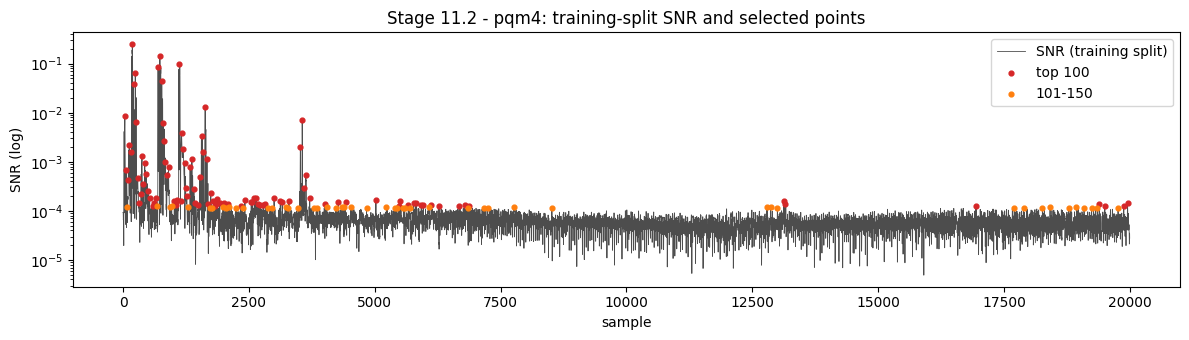

[ref] computing training-split SNR ...
  [ref] chunk 1/10 done  (3s)
  [ref] chunk 2/10 done  (6s)
  [ref] chunk 3/10 done  (9s)
  [ref] chunk 4/10 done  (11s)
  [ref] chunk 5/10 done  (14s)
  [ref] chunk 6/10 done  (18s)
  [ref] chunk 7/10 done  (23s)
  [ref] chunk 8/10 done  (26s)
  [ref] chunk 9/10 done  (29s)
  [ref] chunk 10/10 done  (33s)
[ref] saved -> /content/drive/MyDrive/mlkem_dataset/stage11/snr_train_ref.npz

=== ref ===
max weighted SNR = 0.0622 at sample 7917
top-10 points : [7917, 5683, 7957, 5722, 7996, 6039, 8684, 5779, 8280, 6449]
their SNR     : [0.0622, 0.0451, 0.0177, 0.0136, 0.0083, 0.0068, 0.0062, 0.0049, 0.0039, 0.0036]
SNR of 100th point = 0.00034, 150th point = 0.00030
overlap of top-150 (weighted vs unweighted SNR): 24/150
points span samples 97 .. 12912


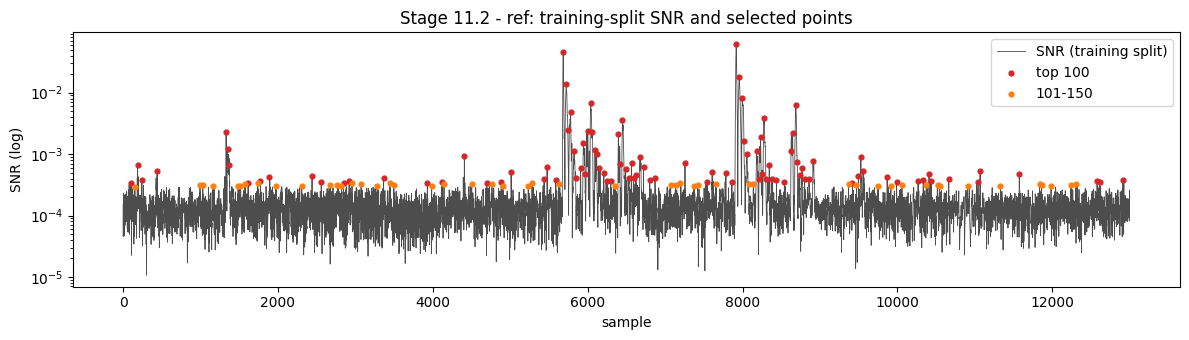

In [4]:
# ===========================================================
# STAGE 11.2 — SNR on the TRAINING split only + point selection
# (top 150 by SNR, min gap 21 so ±10 windows never overlap)
# ===========================================================
import os, time
import numpy as np
import matplotlib.pyplot as plt

dataset_dir = "/content/drive/MyDrive/mlkem_dataset"
base        = f"{dataset_dir}/extracted/d0nj0n_mlkem_dataset/pqm4-ref"
out_dir     = f"{dataset_dir}/stage11"

IMPLS    = ["pqm4", "ref"]
N_CHUNKS = {"pqm4": 20, "ref": 10}
CHUNK    = 10000
K_MAX    = 150          # top-100 = first 100 of these
HALF_W   = 10           # window = point ± 10 samples (21 total)
MIN_GAP  = 2 * HALF_W + 1
BLOCK    = 2000         # rows per matrix block (limits RAM)

def train_class_stats(impl):
    d  = np.load(f"{out_dir}/split_indices_{impl}.npz")
    tr = d["train"]; y = d["y"].astype(np.int64)
    leak = f"{base}/{impl}/variable_key/leakages"
    S = S2 = None
    cnt = np.zeros(12)
    t0 = time.time()
    for i in range(N_CHUNKS[impl]):
        rows = tr[(tr >= i * CHUNK) & (tr < (i + 1) * CHUNK)] - i * CHUNK   # train rows in this chunk
        X = np.load(f"{leak}/traces_{i}.npy")                              # full chunk into RAM (int16)
        if S is None:
            L = X.shape[1]
            S, S2 = np.zeros((12, L)), np.zeros((12, L))
        yc = y[rows + i * CHUNK]
        for b in range(0, len(rows), BLOCK):
            r, yb = rows[b:b + BLOCK], yc[b:b + BLOCK]
            xb = X[r].astype(np.float64)
            oh = np.zeros((len(r), 12)); oh[np.arange(len(r)), yb] = 1.0    # one-hot labels
            S  += oh.T @ xb                 # per-class sums
            S2 += oh.T @ (xb * xb)          # per-class sums of squares
        cnt += np.bincount(yc, minlength=12)
        del X
        print(f"  [{impl}] chunk {i + 1}/{N_CHUNKS[impl]} done  ({time.time() - t0:.0f}s)")
    return S, S2, cnt

def select_points(snr):
    L = len(snr)
    picked = []
    for p in np.argsort(snr)[::-1]:                     # highest SNR first
        if p < HALF_W or p > L - 1 - HALF_W:
            continue                                     # window must fit inside the trace
        if all(abs(p - q) >= MIN_GAP for q in picked):
            picked.append(int(p))
            if len(picked) == K_MAX:
                break
    return np.array(picked)

for impl in IMPLS:
    snr_path = f"{out_dir}/snr_train_{impl}.npz"
    if os.path.exists(snr_path):
        print(f"[{impl}] already done -> {snr_path} (skipping)")
        d = np.load(snr_path); snr_w, snr_u, pts = d["snr_w"], d["snr_u"], d["points"]
    else:
        print(f"[{impl}] computing training-split SNR ...")
        S, S2, cnt = train_class_stats(impl)
        means = S / cnt[:, None]
        var   = S2 / cnt[:, None] - means ** 2
        w     = cnt / cnt.sum()
        mu    = (w[:, None] * means).sum(0)
        snr_w = (w[:, None] * (means - mu) ** 2).sum(0) / ((w[:, None] * var).sum(0) + 1e-12)  # weighted
        snr_u = means.var(0) / (var.mean(0) + 1e-12)                                          # old, unweighted
        pts   = select_points(snr_w)
        np.savez(snr_path, snr_w=snr_w, snr_u=snr_u, points=pts,
                 class_means=means.astype(np.float32), class_vars=var.astype(np.float32),
                 class_counts=cnt, half_w=HALF_W, min_gap=MIN_GAP)
        print(f"[{impl}] saved -> {snr_path}")

    # summary
    pts_u = select_points(snr_u)
    print(f"\n=== {impl} ===")
    print(f"max weighted SNR = {snr_w.max():.4f} at sample {int(np.argmax(snr_w))}")
    print("top-10 points :", pts[:10].tolist())
    print("their SNR     :", np.round(snr_w[pts[:10]], 4).tolist())
    print(f"SNR of 100th point = {snr_w[pts[99]]:.5f}, 150th point = {snr_w[pts[149]]:.5f}")
    print(f"overlap of top-150 (weighted vs unweighted SNR): {len(np.intersect1d(pts, pts_u))}/150")
    print(f"points span samples {pts.min()} .. {pts.max()}")

    # plot for the report
        # plot for the report  (STAGE 11.2)
    plt.figure(figsize=(12, 3.5))
    plt.plot(snr_w, lw=0.6, color="0.3", label="SNR (training split)")
    plt.scatter(pts[:100], snr_w[pts[:100]], s=12, color="tab:red", label="top 100", zorder=3)
    plt.scatter(pts[100:], snr_w[pts[100:]], s=12, color="tab:orange", label="101-150", zorder=3)
    plt.yscale("log")
    plt.xlabel("sample")
    plt.ylabel("SNR (log)")
    plt.title("Stage 11.2 - " + impl + ": training-split SNR and selected points")
    plt.legend(loc="upper right")
    plt.tight_layout()
    plt.savefig(out_dir + "/fig_snr_points_" + impl + ".png", dpi=150)
    plt.show()

In [5]:
# ===========================================================
# STAGE 11.3 - Feature extraction: 150 windows x 21 samples
# for the FULL profiling set and the FULL attack set (pqm4 + ref),
# plus old Stage 8 POIs on the attack set (for Stage 11.9)
# ===========================================================
import os, time
import numpy as np

dataset_dir = "/content/drive/MyDrive/mlkem_dataset"
base        = dataset_dir + "/extracted/d0nj0n_mlkem_dataset/pqm4-ref"
out_dir     = dataset_dir + "/stage11"

IMPLS    = ["pqm4", "ref"]
N_CHUNKS = {"pqm4": 20, "ref": 10}
SCEN     = {"variable_key": "prof", "fixed_key": "attack"}

old_pois = dict(np.load(dataset_dir + "/baseline_pois.npz"))

for impl in IMPLS:
    s = np.load(out_dir + "/snr_train_" + impl + ".npz")
    pts, half_w = s["points"], int(s["half_w"])
    win  = np.arange(-half_w, half_w + 1)                 # -10 .. +10
    cols = (pts[:, None] + win[None, :]).ravel()          # 150*21 = 3150 sample indices
    K, W = len(pts), len(win)
    old_tvla = old_pois[impl + "_poi_tvla"]
    old_evt  = old_pois[impl + "_poi_evt"]
    print(f"\n[{impl}] {K} windows x {W} samples = {len(cols)} columns; "
          f"old POIs: {len(old_tvla)} baseline, {len(old_evt)} EVT")

    for scen, tag in SCEN.items():
        f_path = out_dir + f"/features_{impl}_{tag}_K{K}.npy"
        o_path = out_dir + f"/old_pois_{impl}_attack.npz"
        need_old = (tag == "attack") and not os.path.exists(o_path)
        if os.path.exists(f_path) and not need_old:
            print(f"  [{impl}/{tag}] already done (skipping)")
            continue

        leak = f"{base}/{impl}/{scen}/leakages"
        parts, old_t, old_e = [], [], []
        t0 = time.time()
        for i in range(N_CHUNKS[impl]):
            X = np.load(f"{leak}/traces_{i}.npy")                     # one chunk, int16
            sub = X[:, cols]
            assert sub.min() >= -128 and sub.max() <= 127, "values outside int8 range"
            parts.append(sub.astype(np.int8).reshape(-1, K, W))       # (rows, 150, 21)
            if tag == "attack":
                old_t.append(X[:, old_tvla].astype(np.int8))
                old_e.append(X[:, old_evt].astype(np.int8))
            # spot-check: centre of window 0 equals the raw sample at point 0
            assert np.array_equal(parts[-1][:, 0, half_w], X[:, pts[0]].astype(np.int8))
            del X, sub
            print(f"  [{impl}/{tag}] chunk {i + 1}/{N_CHUNKS[impl]}  ({time.time() - t0:.0f}s)")

        F = np.concatenate(parts)
        np.save(f_path, F)
        print(f"  saved {f_path}  shape={F.shape} dtype={F.dtype} size={F.nbytes / 1e9:.2f} GB")
        if tag == "attack":
            np.savez(o_path, X_tvla=np.concatenate(old_t), X_evt=np.concatenate(old_e),
                     poi_tvla=old_tvla, poi_evt=old_evt)
            print(f"  saved {o_path}")
        del parts, F

print("\nSTAGE 11.3 done.")


[pqm4] 150 windows x 21 samples = 3150 columns; old POIs: 50 baseline, 27 EVT
  [pqm4/prof] chunk 1/20  (1s)
  [pqm4/prof] chunk 2/20  (2s)
  [pqm4/prof] chunk 3/20  (2s)
  [pqm4/prof] chunk 4/20  (3s)
  [pqm4/prof] chunk 5/20  (4s)
  [pqm4/prof] chunk 6/20  (4s)
  [pqm4/prof] chunk 7/20  (5s)
  [pqm4/prof] chunk 8/20  (5s)
  [pqm4/prof] chunk 9/20  (6s)
  [pqm4/prof] chunk 10/20  (6s)
  [pqm4/prof] chunk 11/20  (7s)
  [pqm4/prof] chunk 12/20  (7s)
  [pqm4/prof] chunk 13/20  (8s)
  [pqm4/prof] chunk 14/20  (8s)
  [pqm4/prof] chunk 15/20  (9s)
  [pqm4/prof] chunk 16/20  (9s)
  [pqm4/prof] chunk 17/20  (10s)
  [pqm4/prof] chunk 18/20  (10s)
  [pqm4/prof] chunk 19/20  (11s)
  [pqm4/prof] chunk 20/20  (11s)
  saved /content/drive/MyDrive/mlkem_dataset/stage11/features_pqm4_prof_K150.npy  shape=(200000, 150, 21) dtype=int8 size=0.63 GB
  [pqm4/attack] chunk 1/20  (3s)
  [pqm4/attack] chunk 2/20  (8s)
  [pqm4/attack] chunk 3/20  (10s)
  [pqm4/attack] chunk 4/20  (14s)
  [pqm4/attack] chunk 

In [6]:
# ===========================================================
# STAGE 11.4 - Standardisation stats from the TRAINING split only
# + early drift check: profiling (val) vs attack recordings
# ===========================================================
import os
import numpy as np

dataset_dir = "/content/drive/MyDrive/mlkem_dataset"
out_dir     = dataset_dir + "/stage11"
IMPLS = ["pqm4", "ref"]
BLK   = 20000

for impl in IMPLS:
    sp = np.load(out_dir + "/split_indices_" + impl + ".npz")
    F  = np.load(out_dir + "/features_" + impl + "_prof_K150.npy", mmap_mode="r")
    A  = np.load(out_dir + "/features_" + impl + "_attack_K150.npy", mmap_mode="r")
    n_path = out_dir + "/norm_" + impl + ".npz"

    if not os.path.exists(n_path):
        tr = sp["train"]
        s = np.zeros(F.shape[1:]); s2 = np.zeros(F.shape[1:])
        for b in range(0, len(tr), BLK):
            x = F[tr[b:b + BLK]].astype(np.float64)
            s += x.sum(0); s2 += (x * x).sum(0)
        mu = s / len(tr)
        sd = np.sqrt(s2 / len(tr) - mu ** 2)
        assert sd.min() > 0, "a feature has zero variance"
        np.savez(n_path, mean=mu.astype(np.float32), std=sd.astype(np.float32))
        print("[" + impl + "] saved " + n_path)
    d = np.load(n_path); mu, sd = d["mean"], d["std"]

    # check: validation split after standardising should be ~ mean 0, std 1
    xv = (F[sp["val"]].astype(np.float32) - mu) / sd
    # drift check: per-feature mean shift of each set, in training-std units
    z_val = xv.mean(0)
    a_sum = np.zeros(A.shape[1:])
    for b in range(0, A.shape[0], BLK):
        a_sum += A[b:b + BLK].astype(np.float64).sum(0)
    z_att = (a_sum / A.shape[0] - mu) / sd

    print("\n=== " + impl + " ===")
    print(f"train mean range {mu.min():.2f} .. {mu.max():.2f} | train std range {sd.min():.2f} .. {sd.max():.2f}")
    print(f"val after standardising: mean {xv.mean():.4f}, std {xv.std():.4f}")
    print(f"mean shift |z|  val    : median {np.median(np.abs(z_val)):.4f}, 95th pct {np.percentile(np.abs(z_val), 95):.4f}")
    print(f"mean shift |z|  attack : median {np.median(np.abs(z_att)):.4f}, 95th pct {np.percentile(np.abs(z_att), 95):.4f}")
    del xv

[pqm4] saved /content/drive/MyDrive/mlkem_dataset/stage11/norm_pqm4.npz

=== pqm4 ===
train mean range -68.76 .. 66.50 | train std range 1.41 .. 48.89
val after standardising: mean -0.0007, std 1.0012
mean shift |z|  val    : median 0.0058, 95th pct 0.0145
mean shift |z|  attack : median 0.1202, 95th pct 0.3171
[ref] saved /content/drive/MyDrive/mlkem_dataset/stage11/norm_ref.npz

=== ref ===
train mean range -86.76 .. 87.52 | train std range 1.96 .. 58.06
val after standardising: mean 0.0001, std 0.9988
mean shift |z|  val    : median 0.0078, 95th pct 0.0201
mean shift |z|  attack : median 0.0288, 95th pct 0.1431


In [7]:
# ===========================================================
# STAGE 11.4b - Shift diagnosis: offset vs gain, leaky vs noise windows
# ===========================================================
import numpy as np

dataset_dir = "/content/drive/MyDrive/mlkem_dataset"
out_dir     = dataset_dir + "/stage11"
BLK = 20000

for impl in ["pqm4", "ref"]:
    nz = np.load(out_dir + "/norm_" + impl + ".npz"); mu, sd = nz["mean"], nz["std"]
    A  = np.load(out_dir + "/features_" + impl + "_attack_K150.npy", mmap_mode="r")
    s = np.zeros(A.shape[1:]); s2 = np.zeros(A.shape[1:])
    for b in range(0, A.shape[0], BLK):
        x = A[b:b + BLK].astype(np.float64); s += x.sum(0); s2 += (x * x).sum(0)
    ma = s / A.shape[0]; sa = np.sqrt(s2 / A.shape[0] - ma ** 2)

    raw   = ma - mu                  # mean shift in ADC units
    z     = raw / sd                 # mean shift in training-std units
    ratio = sa / sd                  # spread ratio attack / train

    zw = np.median(np.abs(z), axis=1)          # median |z| per window (windows are in SNR order)
    print("\n=== " + impl + " ===")
    print(f"mean shift (ADC units): median {np.median(raw):+.3f}, "
          f"share of features shifted upward {np.mean(raw > 0):.2f}")
    print(f"correlation of shift with feature level (gain sign): {np.corrcoef(raw.ravel(), mu.ravel())[0, 1]:+.3f}")
    print(f"spread ratio attack/train: median {np.median(ratio):.4f}  (1.0 = same noise level)")
    print(f"median |z| windows 1-30 (strongest leakage): {np.median(zw[:30]):.4f}")
    print(f"median |z| windows 101-150 (mostly noise)  : {np.median(zw[100:]):.4f}")


=== pqm4 ===
mean shift (ADC units): median -0.138, share of features shifted upward 0.45
correlation of shift with feature level (gain sign): -0.067
spread ratio attack/train: median 0.9835  (1.0 = same noise level)
median |z| windows 1-30 (strongest leakage): 0.1443
median |z| windows 101-150 (mostly noise)  : 0.1499

=== ref ===
mean shift (ADC units): median +0.087, share of features shifted upward 0.62
correlation of shift with feature level (gain sign): -0.016
spread ratio attack/train: median 1.0019  (1.0 = same noise level)
median |z| windows 1-30 (strongest leakage): 0.0447
median |z| windows 101-150 (mostly noise)  : 0.0224


In [8]:
# ===========================================================
# STAGE 11.4c - Time-misalignment test: does the attack-vs-train mean
# shift follow the slope of the training waveform?
# ===========================================================
import numpy as np

dataset_dir = "/content/drive/MyDrive/mlkem_dataset"
out_dir     = dataset_dir + "/stage11"
BLK = 20000

for impl in ["pqm4", "ref"]:
    mu = np.load(out_dir + "/norm_" + impl + ".npz")["mean"].astype(np.float64)
    A  = np.load(out_dir + "/features_" + impl + "_attack_K150.npy", mmap_mode="r")
    s = np.zeros(A.shape[1:])
    for b in range(0, A.shape[0], BLK):
        s += A[b:b + BLK].astype(np.float64).sum(0)
    raw   = s / A.shape[0] - mu                  # mean shift, ADC units, shape (150, 21)
    slope = np.gradient(mu, axis=1)              # slope of training mean waveform inside each window

    r, g = raw[:, 1:-1].ravel(), slope[:, 1:-1].ravel()        # drop window edges
    delta = -np.sum(r * g) / np.sum(g * g)                       # best-fit time shift (samples)
    corr  = np.corrcoef(r, -g)[0, 1]
    resid = r + delta * g
    explained = 1 - np.var(resid) / np.var(r)

    # same fit using only the noise windows 101-150 (no key effect there)
    rn, gn = raw[100:, 1:-1].ravel(), slope[100:, 1:-1].ravel()
    delta_n = -np.sum(rn * gn) / np.sum(gn * gn)

    print("\n=== " + impl + " ===")
    print(f"best-fit time shift (all windows)   : {delta:+.3f} samples")
    print(f"best-fit time shift (noise windows) : {delta_n:+.3f} samples")
    print(f"correlation of shift with -slope    : {corr:+.3f}")
    print(f"share of the shift explained by a time shift: {100 * explained:.1f}%")


=== pqm4 ===
best-fit time shift (all windows)   : -0.226 samples
best-fit time shift (noise windows) : -0.530 samples
correlation of shift with -slope    : -0.479
share of the shift explained by a time shift: 22.9%

=== ref ===
best-fit time shift (all windows)   : -0.071 samples
best-fit time shift (noise windows) : +0.019 samples
correlation of shift with -slope    : -0.234
share of the shift explained by a time shift: 5.5%


In [9]:
# ===========================================================
# STAGE 11.5 - Train MLP and larger windowed CNN (pqm4 + ref, K = 100 / 150)
# QUICK = True -> 1 seed (baseline) | False -> 3 seeds (final)
# ===========================================================
import os, json, time, gc
import numpy as np, pandas as pd, tensorflow as tf
from tensorflow.keras import layers, models, regularizers, callbacks

QUICK     = True
TAG       = "base"       # run label; use e.g. "aug2" for a variant
AUG_SHIFT = 0            # 0 = off. 2 = random +-2-sample time shifts (CNN, training only)
SEEDS     = [0] if QUICK else [0, 1, 2]
K_LIST    = [100, 150]
ARCHS     = ["mlp", "cnn"]
IMPLS     = ["pqm4", "ref"]
EPOCHS, BATCH, L2 = 100, 512, 1e-4

dataset_dir = "/content/drive/MyDrive/mlkem_dataset"
out_dir     = dataset_dir + "/stage11"
models_dir  = out_dir + "/models"
log_path    = out_dir + "/train_log.csv"
os.makedirs(models_dir, exist_ok=True)
print("GPU:", tf.config.list_physical_devices("GPU"))

def build_mlp(K, W=21, n_classes=12):
    reg = regularizers.l2(L2)
    inp = layers.Input(shape=(K, W))
    x = layers.Flatten()(inp)
    for units in (256, 128):
        x = layers.Dense(units, kernel_regularizer=reg)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.Dropout(0.3)(x)
    x = layers.Dense(64, activation="relu", kernel_regularizer=reg)(x)
    out = layers.Dense(n_classes, kernel_regularizer=reg)(x)            # logits
    return models.Model(inp, out, name="mlp_K" + str(K))

def build_cnn(K, W=21, n_classes=12):
    reg = regularizers.l2(L2)
    def conv_bn(x, filters, k):
        x = layers.Conv2D(filters, (1, k), padding="same", kernel_regularizer=reg)(x)
        x = layers.BatchNormalization()(x)
        return layers.Activation("relu")(x)
    inp = layers.Input(shape=(K, W))
    x = layers.Reshape((K, W, 1))(inp)
    if AUG_SHIFT > 0:
        x = layers.RandomTranslation(height_factor=0.0, width_factor=AUG_SHIFT / W,
                                     fill_mode="nearest")(x)
    x = conv_bn(x, 32, 5); x = conv_bn(x, 32, 5)
    x = layers.AveragePooling2D((1, 2))(x)          # 21 -> 10
    x = conv_bn(x, 64, 3); x = conv_bn(x, 64, 3)
    x = layers.AveragePooling2D((1, 2))(x)          # 10 -> 5
    x = conv_bn(x, 128, 3)
    x = layers.AveragePooling2D((1, 5))(x)          # 5 -> 1 per window
    x = conv_bn(x, 32, 1)                           # 1x1: 128 -> 32 per window
    x = layers.Reshape((K, 32))(x)
    x = layers.Flatten()(x)
    x = layers.Dense(256, kernel_regularizer=reg)(x)
    x = layers.BatchNormalization()(x); x = layers.Activation("relu")(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(128, kernel_regularizer=reg)(x)
    x = layers.BatchNormalization()(x); x = layers.Activation("relu")(x)
    x = layers.Dropout(0.4)(x)
    out = layers.Dense(n_classes, kernel_regularizer=reg)(x)            # logits
    return models.Model(inp, out, name="cnn_K" + str(K))

def load_xy(impl, K):
    sp = np.load(out_dir + "/split_indices_" + impl + ".npz")
    nz = np.load(out_dir + "/norm_" + impl + ".npz")
    mu, sd = nz["mean"][:K], nz["std"][:K]
    F = np.load(out_dir + "/features_" + impl + "_prof_K150.npy", mmap_mode="r")
    y = sp["y"].astype(np.int64)
    data = {}
    for part in ("train", "val"):
        idx = sp[part]
        data[part] = (((F[idx][:, :K].astype(np.float32) - mu) / sd), y[idx])
    return data

class EveryN(callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        if epoch == 0 or (epoch + 1) % 5 == 0:
            print(f"    ep {epoch + 1:3d}  loss {logs['loss']:.4f}  acc {logs['accuracy']:.4f}"
                  f"  val_loss {logs['val_loss']:.4f}  val_acc {logs['val_accuracy']:.4f}")

for impl in IMPLS:
    for K in K_LIST:
        data = load_xy(impl, K)
        (Xtr, ytr), (Xva, yva) = data["train"], data["val"]
        maj_acc = float(np.mean(yva == np.bincount(ytr, minlength=12).argmax()))
        print(f"\n##### {impl}  K={K}  train {Xtr.shape}  val {Xva.shape}  majority val acc {maj_acc:.4f}")
        for arch in ARCHS:
            for seed in SEEDS:
                name  = f"{impl}_{arch}_K{K}_s{seed}_{TAG}"
                mpath = models_dir + "/" + name + ".keras"
                if os.path.exists(mpath):
                    print("  " + name + " exists (skipping)")
                    continue
                tf.keras.backend.clear_session()
                tf.keras.utils.set_random_seed(seed)
                model = build_mlp(K) if arch == "mlp" else build_cnn(K)
                model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                              metrics=["accuracy"])
                cbs = [callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
                       callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5),
                       EveryN()]
                print(f"  --- {name}  ({model.count_params():,} params)")
                t0 = time.time()
                h = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=EPOCHS,
                              batch_size=BATCH, shuffle=True, callbacks=cbs, verbose=0)
                mins = (time.time() - t0) / 60
                model.save(mpath)
                hist = {k: [float(v) for v in vals] for k, vals in h.history.items()}
                with open(models_dir + "/" + name + "_history.json", "w") as f:
                    json.dump(hist, f)
                b = int(np.argmin(hist["val_loss"]))
                row = dict(tag=TAG, impl=impl, arch=arch, K=K, seed=seed, params=model.count_params(),
                           epochs_run=len(hist["val_loss"]), best_epoch=b + 1,
                           val_loss=round(hist["val_loss"][b], 4), val_acc=round(hist["val_accuracy"][b], 4),
                           train_acc=round(hist["accuracy"][b], 4), majority_val_acc=round(maj_acc, 4),
                           minutes=round(mins, 1))
                pd.DataFrame([row]).to_csv(log_path, mode="a", header=not os.path.exists(log_path), index=False)
                print(f"  >>> {name}: best epoch {b + 1}, val_acc {row['val_acc']}, "
                      f"val_loss {row['val_loss']}, {mins:.1f} min")
        del data, Xtr, Xva; gc.collect()

print("\n=== STAGE 11.5 summary ===")
print(pd.read_csv(log_path).to_string(index=False))

GPU: []

##### pqm4  K=100  train (160000, 100, 21)  val (20000, 100, 21)  majority val acc 0.2361
  --- pqm4_mlp_K100_s0_base  (581,324 params)
    ep   1  loss 1.8126  acc 0.2862  val_loss 1.6548  val_acc 0.3296
    ep   5  loss 1.5585  acc 0.3535  val_loss 1.5339  val_acc 0.3631
    ep  10  loss 1.5167  acc 0.3666  val_loss 1.5051  val_acc 0.3726
    ep  15  loss 1.4979  acc 0.3753  val_loss 1.4919  val_acc 0.3762
    ep  20  loss 1.4877  acc 0.3770  val_loss 1.4865  val_acc 0.3778
    ep  25  loss 1.4818  acc 0.3780  val_loss 1.4877  val_acc 0.3792
    ep  30  loss 1.4325  acc 0.3981  val_loss 1.4586  val_acc 0.3878
    ep  35  loss 1.3983  acc 0.4103  val_loss 1.4501  val_acc 0.3890
    ep  40  loss 1.3627  acc 0.4230  val_loss 1.4515  val_acc 0.3938
    ep  45  loss 1.3344  acc 0.4346  val_loss 1.4515  val_acc 0.3931
  >>> pqm4_mlp_K100_s0_base: best epoch 35, val_acc 0.389, val_loss 1.4501, 3.7 min
  --- pqm4_cnn_K100_s0_base  (909,580 params)
    ep   1  loss 1.9125  acc 0.2755

KeyboardInterrupt: 

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# ===========================================================
# STAGE 11.5 - Train MLP and larger windowed CNN (pqm4 + ref, K = 50 / 100 / 150)
# QUICK = True -> 1 seed (baseline) | False -> 3 seeds (final)
# Already-trained models are skipped automatically.
# ===========================================================
import os, json, time, gc
import numpy as np, pandas as pd, tensorflow as tf
from tensorflow.keras import layers, models, regularizers, callbacks

QUICK     = True
TAG       = "base"       # run label; use e.g. "aug2" for a variant
AUG_SHIFT = 0            # 0 = off. 2 = random +-2-sample time shifts (CNN, training only)
SEEDS     = [0] if QUICK else [0, 1, 2]
K_LIST    = [50, 100, 150]
ARCHS     = ["mlp", "cnn"]
IMPLS     = ["pqm4", "ref"]
EPOCHS, BATCH, L2 = 100, 512, 1e-4

dataset_dir = "/content/drive/MyDrive/mlkem_dataset"
out_dir     = dataset_dir + "/stage11"
models_dir  = out_dir + "/models"
log_path    = out_dir + "/train_log.csv"
os.makedirs(models_dir, exist_ok=True)
print("GPU:", tf.config.list_physical_devices("GPU"))

def build_mlp(K, W=21, n_classes=12):
    reg = regularizers.l2(L2)
    inp = layers.Input(shape=(K, W))
    x = layers.Flatten()(inp)
    for units in (256, 128):
        x = layers.Dense(units, kernel_regularizer=reg)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.Dropout(0.3)(x)
    x = layers.Dense(64, activation="relu", kernel_regularizer=reg)(x)
    out = layers.Dense(n_classes, kernel_regularizer=reg)(x)            # logits
    return models.Model(inp, out, name="mlp_K" + str(K))

def build_cnn(K, W=21, n_classes=12):
    reg = regularizers.l2(L2)
    def conv_bn(x, filters, k):
        x = layers.Conv2D(filters, (1, k), padding="same", kernel_regularizer=reg)(x)
        x = layers.BatchNormalization()(x)
        return layers.Activation("relu")(x)
    inp = layers.Input(shape=(K, W))
    x = layers.Reshape((K, W, 1))(inp)
    if AUG_SHIFT > 0:
        x = layers.RandomTranslation(height_factor=0.0, width_factor=AUG_SHIFT / W,
                                     fill_mode="nearest")(x)
    x = conv_bn(x, 32, 5); x = conv_bn(x, 32, 5)
    x = layers.AveragePooling2D((1, 2))(x)          # 21 -> 10
    x = conv_bn(x, 64, 3); x = conv_bn(x, 64, 3)
    x = layers.AveragePooling2D((1, 2))(x)          # 10 -> 5
    x = conv_bn(x, 128, 3)
    x = layers.AveragePooling2D((1, 5))(x)          # 5 -> 1 per window
    x = conv_bn(x, 32, 1)                           # 1x1: 128 -> 32 per window
    x = layers.Reshape((K, 32))(x)
    x = layers.Flatten()(x)
    x = layers.Dense(256, kernel_regularizer=reg)(x)
    x = layers.BatchNormalization()(x); x = layers.Activation("relu")(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(128, kernel_regularizer=reg)(x)
    x = layers.BatchNormalization()(x); x = layers.Activation("relu")(x)
    x = layers.Dropout(0.4)(x)
    out = layers.Dense(n_classes, kernel_regularizer=reg)(x)            # logits
    return models.Model(inp, out, name="cnn_K" + str(K))

def load_xy(impl, K):
    sp = np.load(out_dir + "/split_indices_" + impl + ".npz")
    nz = np.load(out_dir + "/norm_" + impl + ".npz")
    mu, sd = nz["mean"][:K], nz["std"][:K]
    F = np.load(out_dir + "/features_" + impl + "_prof_K150.npy", mmap_mode="r")
    y = sp["y"].astype(np.int64)
    data = {}
    for part in ("train", "val"):
        idx = sp[part]
        data[part] = (((F[idx][:, :K].astype(np.float32) - mu) / sd), y[idx])
    return data

class EveryN(callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        if epoch == 0 or (epoch + 1) % 5 == 0:
            print(f"    ep {epoch + 1:3d}  loss {logs['loss']:.4f}  acc {logs['accuracy']:.4f}"
                  f"  val_loss {logs['val_loss']:.4f}  val_acc {logs['val_accuracy']:.4f}")

for impl in IMPLS:
    for K in K_LIST:
        names = [f"{impl}_{a}_K{K}_s{s}_{TAG}" for a in ARCHS for s in SEEDS]
        if all(os.path.exists(models_dir + "/" + n + ".keras") for n in names):
            print(f"[{impl} K={K}] all models exist (skipping)")
            continue
        data = load_xy(impl, K)
        (Xtr, ytr), (Xva, yva) = data["train"], data["val"]
        maj_acc = float(np.mean(yva == np.bincount(ytr, minlength=12).argmax()))
        print(f"\n##### {impl}  K={K}  train {Xtr.shape}  val {Xva.shape}  majority val acc {maj_acc:.4f}")
        for arch in ARCHS:
            for seed in SEEDS:
                name  = f"{impl}_{arch}_K{K}_s{seed}_{TAG}"
                mpath = models_dir + "/" + name + ".keras"
                if os.path.exists(mpath):
                    print("  " + name + " exists (skipping)")
                    continue
                tf.keras.backend.clear_session()
                tf.keras.utils.set_random_seed(seed)
                model = build_mlp(K) if arch == "mlp" else build_cnn(K)
                model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                              metrics=["accuracy"])
                cbs = [callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
                       callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5),
                       EveryN()]
                print(f"  --- {name}  ({model.count_params():,} params)")
                t0 = time.time()
                h = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=EPOCHS,
                              batch_size=BATCH, shuffle=True, callbacks=cbs, verbose=0)
                mins = (time.time() - t0) / 60
                model.save(mpath)
                hist = {k: [float(v) for v in vals] for k, vals in h.history.items()}
                with open(models_dir + "/" + name + "_history.json", "w") as f:
                    json.dump(hist, f)
                b = int(np.argmin(hist["val_loss"]))
                row = dict(tag=TAG, impl=impl, arch=arch, K=K, seed=seed, params=model.count_params(),
                           epochs_run=len(hist["val_loss"]), best_epoch=b + 1,
                           val_loss=round(hist["val_loss"][b], 4), val_acc=round(hist["val_accuracy"][b], 4),
                           train_acc=round(hist["accuracy"][b], 4), majority_val_acc=round(maj_acc, 4),
                           minutes=round(mins, 1))
                pd.DataFrame([row]).to_csv(log_path, mode="a", header=not os.path.exists(log_path), index=False)
                print(f"  >>> {name}: best epoch {b + 1}, val_acc {row['val_acc']}, "
                      f"val_loss {row['val_loss']}, {mins:.1f} min")
        del data, Xtr, Xva; gc.collect()

print("\n=== STAGE 11.5 summary ===")
log = pd.read_csv(log_path)
log = log[log["tag"] == TAG].sort_values(["impl", "K", "arch", "seed"])
print(log.to_string(index=False))

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

##### pqm4  K=50  train (160000, 50, 21)  val (20000, 50, 21)  majority val acc 0.2361
  --- pqm4_mlp_K50_s0_base  (312,524 params)
    ep   1  loss 1.7894  acc 0.2901  val_loss 1.6480  val_acc 0.3297
    ep   5  loss 1.5431  acc 0.3570  val_loss 1.5119  val_acc 0.3713
    ep  10  loss 1.4987  acc 0.3708  val_loss 1.4858  val_acc 0.3761
    ep  15  loss 1.4824  acc 0.3768  val_loss 1.4732  val_acc 0.3785
    ep  20  loss 1.4714  acc 0.3801  val_loss 1.4655  val_acc 0.3832
    ep  25  loss 1.4356  acc 0.3930  val_loss 1.4499  val_acc 0.3870
    ep  30  loss 1.4215  acc 0.3970  val_loss 1.4435  val_acc 0.3880
    ep  35  loss 1.3894  acc 0.4107  val_loss 1.4329  val_acc 0.3949
    ep  40  loss 1.3652  acc 0.4171  val_loss 1.4352  val_acc 0.3959
    ep  45  loss 1.3512  acc 0.4229  val_loss 1.4359  val_acc 0.3939
    ep  50  loss 1.3367  acc 0.4273  val_loss 1.4337  val_acc 0.3941
    ep  55  loss 1.3283  acc 0.4311 

In [3]:
# ===========================================================
# STAGE 11.5e - Extra seeds (1, 2) for the key settings only
# Uses build_mlp, build_cnn, load_xy, EveryN from the 11.5 cell
# (after a runtime restart: re-run the 11.5 cell first - it skips all training)
# ===========================================================
import os, json, time, gc
import numpy as np, pandas as pd, tensorflow as tf
from tensorflow.keras import callbacks
from collections import defaultdict

TAG, AUG_SHIFT = "base", 0
EXTRA_SEEDS = [1, 2]
CONFIGS = [("pqm4", "mlp", 50), ("pqm4", "mlp", 100), ("pqm4", "mlp", 150),
           ("pqm4", "cnn", 50),
           ("ref",  "cnn", 50), ("ref",  "cnn", 100), ("ref",  "cnn", 150)]

dataset_dir = "/content/drive/MyDrive/mlkem_dataset"
out_dir     = dataset_dir + "/stage11"
models_dir  = out_dir + "/models"
log_path    = out_dir + "/train_log.csv"
EPOCHS, BATCH = 100, 512
print("GPU:", tf.config.list_physical_devices("GPU"))

groups = defaultdict(list)                      # load each dataset once
for impl, arch, K in CONFIGS:
    groups[(impl, K)].append(arch)

for (impl, K), archs in groups.items():
    todo = [(a, s) for a in archs for s in EXTRA_SEEDS
            if not os.path.exists(f"{models_dir}/{impl}_{a}_K{K}_s{s}_{TAG}.keras")]
    if not todo:
        print(f"[{impl} K={K}] extra seeds already done (skipping)")
        continue
    data = load_xy(impl, K)
    (Xtr, ytr), (Xva, yva) = data["train"], data["val"]
    maj_acc = float(np.mean(yva == np.bincount(ytr, minlength=12).argmax()))
    print(f"\n##### {impl}  K={K}  runs: {todo}")
    for arch, seed in todo:
        name  = f"{impl}_{arch}_K{K}_s{seed}_{TAG}"
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(seed)
        model = build_mlp(K) if arch == "mlp" else build_cnn(K)
        model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                      loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                      metrics=["accuracy"])
        cbs = [callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
               callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5),
               EveryN()]
        print(f"  --- {name}  ({model.count_params():,} params)")
        t0 = time.time()
        h = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=EPOCHS,
                      batch_size=BATCH, shuffle=True, callbacks=cbs, verbose=0)
        mins = (time.time() - t0) / 60
        model.save(f"{models_dir}/{name}.keras")
        hist = {k: [float(v) for v in vals] for k, vals in h.history.items()}
        with open(f"{models_dir}/{name}_history.json", "w") as f:
            json.dump(hist, f)
        b = int(np.argmin(hist["val_loss"]))
        row = dict(tag=TAG, impl=impl, arch=arch, K=K, seed=seed, params=model.count_params(),
                   epochs_run=len(hist["val_loss"]), best_epoch=b + 1,
                   val_loss=round(hist["val_loss"][b], 4), val_acc=round(hist["val_accuracy"][b], 4),
                   train_acc=round(hist["accuracy"][b], 4), majority_val_acc=round(maj_acc, 4),
                   minutes=round(mins, 1))
        pd.DataFrame([row]).to_csv(log_path, mode="a", header=False, index=False)
        print(f"  >>> {name}: best epoch {b + 1}, val_acc {row['val_acc']}, "
              f"val_loss {row['val_loss']}, {mins:.1f} min")
    del data, Xtr, Xva; gc.collect()

# ---- mean +- std over seeds for the key settings ----
log = pd.read_csv(log_path)
log = log[log["tag"] == TAG].drop_duplicates(["impl", "arch", "K", "seed"], keep="last")
keys = pd.DataFrame(CONFIGS, columns=["impl", "arch", "K"])
agg = (log.merge(keys, on=["impl", "arch", "K"])
          .groupby(["impl", "arch", "K"])
          .agg(n_seeds=("seed", "count"),
               val_acc_mean=("val_acc", "mean"), val_acc_std=("val_acc", "std"),
               val_loss_mean=("val_loss", "mean"), val_loss_std=("val_loss", "std"))
          .round(4))
print("\n=== STAGE 11.5e - mean +- std over seeds ===")
print(agg.to_string())

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

##### pqm4  K=50  runs: [('mlp', 1), ('mlp', 2), ('cnn', 1), ('cnn', 2)]
  --- pqm4_mlp_K50_s1_base  (312,524 params)
    ep   1  loss 1.7850  acc 0.2907  val_loss 1.6492  val_acc 0.3228
    ep   5  loss 1.5438  acc 0.3561  val_loss 1.5119  val_acc 0.3650
    ep  10  loss 1.4994  acc 0.3703  val_loss 1.4785  val_acc 0.3747
    ep  15  loss 1.4822  acc 0.3755  val_loss 1.4722  val_acc 0.3776
    ep  20  loss 1.4720  acc 0.3785  val_loss 1.4612  val_acc 0.3808
    ep  25  loss 1.4628  acc 0.3838  val_loss 1.4603  val_acc 0.3860
    ep  30  loss 1.4593  acc 0.3864  val_loss 1.4642  val_acc 0.3842
    ep  35  loss 1.4162  acc 0.3992  val_loss 1.4440  val_acc 0.3930
    ep  40  loss 1.3914  acc 0.4085  val_loss 1.4369  val_acc 0.3923
    ep  45  loss 1.3721  acc 0.4171  val_loss 1.4368  val_acc 0.3932
    ep  50  loss 1.3464  acc 0.4264  val_loss 1.4356  val_acc 0.3959
    ep  55  loss 1.3300  acc 0.4316  val_loss 1.43

=== STAGE 11.7 - TEST split, per setting (mean over seeds; T fitted on validation) ===
               n       T  acc_mean  acc_std  pi_mean  pi_std  nll_cal  ece_raw  ece_cal    off1  off2plus
impl arch K                                                                                              
pqm4 cnn  50   3  1.1393    0.3866   0.0024   0.7470  0.0127   1.3921   0.0270   0.0175  0.4895    0.1239
          100  1  1.0580    0.3823      NaN   0.7373     NaN   1.3989   0.0183   0.0152  0.4942    0.1235
          150  1  1.0120    0.3846      NaN   0.7225     NaN   1.4091   0.0138   0.0139  0.4845    0.1309
     mlp  50   3  1.1383    0.3949   0.0038   0.7587  0.0031   1.3840   0.0250   0.0083  0.4832    0.1219
          100  3  1.1340    0.3902   0.0030   0.7452  0.0036   1.3934   0.0273   0.0081  0.4847    0.1251
          150  3  1.1540    0.3902   0.0014   0.7398  0.0018   1.3971   0.0311   0.0088  0.4828    0.1271
ref  cnn  50   3  1.3607    0.9377   0.0022   2.5047  0.0087   0.

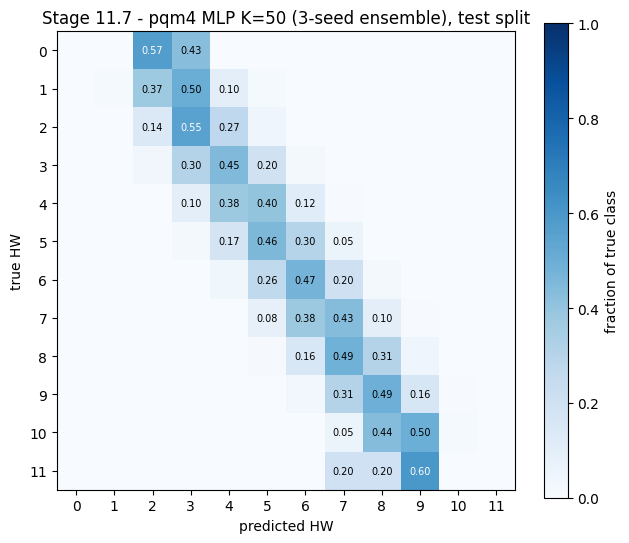

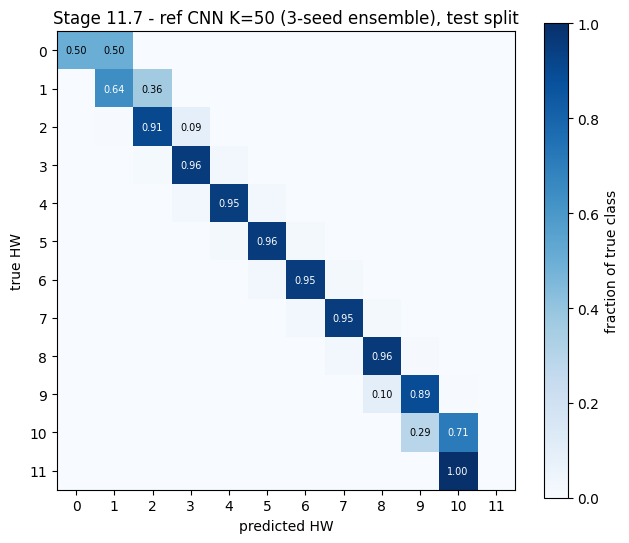


Saved to /content/drive/MyDrive/mlkem_dataset/stage11/eval


In [4]:
# ===========================================================
# STAGE 11.6 + 11.7 - Temperature calibration (validation split)
# + evaluation on the untouched TEST split, per model and 3-seed ensemble
# ===========================================================
import os, gc
import numpy as np, pandas as pd, tensorflow as tf
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar

dataset_dir = "/content/drive/MyDrive/mlkem_dataset"
out_dir     = dataset_dir + "/stage11"
models_dir  = out_dir + "/models"
eval_dir    = out_dir + "/eval"
log_path    = out_dir + "/train_log.csv"
os.makedirs(eval_dir, exist_ok=True)
TAG  = "base"
MAIN = [("pqm4", "mlp", 50), ("ref", "cnn", 50)]       # confusion matrices for these

def load_part(impl, K, part):
    sp = np.load(out_dir + "/split_indices_" + impl + ".npz")
    nz = np.load(out_dir + "/norm_" + impl + ".npz")
    mu, sd = nz["mean"][:K], nz["std"][:K]
    F = np.load(out_dir + "/features_" + impl + "_prof_K150.npy", mmap_mode="r")
    idx = sp[part]
    return ((F[idx][:, :K].astype(np.float32) - mu) / sd), sp["y"][idx].astype(np.int64), sp["prior_train"]

def log_softmax(z):
    z = z - z.max(1, keepdims=True)
    return z - np.log(np.exp(z).sum(1, keepdims=True))

def nll_T(T, logits, y):
    return -log_softmax(logits / T)[np.arange(len(y)), y].mean()

def ece(logp, y, bins=15):
    p = np.exp(logp); conf = p.max(1); correct = (p.argmax(1) == y)
    e, edges = 0.0, np.linspace(0, 1, bins + 1)
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return float(e)

def metrics(logp, y, prior):
    pred = logp.argmax(1)
    pr = prior[prior > 0]
    H = float(-(pr * np.log2(pr)).sum())                       # prior entropy (bits)
    ll = logp[np.arange(len(y)), y]
    return dict(acc=float((pred == y).mean()), nll=float(-ll.mean()),
                pi_bits=float(H + (ll / np.log(2)).mean()), ece=ece(logp, y),
                off1=float((np.abs(pred - y) == 1).mean()), off2plus=float((np.abs(pred - y) > 1).mean()))

log = pd.read_csv(log_path)
log = log[log["tag"] == TAG].drop_duplicates(["impl", "arch", "K", "seed"], keep="last")

rows, ens_rows, cm_data = [], [], {}
for (impl, K), grp in log.groupby(["impl", "K"]):
    Xv, yv, prior = load_part(impl, K, "val")
    Xt, yt, _     = load_part(impl, K, "test")
    cal_logp = {}                                              # (arch, seed) -> calibrated test log-probs
    for _, r in grp.sort_values(["arch", "seed"]).iterrows():
        arch, seed = r["arch"], int(r["seed"])
        name  = f"{impl}_{arch}_K{K}_s{seed}_{TAG}"
        lpath = f"{eval_dir}/logits_{name}.npz"
        if os.path.exists(lpath):
            d = np.load(lpath); lv, lt = d["val"], d["test"]
        else:
            m  = tf.keras.models.load_model(f"{models_dir}/{name}.keras")
            lv = m.predict(Xv, batch_size=4096, verbose=0)
            lt = m.predict(Xt, batch_size=4096, verbose=0)
            np.savez(lpath, val=lv, test=lt)
            del m; tf.keras.backend.clear_session()
        T = float(minimize_scalar(nll_T, bounds=(0.05, 10.0), method="bounded", args=(lv, yv)).x)
        raw = metrics(log_softmax(lt), yt, prior)
        cal = metrics(log_softmax(lt / T), yt, prior)
        cal_logp[(arch, seed)] = log_softmax(lt / T)
        rows.append(dict(impl=impl, arch=arch, K=K, seed=seed, T=round(T, 3),
                         test_acc=round(raw["acc"], 4),
                         nll_raw=round(raw["nll"], 4), nll_cal=round(cal["nll"], 4),
                         pi_raw=round(raw["pi_bits"], 4), pi_cal=round(cal["pi_bits"], 4),
                         ece_raw=round(raw["ece"], 4), ece_cal=round(cal["ece"], 4),
                         off1=round(cal["off1"], 4), off2plus=round(cal["off2plus"], 4)))
    # 3-seed ensemble: average calibrated probabilities
    for arch in sorted({a for a, _ in cal_logp}):
        seeds = sorted(s for a, s in cal_logp if a == arch)
        if len(seeds) < 2:
            continue
        p = np.mean([np.exp(cal_logp[(arch, s)]) for s in seeds], axis=0)
        lp = np.log(np.clip(p, 1e-12, 1.0))
        e = metrics(lp, yt, prior)
        ens_rows.append(dict(impl=impl, arch=arch, K=K, n_seeds=len(seeds),
                             test_acc=round(e["acc"], 4), nll=round(e["nll"], 4),
                             pi_bits=round(e["pi_bits"], 4), ece=round(e["ece"], 4),
                             off1=round(e["off1"], 4), off2plus=round(e["off2plus"], 4)))
        if (impl, arch, K) in MAIN:
            cm_data[(impl, arch, K)] = (lp.argmax(1), yt)
    del Xv, Xt; gc.collect()

per_model = pd.DataFrame(rows)
per_model.to_csv(eval_dir + "/eval_test_per_model.csv", index=False)
agg = (per_model.groupby(["impl", "arch", "K"])
       .agg(n=("seed", "count"), T=("T", "mean"),
            acc_mean=("test_acc", "mean"), acc_std=("test_acc", "std"),
            pi_mean=("pi_cal", "mean"), pi_std=("pi_cal", "std"),
            nll_cal=("nll_cal", "mean"), ece_raw=("ece_raw", "mean"), ece_cal=("ece_cal", "mean"),
            off1=("off1", "mean"), off2plus=("off2plus", "mean")).round(4))
ens = pd.DataFrame(ens_rows)
agg.to_csv(eval_dir + "/eval_test_agg.csv"); ens.to_csv(eval_dir + "/eval_test_ensemble.csv", index=False)

print("=== STAGE 11.7 - TEST split, per setting (mean over seeds; T fitted on validation) ===")
print(agg.to_string())
print("\n=== STAGE 11.7 - TEST split, 3-seed ensembles ===")
print(ens.to_string(index=False))

# confusion matrices (row-normalised) for the main models
for (impl, arch, K), (pred, yt) in cm_data.items():
    cm = np.zeros((12, 12))
    np.add.at(cm, (yt, pred), 1)
    cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    plt.figure(figsize=(6.5, 5.5))
    plt.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    plt.colorbar(label="fraction of true class")
    for i in range(12):
        for j in range(12):
            if cmn[i, j] >= 0.05:
                plt.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", fontsize=7,
                         color="white" if cmn[i, j] > 0.5 else "black")
    plt.xticks(range(12)); plt.yticks(range(12))
    plt.xlabel("predicted HW"); plt.ylabel("true HW")
    plt.title(f"Stage 11.7 - {impl} {arch.upper()} K={K} (3-seed ensemble), test split")
    plt.tight_layout()
    plt.savefig(f"{eval_dir}/fig_confusion_{impl}_{arch}_K{K}.png", dpi=150)
    plt.show()
print("\nSaved to", eval_dir)

In [6]:
# ===========================================================
# STAGE 11.8 - Full attack-set evaluation (pqm4 200k, ref 100k fixed-key traces)
# 3-seed calibrated ensembles; GE / success rate / prior correction / drift
# ===========================================================
import os, gc
import numpy as np, pandas as pd, tensorflow as tf
import matplotlib.pyplot as plt
tf.get_logger().setLevel("ERROR")

dataset_dir = "/content/drive/MyDrive/mlkem_dataset"
out_dir     = dataset_dir + "/stage11"
models_dir  = out_dir + "/models"
eval_dir    = out_dir + "/eval"
att_dir     = out_dir + "/attack"
os.makedirs(att_dir, exist_ok=True)
TAG, SEEDS, R, CHUNK = "base", [0, 1, 2], 100, 10000
SECRET_HW = {"pqm4": 6, "ref": 2}        # 679 -> HW 6, 1026 -> HW 2 (Stage 11.0)
CONFIGS = [("pqm4", "mlp", 50), ("pqm4", "mlp", 100), ("pqm4", "mlp", 150), ("pqm4", "cnn", 50),
           ("ref", "cnn", 50), ("ref", "cnn", 100), ("ref", "cnn", 150)]
MAIN = [("pqm4", "mlp", 50), ("ref", "cnn", 50)]
LN2 = np.log(2)
rng = np.random.default_rng(2026)
Tdf = pd.read_csv(eval_dir + "/eval_test_per_model.csv")

def log_softmax(z):
    z = z - z.max(1, keepdims=True)
    return z - np.log(np.exp(z).sum(1, keepdims=True))

def get_T(impl, arch, K, s):
    q = Tdf[(Tdf.impl == impl) & (Tdf.arch == arch) & (Tdf.K == K) & (Tdf.seed == s)]
    return float(q["T"].iloc[0])

def load_attack(impl, K):
    nz = np.load(out_dir + "/norm_" + impl + ".npz"); mu, sd = nz["mean"][:K], nz["std"][:K]
    A = np.load(out_dir + "/features_" + impl + "_attack_K150.npy", mmap_mode="r")
    X = np.empty((A.shape[0], K, 21), np.float32)
    for b in range(0, A.shape[0], 20000):
        X[b:b + 20000] = (A[b:b + 20000, :K].astype(np.float32) - mu) / sd
    return X

def ensemble(impl, arch, K, XA):
    p_att, p_test = [], []
    for s in SEEDS:
        name = f"{impl}_{arch}_K{K}_s{s}_{TAG}"
        fpath = f"{att_dir}/attlogits_{name}.npy"
        if os.path.exists(fpath):
            lg = np.load(fpath)
        else:
            m = tf.keras.models.load_model(f"{models_dir}/{name}.keras")
            lg = m.predict(XA, batch_size=8192, verbose=0).astype(np.float32)
            np.save(fpath, lg); del m; tf.keras.backend.clear_session()
        T = get_T(impl, arch, K, s)
        p_att.append(np.exp(log_softmax(lg / T)))
        p_test.append(np.exp(log_softmax(np.load(f"{eval_dir}/logits_{name}.npz")["test"] / T)))
    lp = lambda ps: np.log(np.clip(np.mean(ps, 0), 1e-12, 1.0))
    return lp(p_att), lp(p_test)

def ge_curve(logp, true, grid):
    ranks = np.zeros((R, len(grid)))
    for r in range(R):
        cs = np.cumsum(logp[rng.permutation(len(logp))].astype(np.float64), axis=0)[grid - 1]
        ranks[r] = (cs > cs[:, [true]]).sum(1)
    return ranks.mean(0), (ranks == 0).mean(0)

def n_success(grid, ge, thr=0.5):
    ok = ge < thr
    for i in range(len(grid)):
        if ok[i:].all():
            return int(grid[i])
    return None

def sr_disjoint(logp, true, n):
    k = len(logp) // n
    idx = rng.permutation(len(logp))[:k * n].reshape(k, n)
    return float((logp[idx].sum(1).argmax(1) == true).mean()), k

rows, curves = [], {}
for impl in ["pqm4", "ref"]:
    sp = np.load(out_dir + "/split_indices_" + impl + ".npz")
    prior = sp["prior_train"]; logprior = np.log(prior)
    H = float(-(prior[prior > 0] * np.log2(prior[prior > 0])).sum())
    y_test = sp["y"][sp["test"]].astype(np.int64)
    true = SECRET_HW[impl]
    for K in sorted({k for i, a, k in CONFIGS if i == impl}):
        XA = load_attack(impl, K)
        N = len(XA)
        grid = np.unique(np.round(np.logspace(0, np.log10(N), 45)).astype(int))
        for arch in [a for i, a, k in CONFIGS if i == impl and k == K]:
            la, lt = ensemble(impl, arch, K, XA)
            lc = la - logprior                                   # prior-corrected
            # same-class comparison: test traces of the secret class vs attack traces
            mt = (y_test == true)
            acc_test_cls = float((lt[mt].argmax(1) == true).mean())
            ll_test_cls  = float(lt[mt, true].mean() / LN2)
            acc_att      = float((la.argmax(1) == true).mean())
            ll_att       = float(la[:, true].mean() / LN2)
            d_plain = np.bincount(np.clip(la.argmax(1) - true, -3, 3) + 3, minlength=7) / N
            d_corr  = np.bincount(np.clip(lc.argmax(1) - true, -3, 3) + 3, minlength=7) / N
            ge_p, sr_p = ge_curve(la, true, grid)
            ge_c, sr_c = ge_curve(lc, true, grid)
            curves[(impl, arch, K)] = dict(grid=grid, ge_plain=ge_p, ge_corr=ge_c, sr_plain=sr_p, sr_corr=sr_c)
            row = dict(impl=impl, arch=arch, K=K, N_attack=N,
                       acc_test_sameclass=round(acc_test_cls, 4), acc_attack=round(acc_att, 4),
                       log2p_test_sameclass=round(ll_test_cls, 4), log2p_attack=round(ll_att, 4),
                       N_ge0_plain=n_success(grid, ge_p), N_ge0_corr=n_success(grid, ge_c),
                       final_rank_plain=round(float(ge_p[-1]), 2), final_rank_corr=round(float(ge_c[-1]), 2))
            for n in [1, 10, 100, 1000, 10000]:
                row[f"SRcorr_n{n}"] = round(sr_disjoint(lc, true, n)[0], 3)
            rows.append(row)
            print(f"\n=== {impl} {arch.upper()} K={K}  (true HW {true}, N={N}) ===")
            print("pred - true      :   -3+    -2    -1     0    +1    +2   +3+")
            print("plain     (%)    :", " ".join(f"{100 * v:5.1f}" for v in d_plain))
            print("prior-corr (%)   :", " ".join(f"{100 * v:5.1f}" for v in d_corr))
            print(f"same-class acc  test {acc_test_cls:.4f} | attack {acc_att:.4f}   "
                  f"mean log2 p(true): test {ll_test_cls:.3f} | attack {ll_att:.3f}")
            print(f"traces to GE<0.5: plain {row['N_ge0_plain']} | prior-corrected {row['N_ge0_corr']}")
            if (impl, arch, K) in MAIN:                          # drift across recording order
                print("per-chunk (10k traces): acc | mean log2 p(true) | decision plain/corr")
                for c in range(N // CHUNK):
                    s_ = slice(c * CHUNK, (c + 1) * CHUNK)
                    print(f"  chunk {c:2d}: {(la[s_].argmax(1) == true).mean():.3f} | "
                          f"{la[s_, true].mean() / LN2:7.3f} | "
                          f"{la[s_].sum(0).argmax():2d} / {lc[s_].sum(0).argmax():2d}")
            del la, lt, lc; gc.collect()
        del XA; gc.collect()

res = pd.DataFrame(rows)
res.to_csv(att_dir + "/attack_results.csv", index=False)
np.savez(att_dir + "/ge_curves.npz",
         **{f"{i}_{a}_K{k}_{key}": v for (i, a, k), d in curves.items() for key, v in d.items()})
print("\n=== STAGE 11.8 summary ===")
print(res.to_string(index=False))

# GE curves (prior-corrected solid, plain dashed)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, impl in zip(axes, ["pqm4", "ref"]):
    for (i, a, k), d in curves.items():
        if i != impl:
            continue
        line, = ax.plot(d["grid"], d["ge_corr"], label=f"{a.upper()} K={k} (prior-corr.)")
        ax.plot(d["grid"], d["ge_plain"], "--", color=line.get_color(), alpha=0.5)
    ax.set_xscale("log"); ax.set_xlabel("number of attack traces"); ax.set_ylabel("guessing entropy (rank)")
    ax.set_title(f"Stage 11.8 - {impl}: attack set, true HW {SECRET_HW[impl]}")
    ax.axhline(0.5, color="0.6", lw=0.8); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(att_dir + "/fig_ge_curves.png", dpi=150); plt.show()


=== pqm4 MLP K=50  (true HW 6, N=200000) ===
pred - true      :   -3+    -2    -1     0    +1    +2   +3+
plain     (%)    :   0.3   9.4  55.5  32.4   2.4   0.0   0.0
prior-corr (%)   :   5.9  20.4  44.0  23.7   5.3   0.5   0.1
same-class acc  test 0.4740 | attack 0.3238   mean log2 p(true): test -1.767 | attack -1.966
traces to GE<0.5: plain None | prior-corrected None
per-chunk (10k traces): acc | mean log2 p(true) | decision plain/corr
  chunk  0: 0.331 |  -1.949 |  5 /  5
  chunk  1: 0.323 |  -1.963 |  5 /  5
  chunk  2: 0.328 |  -1.963 |  5 /  5
  chunk  3: 0.330 |  -1.959 |  5 /  5
  chunk  4: 0.323 |  -1.963 |  5 /  5
  chunk  5: 0.329 |  -1.956 |  5 /  5
  chunk  6: 0.333 |  -1.954 |  5 /  5
  chunk  7: 0.324 |  -1.959 |  5 /  5
  chunk  8: 0.313 |  -1.989 |  5 /  5
  chunk  9: 0.327 |  -1.964 |  5 /  5
  chunk 10: 0.323 |  -1.965 |  5 /  5
  chunk 11: 0.330 |  -1.943 |  5 /  5
  chunk 12: 0.334 |  -1.944 |  5 /  5
  chunk 13: 0.326 |  -1.965 |  5 /  5
  chunk 14: 0.324 |  -1.

InternalError: Graph execution error:

Detected at node StatefulPartitionedCall defined at (most recent call last):
  File "<frozen runpy>", line 203, in _run_module_as_main

  File "<frozen runpy>", line 88, in _run_code

  File "/usr/local/lib/python3.13/dist-packages/colab_kernel_launcher.py", line 37, in <module>

  File "/usr/local/lib/python3.13/dist-packages/traitlets/config/application.py", line 992, in launch_instance

  File "/usr/local/lib/python3.13/dist-packages/ipykernel/kernelapp.py", line 712, in start

  File "/usr/local/lib/python3.13/dist-packages/tornado/platform/asyncio.py", line 211, in start

  File "/usr/lib/python3.13/asyncio/base_events.py", line 684, in run_forever

  File "/usr/lib/python3.13/asyncio/base_events.py", line 2061, in _run_once

  File "/usr/lib/python3.13/asyncio/events.py", line 89, in _run

  File "/usr/local/lib/python3.13/dist-packages/ipykernel/kernelbase.py", line 510, in dispatch_queue

  File "/usr/local/lib/python3.13/dist-packages/ipy


=== pqm4 MLP K=50  (true HW 6, N=200000) ===
pred - true      :   -3+    -2    -1     0    +1    +2   +3+
plain     (%)    :   0.3   9.4  55.5  32.4   2.4   0.0   0.0
prior-corr (%)   :   5.9  20.4  44.0  23.7   5.3   0.5   0.1
same-class acc  test 0.4740 | attack 0.3238   mean log2 p(true): test -1.767 | attack -1.966
traces to GE<0.5: plain None | prior-corrected None
per-chunk (10k traces): acc | mean log2 p(true) | decision plain/corr
  chunk  0: 0.331 |  -1.949 |  5 /  5
  chunk  1: 0.323 |  -1.963 |  5 /  5
  chunk  2: 0.328 |  -1.963 |  5 /  5
  chunk  3: 0.330 |  -1.959 |  5 /  5
  chunk  4: 0.323 |  -1.963 |  5 /  5
  chunk  5: 0.329 |  -1.956 |  5 /  5
  chunk  6: 0.333 |  -1.954 |  5 /  5
  chunk  7: 0.324 |  -1.959 |  5 /  5
  chunk  8: 0.313 |  -1.989 |  5 /  5
  chunk  9: 0.327 |  -1.964 |  5 /  5
  chunk 10: 0.323 |  -1.965 |  5 /  5
  chunk 11: 0.330 |  -1.943 |  5 /  5
  chunk 12: 0.334 |  -1.944 |  5 /  5
  chunk 13: 0.326 |  -1.965 |  5 /  5
  chunk 14: 0.324 |  -1.

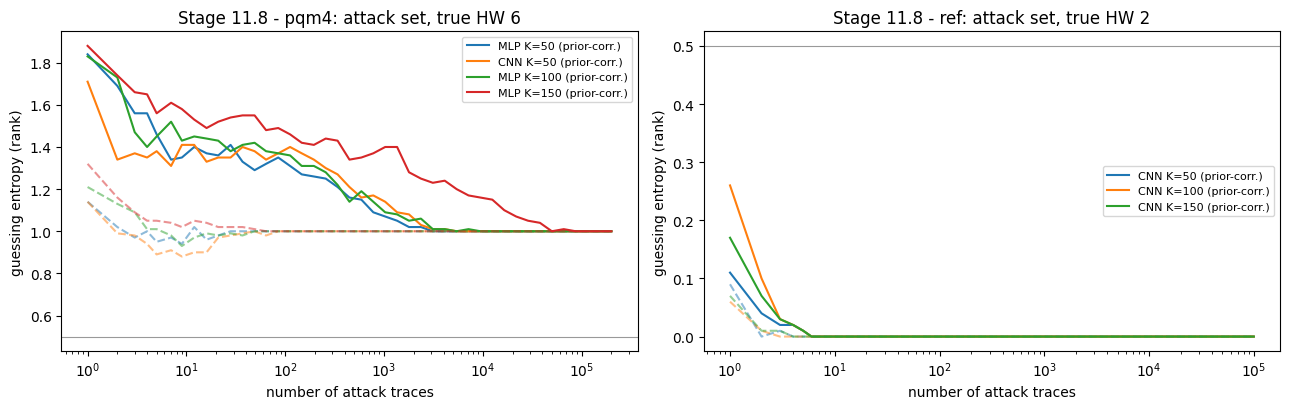

In [8]:
# ===========================================================
# STAGE 11.8 - Full attack-set evaluation (pqm4 200k, ref 100k fixed-key traces)
# 3-seed calibrated ensembles; GE / success rate / prior correction / drift
# (fixed: prediction batch 1024, with automatic fallback to 256 on GPU errors)
# ===========================================================
import os, gc
import numpy as np, pandas as pd, tensorflow as tf
import matplotlib.pyplot as plt
tf.get_logger().setLevel("ERROR")

dataset_dir = "/content/drive/MyDrive/mlkem_dataset"
out_dir     = dataset_dir + "/stage11"
models_dir  = out_dir + "/models"
eval_dir    = out_dir + "/eval"
att_dir     = out_dir + "/attack"
os.makedirs(att_dir, exist_ok=True)
TAG, SEEDS, R, CHUNK = "base", [0, 1, 2], 100, 10000
PRED_BATCH = 1024
SECRET_HW = {"pqm4": 6, "ref": 2}        # 679 -> HW 6, 1026 -> HW 2 (Stage 11.0)
CONFIGS = [("pqm4", "mlp", 50), ("pqm4", "mlp", 100), ("pqm4", "mlp", 150), ("pqm4", "cnn", 50),
           ("ref", "cnn", 50), ("ref", "cnn", 100), ("ref", "cnn", 150)]
MAIN = [("pqm4", "mlp", 50), ("ref", "cnn", 50)]
LN2 = np.log(2)
rng = np.random.default_rng(2026)
Tdf = pd.read_csv(eval_dir + "/eval_test_per_model.csv")

def log_softmax(z):
    z = z - z.max(1, keepdims=True)
    return z - np.log(np.exp(z).sum(1, keepdims=True))

def get_T(impl, arch, K, s):
    q = Tdf[(Tdf.impl == impl) & (Tdf.arch == arch) & (Tdf.K == K) & (Tdf.seed == s)]
    return float(q["T"].iloc[0])

def load_attack(impl, K):
    nz = np.load(out_dir + "/norm_" + impl + ".npz"); mu, sd = nz["mean"][:K], nz["std"][:K]
    A = np.load(out_dir + "/features_" + impl + "_attack_K150.npy", mmap_mode="r")
    X = np.empty((A.shape[0], K, 21), np.float32)
    for b in range(0, A.shape[0], 20000):
        X[b:b + 20000] = (A[b:b + 20000, :K].astype(np.float32) - mu) / sd
    return X

def safe_predict(m, X):
    try:
        return m.predict(X, batch_size=PRED_BATCH, verbose=0)
    except (tf.errors.InternalError, tf.errors.ResourceExhaustedError):
        print("    GPU error at batch", PRED_BATCH, "-> retrying with batch 256")
        return m.predict(X, batch_size=256, verbose=0)

def ensemble(impl, arch, K, XA):
    p_att, p_test = [], []
    for s in SEEDS:
        name = f"{impl}_{arch}_K{K}_s{s}_{TAG}"
        fpath = f"{att_dir}/attlogits_{name}.npy"
        if os.path.exists(fpath):
            lg = np.load(fpath)
        else:
            m = tf.keras.models.load_model(f"{models_dir}/{name}.keras")
            lg = safe_predict(m, XA).astype(np.float32)
            np.save(fpath, lg); del m; tf.keras.backend.clear_session()
        T = get_T(impl, arch, K, s)
        p_att.append(np.exp(log_softmax(lg / T)))
        p_test.append(np.exp(log_softmax(np.load(f"{eval_dir}/logits_{name}.npz")["test"] / T)))
    lp = lambda ps: np.log(np.clip(np.mean(ps, 0), 1e-12, 1.0))
    return lp(p_att), lp(p_test)

def ge_curve(logp, true, grid):
    ranks = np.zeros((R, len(grid)))
    for r in range(R):
        cs = np.cumsum(logp[rng.permutation(len(logp))].astype(np.float64), axis=0)[grid - 1]
        ranks[r] = (cs > cs[:, [true]]).sum(1)
    return ranks.mean(0), (ranks == 0).mean(0)

def n_success(grid, ge, thr=0.5):
    ok = ge < thr
    for i in range(len(grid)):
        if ok[i:].all():
            return int(grid[i])
    return None

def sr_disjoint(logp, true, n):
    k = len(logp) // n
    idx = rng.permutation(len(logp))[:k * n].reshape(k, n)
    return float((logp[idx].sum(1).argmax(1) == true).mean()), k

rows, curves = [], {}
for impl in ["pqm4", "ref"]:
    sp = np.load(out_dir + "/split_indices_" + impl + ".npz")
    prior = sp["prior_train"]; logprior = np.log(prior)
    y_test = sp["y"][sp["test"]].astype(np.int64)
    true = SECRET_HW[impl]
    for K in sorted({k for i, a, k in CONFIGS if i == impl}):
        XA = load_attack(impl, K)
        N = len(XA)
        grid = np.unique(np.round(np.logspace(0, np.log10(N), 45)).astype(int))
        for arch in [a for i, a, k in CONFIGS if i == impl and k == K]:
            la, lt = ensemble(impl, arch, K, XA)
            lc = la - logprior                                   # prior-corrected
            mt = (y_test == true)                                # test traces of the secret class
            acc_test_cls = float((lt[mt].argmax(1) == true).mean())
            ll_test_cls  = float(lt[mt, true].mean() / LN2)
            acc_att      = float((la.argmax(1) == true).mean())
            ll_att       = float(la[:, true].mean() / LN2)
            d_plain = np.bincount(np.clip(la.argmax(1) - true, -3, 3) + 3, minlength=7) / N
            d_corr  = np.bincount(np.clip(lc.argmax(1) - true, -3, 3) + 3, minlength=7) / N
            ge_p, sr_p = ge_curve(la, true, grid)
            ge_c, sr_c = ge_curve(lc, true, grid)
            curves[(impl, arch, K)] = dict(grid=grid, ge_plain=ge_p, ge_corr=ge_c, sr_plain=sr_p, sr_corr=sr_c)
            row = dict(impl=impl, arch=arch, K=K, N_attack=N,
                       acc_test_sameclass=round(acc_test_cls, 4), acc_attack=round(acc_att, 4),
                       log2p_test_sameclass=round(ll_test_cls, 4), log2p_attack=round(ll_att, 4),
                       N_ge0_plain=n_success(grid, ge_p), N_ge0_corr=n_success(grid, ge_c),
                       final_rank_plain=round(float(ge_p[-1]), 2), final_rank_corr=round(float(ge_c[-1]), 2))
            for n in [1, 10, 100, 1000, 10000]:
                row[f"SRcorr_n{n}"] = round(sr_disjoint(lc, true, n)[0], 3)
            rows.append(row)
            print(f"\n=== {impl} {arch.upper()} K={K}  (true HW {true}, N={N}) ===")
            print("pred - true      :   -3+    -2    -1     0    +1    +2   +3+")
            print("plain     (%)    :", " ".join(f"{100 * v:5.1f}" for v in d_plain))
            print("prior-corr (%)   :", " ".join(f"{100 * v:5.1f}" for v in d_corr))
            print(f"same-class acc  test {acc_test_cls:.4f} | attack {acc_att:.4f}   "
                  f"mean log2 p(true): test {ll_test_cls:.3f} | attack {ll_att:.3f}")
            print(f"traces to GE<0.5: plain {row['N_ge0_plain']} | prior-corrected {row['N_ge0_corr']}")
            if (impl, arch, K) in MAIN:                          # drift across recording order
                print("per-chunk (10k traces): acc | mean log2 p(true) | decision plain/corr")
                for c in range(N // CHUNK):
                    s_ = slice(c * CHUNK, (c + 1) * CHUNK)
                    print(f"  chunk {c:2d}: {(la[s_].argmax(1) == true).mean():.3f} | "
                          f"{la[s_, true].mean() / LN2:7.3f} | "
                          f"{la[s_].sum(0).argmax():2d} / {lc[s_].sum(0).argmax():2d}")
            del la, lt, lc; gc.collect()
        del XA; gc.collect()

res = pd.DataFrame(rows)
res.to_csv(att_dir + "/attack_results.csv", index=False)
np.savez(att_dir + "/ge_curves.npz",
         **{f"{i}_{a}_K{k}_{key}": v for (i, a, k), d in curves.items() for key, v in d.items()})
print("\n=== STAGE 11.8 summary ===")
print(res.to_string(index=False))

# GE curves (prior-corrected solid, plain dashed)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, impl in zip(axes, ["pqm4", "ref"]):
    for (i, a, k), d in curves.items():
        if i != impl:
            continue
        line, = ax.plot(d["grid"], d["ge_corr"], label=f"{a.upper()} K={k} (prior-corr.)")
        ax.plot(d["grid"], d["ge_plain"], "--", color=line.get_color(), alpha=0.5)
    ax.set_xscale("log"); ax.set_xlabel("number of attack traces"); ax.set_ylabel("guessing entropy (rank)")
    ax.set_title(f"Stage 11.8 - {impl}: attack set, true HW {SECRET_HW[impl]}")
    ax.axhline(0.5, color="0.6", lw=0.8); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(att_dir + "/fig_ge_curves.png", dpi=150); plt.show()

In [9]:
# ===========================================================
# STAGE 11.8c - pqm4 converges to HW 5: value-specific leakage (B)
# or profiling-vs-attack recording shift (A)?  ref = control
# ===========================================================
import numpy as np, pandas as pd

dataset_dir = "/content/drive/MyDrive/mlkem_dataset"
base    = dataset_dir + "/extracted/d0nj0n_mlkem_dataset/pqm4-ref"
out_dir = dataset_dir + "/stage11"
eval_dir, att_dir = out_dir + "/eval", out_dir + "/attack"
SECRET = {"pqm4": (679, "mlp", 50, 20), "ref": (1026, "cnn", 50, 10)}   # value, arch, K, n_chunks
Tdf = pd.read_csv(eval_dir + "/eval_test_per_model.csv")
CLS = np.arange(12)

def hw16(x):
    x = np.asarray(x).astype(np.int64) & 0xFFFF
    return sum(((x >> b) & 1) for b in range(16))

def load_meta(path):
    a = np.load(path)
    return a.view(np.int16) if a.dtype == np.uint8 else a

def log_softmax(z):
    z = z - z.max(1, keepdims=True)
    return z - np.log(np.exp(z).sum(1, keepdims=True))

def ens_probs(impl, arch, K, which):
    ps = []
    for s in [0, 1, 2]:
        name = f"{impl}_{arch}_K{K}_s{s}_base"
        T = float(Tdf[(Tdf.impl == impl) & (Tdf.arch == arch) & (Tdf.K == K) & (Tdf.seed == s)]["T"].iloc[0])
        lg = np.load(f"{att_dir}/attlogits_{name}.npy") if which == "attack" \
             else np.load(f"{eval_dir}/logits_{name}.npz")[which]
        ps.append(np.exp(log_softmax(lg / T)))
    return np.mean(ps, 0)

for impl, (secret, arch, K, nch) in SECRET.items():
    sp  = np.load(out_dir + "/split_indices_" + impl + ".npz")
    a0  = np.concatenate([load_meta(f"{base}/{impl}/variable_key/metadata/mult_a_{i}.npy")[:, 0]
                          for i in range(nch)]).astype(np.int64)
    idx = np.concatenate([sp["val"], sp["test"]])                  # profiling session, not trained on
    P   = np.concatenate([ens_probs(impl, arch, K, "val"), ens_probs(impl, arch, K, "test")])
    v, hw = a0[idx], hw16(a0[idx])
    E   = P @ CLS                                                  # model's expected HW per trace
    true_hw = int(hw16(secret))

    # bit-level fit on profiling traces: E ~ b0 + sum_b w_b * bit_b(value)
    bits = ((v[:, None] >> np.arange(12)) & 1).astype(float)
    Xd   = np.c_[np.ones(len(v)), bits]
    beta = np.linalg.lstsq(Xd, E, rcond=None)[0]
    r2   = 1 - np.var(E - Xd @ beta) / np.var(E)
    sb   = ((secret >> np.arange(12)) & 1).astype(float)
    E_secret_bitmodel = float(beta[0] + sb @ beta[1:])
    vals = np.arange(3329); vals = vals[hw16(vals) == true_hw]      # all values with the same HW
    E_vals = beta[0] + ((vals[:, None] >> np.arange(12)) & 1) @ beta[1:]

    m_hw, m_val = (hw == true_hw), (v == secret)
    EA = ens_probs(impl, arch, K, "attack") @ CLS

    print(f"\n=== {impl}: secret {secret} (HW {true_hw}), {arch.upper()} K={K} ensemble ===")
    print(f"profiling, all HW {true_hw} traces      : mean expected HW {E[m_hw].mean():.3f}  (n={m_hw.sum()})")
    print(f"profiling, exact value {secret} traces : mean expected HW "
          f"{(E[m_val].mean() if m_val.any() else float('nan')):.3f}  (n={m_val.sum()})")
    print(f"bit-model prediction for {secret}      : {E_secret_bitmodel:.3f}   (fit R^2 = {r2:.3f})")
    print(f"  -> {secret} ranks at the {100 * np.mean(E_vals < E_secret_bitmodel):.0f}th percentile "
          f"of all {len(vals)} HW-{true_hw} values (low = looks like a lower HW)")
    print(f"attack set (fixed key)               : mean expected HW {EA.mean():.3f}  (n={len(EA)})")
    print("bit weights w_0..w_11 (bit 0 = LSB)  :", np.round(beta[1:], 3).tolist())
    print("bits of the secret                    :", sb.astype(int).tolist())


=== pqm4: secret 679 (HW 6), MLP K=50 ensemble ===
profiling, all HW 6 traces      : mean expected HW 5.890  (n=9444)
profiling, exact value 679 traces : mean expected HW 6.151  (n=12)
bit-model prediction for 679      : 5.915   (fit R^2 = 0.683)
  -> 679 ranks at the 57th percentile of all 784 HW-6 values (low = looks like a lower HW)
attack set (fixed key)               : mean expected HW 5.273  (n=200000)
bit weights w_0..w_11 (bit 0 = LSB)  : [0.708, 0.698, 0.817, 0.566, 0.778, 0.728, 0.641, 0.41, 0.548, 0.621, 0.62, 0.758]
bits of the secret                    : [1, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0]

=== ref: secret 1026 (HW 2), CNN K=50 ensemble ===
profiling, all HW 2 traces      : mean expected HW 2.086  (n=400)
profiling, exact value 1026 traces : mean expected HW 1.994  (n=5)
bit-model prediction for 1026      : 2.067   (fit R^2 = 0.984)
  -> 1026 ranks at the 55th percentile of all 66 HW-2 values (low = looks like a lower HW)
attack set (fixed key)               : mean expec

In [10]:
# ===========================================================
# STAGE 11.9 - Old Stage 8 models (4,716-param CNN; 50 baseline / EVT POIs)
# on the FULL attack set, same metrics as Stage 11.8
# ===========================================================
import os, gc
import numpy as np, pandas as pd, tensorflow as tf
tf.get_logger().setLevel("ERROR")

dataset_dir = "/content/drive/MyDrive/mlkem_dataset"
out_dir     = dataset_dir + "/stage11"
att_dir     = out_dir + "/attack"
old_models  = dataset_dir + "/models_full"
SECRET_HW   = {"pqm4": 6, "ref": 2}
ARMS        = [("baseline", "X_tvla"), ("evt", "X_evt")]
R = 100
rng = np.random.default_rng(2026)

def softmax(z):
    z = z - z.max(1, keepdims=True); e = np.exp(z)
    return e / e.sum(1, keepdims=True)

def ge_curve(logp, true, grid):
    ranks = np.zeros((R, len(grid)))
    for r in range(R):
        cs = np.cumsum(logp[rng.permutation(len(logp))].astype(np.float64), axis=0)[grid - 1]
        ranks[r] = (cs > cs[:, [true]]).sum(1)
    return ranks.mean(0)

def n_success(grid, ge, thr=0.5):
    ok = ge < thr
    for i in range(len(grid)):
        if ok[i:].all():
            return int(grid[i])
    return None

def sr_disjoint(logp, true, n):
    k = len(logp) // n
    idx = rng.permutation(len(logp))[:k * n].reshape(k, n)
    return float((logp[idx].sum(1).argmax(1) == true).mean())

rows = []
for impl in ["pqm4", "ref"]:
    prior = np.load(out_dir + "/split_indices_" + impl + ".npz")["prior_train"]
    logprior = np.log(prior)
    d = np.load(out_dir + "/old_pois_" + impl + "_attack.npz")
    true = SECRET_HW[impl]
    for arm, key in ARMS:
        name  = f"{impl}_{arm}"
        fpath = f"{att_dir}/attprobs_old_{name}.npy"
        if os.path.exists(fpath):
            p = np.load(fpath)
        else:
            X = d[key].astype(np.float32)[..., None]          # raw POI values, (N, K, 1) as in Stage 8
            m = tf.keras.models.load_model(f"{old_models}/{name}_best.keras")
            p = m.predict(X, batch_size=4096, verbose=0).astype(np.float32)
            np.save(fpath, p); del m, X; tf.keras.backend.clear_session()
        if not np.allclose(p.sum(1), 1.0, atol=1e-3):           # in case the model outputs logits
            p = softmax(p)
        la = np.log(np.clip(p, 1e-12, 1.0)); lc = la - logprior
        N = len(la)
        grid = np.unique(np.round(np.logspace(0, np.log10(N), 45)).astype(int))
        ge_p, ge_c = ge_curve(la, true, grid), ge_curve(lc, true, grid)
        # replicate old Stage 9 view: first 10,000 traces only, in recording order
        s10p, s10c = la[:10000].sum(0), lc[:10000].sum(0)
        row = dict(impl=impl, model=f"old {arm} ({d[key].shape[1]} POIs)", N_attack=N,
                   acc_attack=round(float((la.argmax(1) == true).mean()), 4),
                   log2p_attack=round(float(la[:, true].mean() / np.log(2)), 4),
                   N_ge0_plain=n_success(grid, ge_p), N_ge0_corr=n_success(grid, ge_c),
                   final_rank_plain=round(float(ge_p[-1]), 2), final_rank_corr=round(float(ge_c[-1]), 2),
                   first10k_rank_plain=int((s10p > s10p[true]).sum()),
                   first10k_rank_corr=int((s10c > s10c[true]).sum()),
                   decision_full_plain=int(la.sum(0).argmax()), decision_full_corr=int(lc.sum(0).argmax()))
        for n in [1, 10, 100, 1000]:
            row[f"SRcorr_n{n}"] = round(sr_disjoint(lc, true, n), 3)
        rows.append(row)
        print(f"{name}: attack acc {row['acc_attack']}, final rank plain/corr "
              f"{row['final_rank_plain']}/{row['final_rank_corr']}, decision {row['decision_full_plain']}/"
              f"{row['decision_full_corr']} (true {true})")
        gc.collect()

old = pd.DataFrame(rows)
old.to_csv(att_dir + "/attack_results_old.csv", index=False)

new = pd.read_csv(att_dir + "/attack_results.csv")
new = new[((new.impl == "pqm4") & (new.arch == "mlp") & (new.K == 50)) |
          ((new.impl == "ref") & (new.arch == "cnn") & (new.K == 50))]
pd.set_option("display.width", 250)
print("\n=== STAGE 11.9 - OLD Stage 8 models, full attack set ===")
print(old.to_string(index=False))
print("\n=== for comparison: NEW Stage 11 main models (K=50, 3-seed calibrated ensemble) ===")
print(new[["impl", "arch", "K", "acc_attack", "N_ge0_plain", "N_ge0_corr", "final_rank_plain",
           "final_rank_corr", "SRcorr_n1", "SRcorr_n10", "SRcorr_n100"]].to_string(index=False))

pqm4_baseline: attack acc 0.1217, final rank plain/corr 2.0/4.0, decision 5/4 (true 6)
pqm4_evt: attack acc 0.1064, final rank plain/corr 2.0/6.0, decision 5/0 (true 6)
ref_baseline: attack acc 0.2638, final rank plain/corr 2.0/0.0, decision 3/2 (true 2)
ref_evt: attack acc 0.2686, final rank plain/corr 2.0/0.0, decision 3/2 (true 2)

=== STAGE 11.9 - OLD Stage 8 models, full attack set ===
impl                  model  N_attack  acc_attack  log2p_attack N_ge0_plain  N_ge0_corr  final_rank_plain  final_rank_corr  first10k_rank_plain  first10k_rank_corr  decision_full_plain  decision_full_corr  SRcorr_n1  SRcorr_n10  SRcorr_n100  SRcorr_n1000
pqm4 old baseline (50 POIs)    200000      0.1217       -2.3546        None         NaN               2.0              4.0                    2                   4                    5                   4      0.053       0.000          0.0           0.0
pqm4      old evt (27 POIs)    200000      0.1064       -2.4568        None         NaN         

=== STAGE 11.10 - master results table (validation / test / attack) ===
                params  n_seeds  val_acc_mean  val_acc_std  T_mean  test_acc_mean  test_acc_std  PI_bits  ens_test_acc  ens_PI_bits  acc_attack  N_ge0_corr  final_rank_corr  SRcorr_n1  SRcorr_n10  SRcorr_n100
impl arch K                                                                                                                                                                                                     
pqm4 cnn  50    499980        3        0.3912       0.0026  1.1393         0.3866        0.0024   0.7470        0.3972       0.7966      0.3275         NaN              1.0      0.221       0.070          0.0
          100   909580        1        0.3871          NaN  1.0580         0.3823           NaN   0.7373           NaN          NaN         NaN         NaN              NaN        NaN         NaN          NaN
          150  1319180        1        0.3787          NaN  1.0120         0.3846           

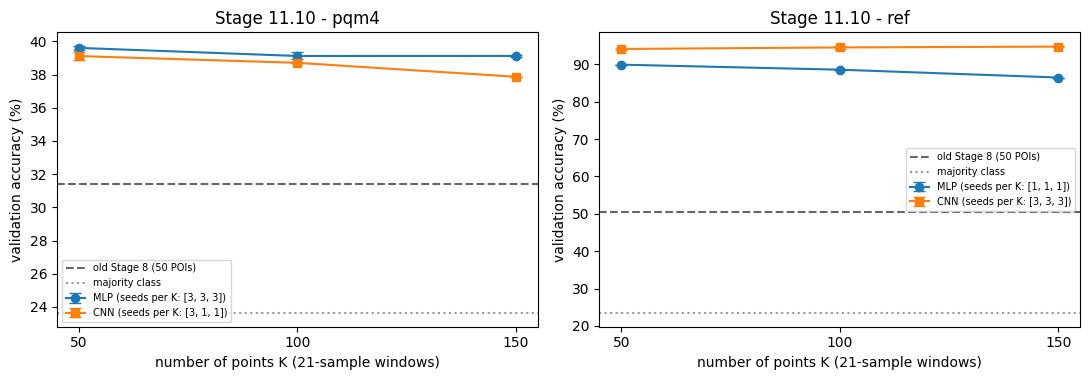


Saved: stage11_results_table.csv, fig_acc_vs_K.png (in /content/drive/MyDrive/mlkem_dataset/stage11 )


In [11]:
# ===========================================================
# STAGE 11.10 - Final results table + accuracy-vs-K figure (for the report)
# ===========================================================
import numpy as np, pandas as pd, matplotlib.pyplot as plt

dataset_dir = "/content/drive/MyDrive/mlkem_dataset"
out_dir  = dataset_dir + "/stage11"
eval_dir, att_dir = out_dir + "/eval", out_dir + "/attack"
idx = ["impl", "arch", "K"]

log = pd.read_csv(out_dir + "/train_log.csv")
log = log[log["tag"] == "base"].drop_duplicates(["impl", "arch", "K", "seed"], keep="last")
val = log.groupby(idx).agg(params=("params", "first"), n_seeds=("seed", "count"),
                           val_acc_mean=("val_acc", "mean"), val_acc_std=("val_acc", "std"))
test = pd.read_csv(eval_dir + "/eval_test_agg.csv").set_index(idx)[["T", "acc_mean", "acc_std", "pi_mean"]]
test.columns = ["T_mean", "test_acc_mean", "test_acc_std", "PI_bits"]
ens = pd.read_csv(eval_dir + "/eval_test_ensemble.csv").set_index(idx)[["test_acc", "pi_bits"]]
ens.columns = ["ens_test_acc", "ens_PI_bits"]
att = pd.read_csv(att_dir + "/attack_results.csv").set_index(idx)[
    ["acc_attack", "N_ge0_corr", "final_rank_corr", "SRcorr_n1", "SRcorr_n10", "SRcorr_n100"]]
table = val.join(test).join(ens).join(att).round(4)
table.to_csv(out_dir + "/stage11_results_table.csv")
pd.set_option("display.width", 250)
print("=== STAGE 11.10 - master results table (validation / test / attack) ===")
print(table.to_string())

old = pd.read_csv(att_dir + "/attack_results_old.csv")
print("\n=== old Stage 8 models on the full attack set ===")
print(old[["impl", "model", "acc_attack", "final_rank_corr", "decision_full_corr", "SRcorr_n100"]].to_string(index=False))

# accuracy vs number of points
OLD_VAL = {"pqm4": 0.3142, "ref": 0.5045}       # Stage 8, 50 baseline POIs
MAJ     = {"pqm4": 0.2361, "ref": 0.2337}
v = val.reset_index()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
for ax, impl in zip(axes, ["pqm4", "ref"]):
    for arch, mk in [("mlp", "o"), ("cnn", "s")]:
        s = v[(v.impl == impl) & (v.arch == arch)].sort_values("K")
        if s.empty:
            continue
        ax.errorbar(s.K, 100 * s.val_acc_mean, yerr=100 * s.val_acc_std.fillna(0), marker=mk, capsize=4,
                    label=f"{arch.upper()} (seeds per K: {s.n_seeds.tolist()})")
    ax.axhline(100 * OLD_VAL[impl], ls="--", color="0.4", label="old Stage 8 (50 POIs)")
    ax.axhline(100 * MAJ[impl], ls=":", color="0.6", label="majority class")
    ax.set_xticks([50, 100, 150]); ax.set_xlabel("number of points K (21-sample windows)")
    ax.set_ylabel("validation accuracy (%)"); ax.set_title(f"Stage 11.10 - {impl}")
    ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(out_dir + "/fig_acc_vs_K.png", dpi=150); plt.show()
print("\nSaved: stage11_results_table.csv, fig_acc_vs_K.png (in", out_dir, ")")